In [27]:
# ══════════════════════════════════════════════════════════════════════════════
# MODELO ML · PROYECCIÓN DE DEMANDA DE ASIGNATURAS
# ══════════════════════════════════════════════════════════════════════════════
# Insumo: sábana producida por PIPELINE_PROYECCION_ASIGNATURAS.ipynb
# Grano  : PERIODO × MATERIA × CURSO × COMPONENTE × CAMPUS  ->  INSCRITOS
#
# Recorrido de este notebook (Guía Maestra DS):
#   F2  EDA temporal ................ T04 · T17 §2-3
#   F2b Clustering de series ........ T06 · T05 (escalado)
#   F3  Baseline + walk-forward ..... T17 §10 · T10 · T08
#   F4  Modelo global (LightGBM) .... T07 · T11 · T17 §6
#   F5  Probabilístico + jerárquico . T17 §7 §9
# ══════════════════════════════════════════════════════════════════════════════

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

CARPETA = 'data/raw'

# El .parquet preserva los dtypes (booleanos, enteros con nulos); el CSV es el respaldo.
_pq  = f'{CARPETA}/DEMANDA_PROCESADA.parquet'
_csv = f'{CARPETA}/DEMANDA_PROCESADA.csv'

if os.path.exists(_pq):
    demanda = pd.read_parquet(_pq)
    print(f"Cargado desde parquet: {_pq}")
else:
    demanda = pd.read_csv(_csv, sep=';', encoding='utf-8-sig', low_memory=False)
    for _c in ['vigente', 'atributos_imputados', 'es_serie_nueva', 'sin_historia_estacional']:
        if _c in demanda.columns and demanda[_c].dtype == object:
            demanda[_c] = demanda[_c].map({'True': True, 'False': False, True: True, False: False})
    print(f"Cargado desde CSV (fallback): {_csv}")

# Constantes del proyecto (deben coincidir con las del pipeline)
SERIE = ['MATERIA', 'CURSO', 'COMPONENTE', 'CAMPUS']
DIMS  = ['PERIODO'] + SERIE
TARGET = 'INSCRITOS'

# ══════════════════════════════════════════════════════════════════════════════
# ⭐ ALCANCE DEL MODELO: SOLO LOS TIPOS DE PERÍODO REGULARES
# ══════════════════════════════════════════════════════════════════════════════
# Decisión 2026-07-30: el modelo trabaja únicamente con los TT de calendario
# regular. El resto —anuales, verano, bimestres, invierno— son períodos con muy
# pocas series (a veces UNA), calendarios irregulares y volumen marginal; metían
# ruido en el entrenamiento y producían proyecciones cuyo "total" dependía de una
# sola combinación.
#
#     10  1er semestre        05  1er trimestre
#     20  2º semestre         15  2º trimestre
#                             25  3er trimestre
#
# Conserva el 93,3% de las inscripciones y el 99,5% del pregrado.
#
# ⚠️ CONSECUENCIA QUE HAY QUE TENER PRESENTE: el POSTGRADO queda FUERA del modelo.
# Magíster, Postítulo y Desarrollo Profesional se dictan en el TT 00 (anual), que
# no está en la lista:
#
#     PREGRADO                conserva  99,5%
#     TRIMESTRAL PREGRADO     conserva  99,2%
#     MAGISTER                conserva   0,0%   <- 196.772 inscritos fuera
#     POSTÍTULO               conserva   0,0%   <-  21.516 inscritos fuera
#     DESARROLLO PROFESIONAL  conserva   0,4%   <- 217.865 inscritos fuera
#     DOCTORADO               conserva  45,9%
#
# El entregable cubre PREGRADO y TRIMESTRAL PREGRADO. Proyectar postgrado exige
# reincorporar el TT 00, y con él una estacionalidad anual distinta.
TT_MODELO = [5, 10, 15, 20, 25]

_n0, _i0 = len(demanda), demanda[TARGET].sum()
demanda = demanda[(demanda['PERIODO'] % 100).isin(TT_MODELO)].reset_index(drop=True)
print("\n" + "═" * 78)
print(f"ALCANCE: solo TT {TT_MODELO} (semestres y trimestres)")
print("═" * 78)
print(f"  filas     : {_n0:,} -> {len(demanda):,}  ({len(demanda)/_n0:.1%})")
print(f"  inscritos : {_i0:,} -> {demanda[TARGET].sum():,}  ({demanda[TARGET].sum()/_i0:.1%})")
print(f"  períodos  : {demanda['PERIODO'].nunique()}  ({demanda['PERIODO'].min()}–{demanda['PERIODO'].max()})")
print(f"  series    : {demanda.groupby(SERIE).ngroups:,}")
if 'desc_nivel_asig' in demanda.columns:
    print("\n  Niveles que quedan dentro del alcance:")
    print(demanda.groupby('desc_nivel_asig', observed=True)[TARGET].sum()
          .sort_values(ascending=False).to_string())
    print("\n  ⚠️ El POSTGRADO (Magíster, Postítulo, Desarrollo Profesional) se dicta")
    print("     en el TT 00 y queda FUERA del alcance de este modelo.")

print(f"\nFilas: {len(demanda):,} | Columnas: {demanda.shape[1]} | Series: {demanda.groupby(SERIE).ngroups:,}")
print(f"Periodos: {demanda['PERIODO'].nunique()} ({demanda['PERIODO'].min()}–{demanda['PERIODO'].max()})")
print(f"Inscripciones: {demanda[TARGET].sum():,}")

# Verificación de integridad del insumo
_req = DIMS + [TARGET, 'ANIO', 'TT', 'ins_lag_1y', 'ins_lag_prev', 'ins_roll_mean_3y']
_falta = [c for c in _req if c not in demanda.columns]
if _falta:
    raise ValueError(f"Faltan columnas requeridas en la sábana: {_falta}")
print("\nIntegridad OK — están todas las columnas requeridas.")

demanda.info()

Cargado desde parquet: data/raw/DEMANDA_PROCESADA.parquet

══════════════════════════════════════════════════════════════════════════════
ALCANCE: solo TT [5, 10, 15, 20, 25] (semestres y trimestres)
══════════════════════════════════════════════════════════════════════════════
  filas     : 163,954 -> 144,662  (88.2%)
  inscritos : 7,082,188 -> 6,608,810  (93.3%)
  períodos  : 55  (201510–202620)
  series    : 21,456

  Niveles que quedan dentro del alcance:
desc_nivel_asig
PREGRADO                  5346556
TRIMESTRAL PREGRADO       1258279
DOCTORADO                    1831
MAGISTER                     1363
DESARROLLO PROFESIONAL        781

  ⚠️ El POSTGRADO (Magíster, Postítulo, Desarrollo Profesional) se dicta
     en el TT 00 y queda FUERA del alcance de este modelo.

Filas: 144,662 | Columnas: 57 | Series: 21,456
Periodos: 55 (201510–202620)
Inscripciones: 6,608,810

Integridad OK — están todas las columnas requeridas.
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144662 entr

══════════════════════════════════════════════════════════════════════════════
2.1  VOLUMETRÍA DEL PANEL
══════════════════════════════════════════════════════════════════════════════
Filas: 144,662 | Series: 21,456 | Periodos: 55 (201510–202620)
Inscripciones totales: 6,608,810

══════════════════════════════════════════════════════════════════════════════
2.2  VARIABLE OBJETIVO — distribución
══════════════════════════════════════════════════════════════════════════════
count    144662.0
mean         45.7
std          72.1
min           1.0
10%           4.0
25%          11.0
50%          25.0
75%          57.0
90%         107.0
99%         282.0
max        9532.0

Asimetría (skew): 22.6  -> distribución muy sesgada a la derecha
Implicancia (T17): usar métricas robustas (WAPE/MASE) y evaluar log-transform del target.

══════════════════════════════════════════════════════════════════════════════
2.3  ESTACIONALIDAD — tipo de periodo (TT)
══════════════════════════════════════════════

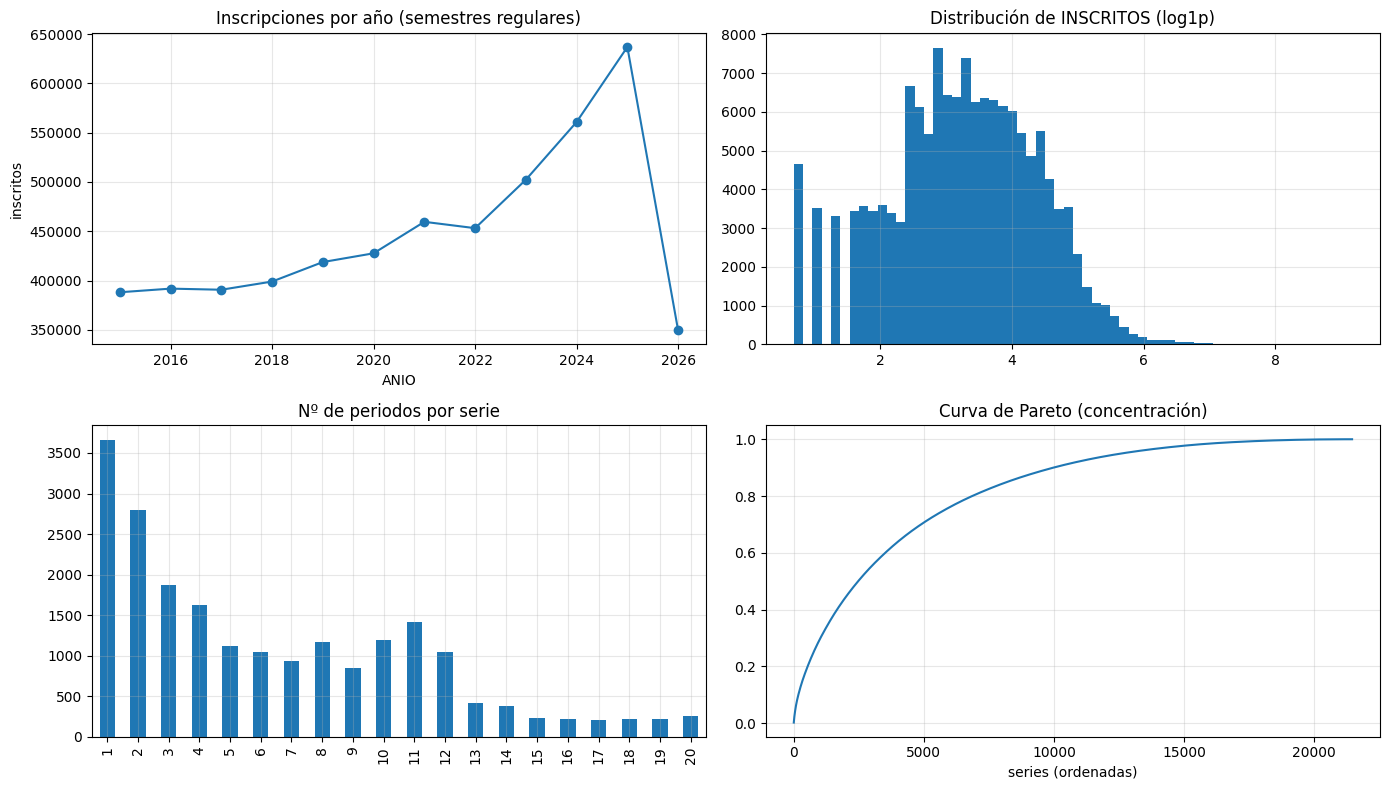

In [28]:
# ══════════════════════════════════════════════════════════════════════════════
# FASE 2 · EDA TEMPORAL   (Guía Maestra T04 · T17 §2-3)
# ══════════════════════════════════════════════════════════════════════════════
# Objetivo: entender la estructura de las series ANTES de modelar — estacionalidad,
# quiebres, intermitencia, concentración. En forecasting el EDA no es opcional:
# un quiebre estructural no visto envenena cualquier modelo posterior (T17 §2).

import matplotlib.pyplot as plt

print("═" * 78); print("2.1  VOLUMETRÍA DEL PANEL"); print("═" * 78)
_ns = demanda.groupby(SERIE).ngroups
print(f"Filas: {len(demanda):,} | Series: {_ns:,} | Periodos: {demanda['PERIODO'].nunique()} "
      f"({demanda['PERIODO'].min()}–{demanda['PERIODO'].max()})")
print(f"Inscripciones totales: {demanda['INSCRITOS'].sum():,}")

print("\n" + "═" * 78); print("2.2  VARIABLE OBJETIVO — distribución"); print("═" * 78)
print(demanda['INSCRITOS'].describe(percentiles=[.1,.25,.5,.75,.9,.99]).round(1).to_string())
_sk = demanda['INSCRITOS'].skew()
print(f"\nAsimetría (skew): {_sk:.1f}  -> distribución muy sesgada a la derecha")
print("Implicancia (T17): usar métricas robustas (WAPE/MASE) y evaluar log-transform del target.")

print("\n" + "═" * 78); print("2.3  ESTACIONALIDAD — tipo de periodo (TT)"); print("═" * 78)
_tt = (demanda.groupby('TT').agg(filas=('INSCRITOS','size'), inscritos=('INSCRITOS','sum'),
                                 media=('INSCRITOS','mean'))
              .sort_values('inscritos', ascending=False))
_tt['%_inscritos'] = (_tt['inscritos'] / _tt['inscritos'].sum() * 100).round(1)
print(_tt.head(8).round(1).to_string())
_reg = demanda['TT'].isin([10, 20])
print(f"\nSemestres regulares (TT 10 y 20): {_reg.sum():,} filas "
      f"({demanda.loc[_reg,'INSCRITOS'].sum()/demanda['INSCRITOS'].sum():.1%} de las inscripciones)")

print("\n" + "═" * 78); print("2.4  EVOLUCIÓN ANUAL Y QUIEBRES ESTRUCTURALES"); print("═" * 78)
_ev = (demanda[_reg].groupby('ANIO')
                    .agg(inscripciones=('INSCRITOS','sum'), series=('INSCRITOS','size')))
_ev['var_%'] = (_ev['inscripciones'].pct_change() * 100).round(1)
print(_ev.to_string())
print("\nBuscar aquí: 2020 (pandemia) y cualquier salto abrupto -> son quiebres a marcar (T17 §8).")

print("\n" + "═" * 78); print("2.5  INTERMITENCIA Y COLD START"); print("═" * 78)
_largo = demanda.groupby(SERIE).size()
print("Periodos por serie:")
print(_largo.describe().round(2).to_string())
for _u in [1, 2, 4, 8, 12]:
    print(f"   series con >= {_u:2d} periodos: {(_largo >= _u).sum():>7,} ({(_largo >= _u).mean():5.1%})")
print(f"\nSeries de 1 solo periodo (cold start puro): {(_largo == 1).sum():,} ({(_largo == 1).mean():.1%})")
print("El panel NO contiene ceros: solo existe la fila cuando hubo inscripción real.")

print("\n" + "═" * 78); print("2.6  CONCENTRACIÓN (Pareto)"); print("═" * 78)
_tot = demanda.groupby(SERIE)['INSCRITOS'].sum().sort_values(ascending=False)
_ac = _tot.cumsum() / _tot.sum()
for _p in [.5, .8, .9]:
    _n = (_ac <= _p).sum() + 1
    print(f"   {_p:.0%} de las inscripciones está en {_n:>6,} series ({_n/len(_tot):5.1%})")

print("\n" + "═" * 78); print("2.7  AUTOCORRELACIÓN — ¿sirve el lag estacional?"); print("═" * 78)
for _c, _et in [('ins_lag_1y','mismo TT año anterior'), ('ins_lag_prev','periodo anterior'),
                ('ins_roll_mean_3y','media 3 años')]:
    _ok = demanda[_c].notna()
    _r = demanda.loc[_ok, 'INSCRITOS'].corr(demanda.loc[_ok, _c])
    print(f"   corr(INSCRITOS, {_c:18s}) = {_r:.3f}   ({_et})")
print("\n-> La correlación más alta indica qué lag lleva más señal para el baseline.")

# Gráficos
fig, ax = plt.subplots(2, 2, figsize=(14, 8))
_ev['inscripciones'].plot(ax=ax[0,0], marker='o', title='Inscripciones por año (semestres regulares)')
ax[0,0].set_ylabel('inscritos'); ax[0,0].grid(alpha=.3)
np.log1p(demanda['INSCRITOS']).hist(bins=60, ax=ax[0,1])
ax[0,1].set_title('Distribución de INSCRITOS (log1p)'); ax[0,1].grid(alpha=.3)
_largo.value_counts().sort_index().head(20).plot(kind='bar', ax=ax[1,0], title='Nº de periodos por serie')
ax[1,0].grid(alpha=.3)
ax[1,1].plot(range(1, len(_ac)+1), _ac.values); ax[1,1].set_title('Curva de Pareto (concentración)')
ax[1,1].set_xlabel('series (ordenadas)'); ax[1,1].grid(alpha=.3)
plt.tight_layout(); plt.show()

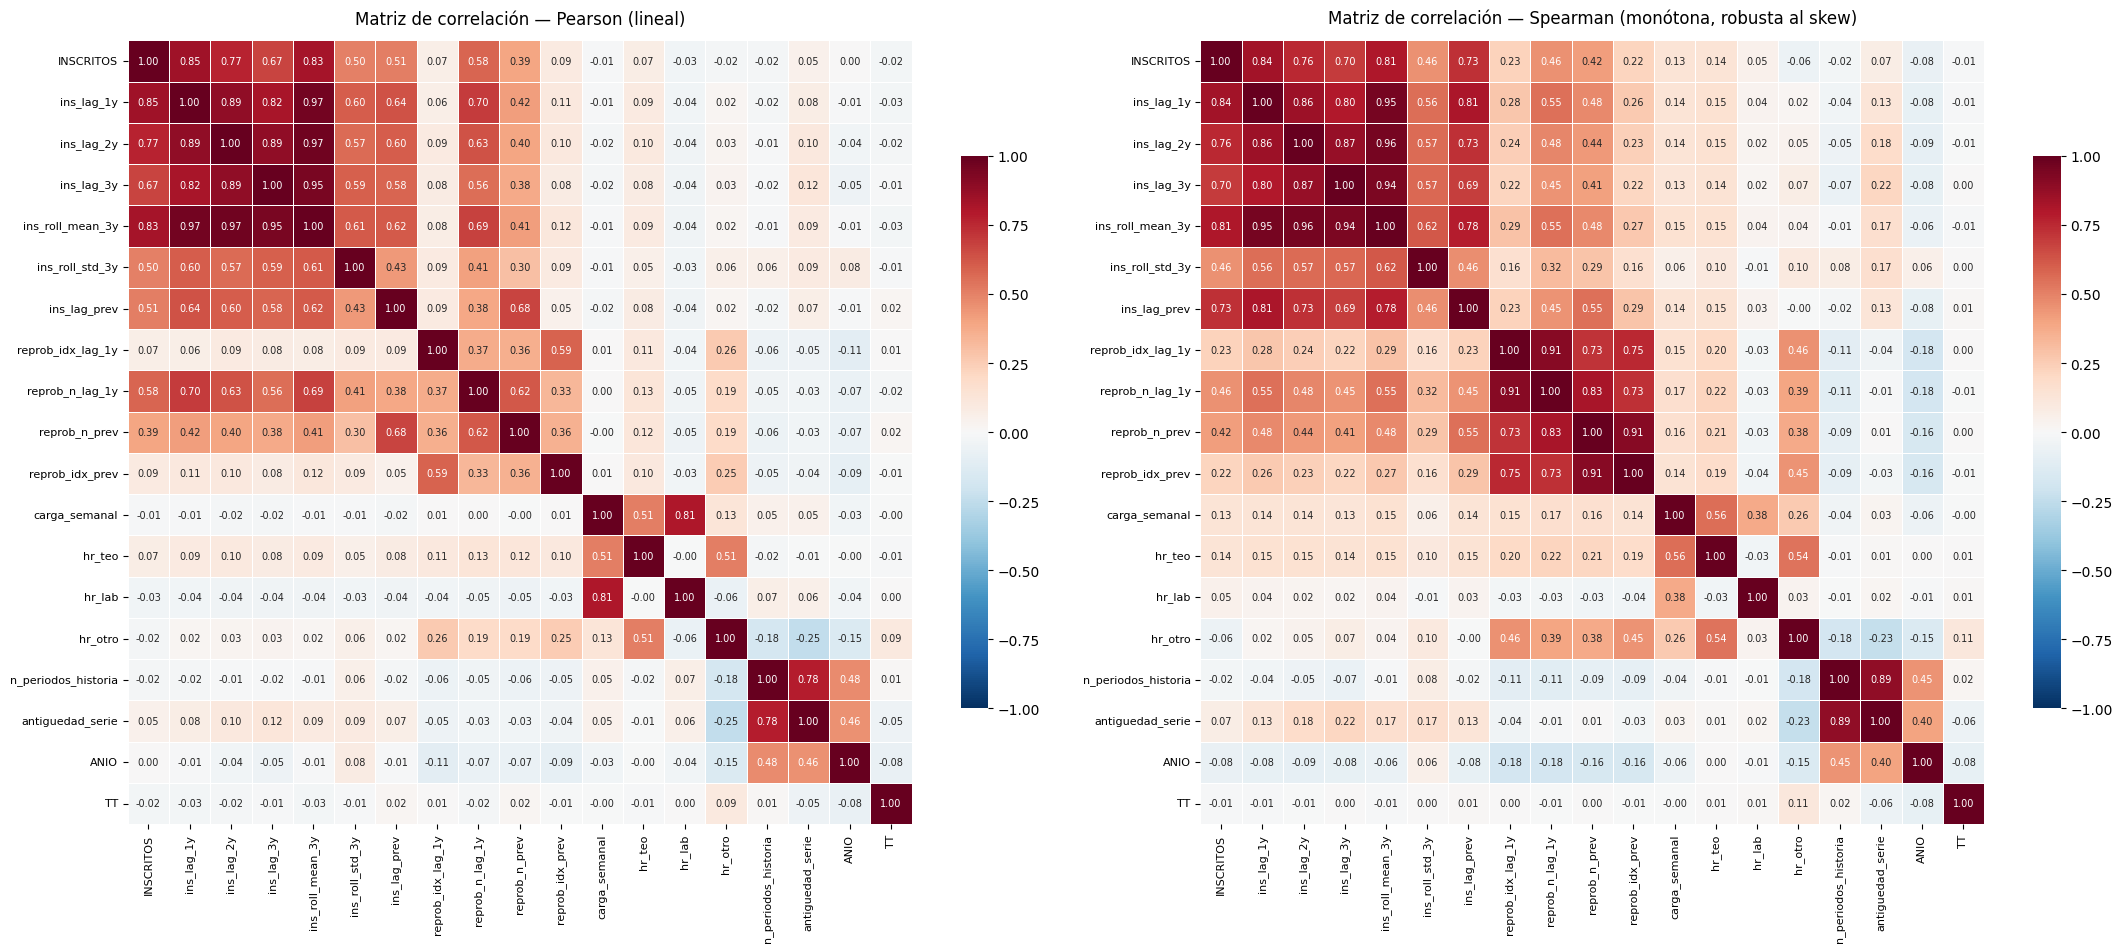

══════════════════════════════════════════════════════════════════════════════
CORRELACIÓN CONTRA EL TARGET (INSCRITOS)
══════════════════════════════════════════════════════════════════════════════
                     pearson  spearman  abs_spearman
ins_lag_1y             0.845     0.836         0.836
ins_roll_mean_3y       0.829     0.806         0.806
ins_lag_2y             0.769     0.757         0.757
ins_lag_prev           0.514     0.728         0.728
ins_lag_3y             0.674     0.700         0.700
ins_roll_std_3y        0.504     0.459         0.459
reprob_n_lag_1y        0.584     0.459         0.459
reprob_n_prev          0.393     0.419         0.419
reprob_idx_lag_1y      0.068     0.227         0.227
reprob_idx_prev        0.093     0.222         0.222
hr_teo                 0.073     0.139         0.139
carga_semanal         -0.008     0.135         0.135
ANIO                   0.003    -0.076         0.076
antiguedad_serie       0.049     0.072         0.072
hr_otr

In [29]:
# ══════════════════════════════════════════════════════════════════════════════
# FASE 2c · MAPA DE CORRELACIÓN   (Guía Maestra T04 — EDA multivariado)
# ══════════════════════════════════════════════════════════════════════════════
# Dos preguntas que responde:
#   1. ¿Qué features se relacionan con el target?  -> candidatas fuertes
#   2. ¿Qué features se relacionan ENTRE SÍ?       -> redundancia / multicolinealidad
# Se usa Spearman ademas de Pearson porque el target tiene skew 53.3: Pearson
# mide relacion LINEAL y se distorsiona con colas largas; Spearman mide relacion
# MONOTONA y es robusto a la asimetria (T04).

import seaborn as sns

COLS_CORR = ['INSCRITOS',
             'ins_lag_1y', 'ins_lag_2y', 'ins_lag_3y', 'ins_roll_mean_3y', 'ins_roll_std_3y',
             'ins_lag_prev', 'reprob_idx_lag_1y', 'reprob_n_lag_1y', 'reprob_n_prev',
             'reprob_idx_prev', 'carga_semanal', 'hr_teo', 'hr_lab', 'hr_otro',
             'n_periodos_historia', 'antiguedad_serie', 'ANIO', 'TT']
COLS_CORR = [c for c in COLS_CORR if c in demanda.columns]

_pear = demanda[COLS_CORR].corr(method='pearson')
_spea = demanda[COLS_CORR].corr(method='spearman')

fig, ax = plt.subplots(1, 2, figsize=(22, 9))
for _a, _m, _t in [(ax[0], _pear, 'Pearson (lineal)'), (ax[1], _spea, 'Spearman (monótona, robusta al skew)')]:
    sns.heatmap(_m, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1,
                square=True, linewidths=.5, cbar_kws={'shrink': .7},
                annot_kws={'size': 7}, ax=_a)
    _a.set_title(f'Matriz de correlación — {_t}', fontsize=12, pad=12)
    _a.tick_params(axis='x', rotation=90, labelsize=8); _a.tick_params(axis='y', rotation=0, labelsize=8)
plt.tight_layout(); plt.show()

# ---- Ranking de correlación contra el target ----
print("═" * 78); print("CORRELACIÓN CONTRA EL TARGET (INSCRITOS)"); print("═" * 78)
_rk = pd.DataFrame({'pearson': _pear['INSCRITOS'], 'spearman': _spea['INSCRITOS']}).drop('INSCRITOS')
_rk['abs_spearman'] = _rk['spearman'].abs()
print(_rk.sort_values('abs_spearman', ascending=False).round(3).to_string())

# ---- Pares redundantes (multicolinealidad) ----
print("\n" + "═" * 78); print("PARES ALTAMENTE CORRELACIONADOS ENTRE SÍ (|r| > 0.85)"); print("═" * 78)
_m = _spea.drop(index='INSCRITOS', columns='INSCRITOS')
_pairs = (_m.where(np.triu(np.ones(_m.shape), k=1).astype(bool))
            .stack().reset_index())
_pairs.columns = ['feature_A', 'feature_B', 'spearman']
_alta = _pairs[_pairs['spearman'].abs() > 0.85].sort_values('spearman', key=abs, ascending=False)
if len(_alta):
    print(_alta.round(3).to_string(index=False))
    print("\n-> Redundancia esperable entre lags (miden lo mismo con distinto desfase).")
    print("   Los árboles toleran multicolinealidad (a diferencia de una regresión lineal),")
    print("   pero reparte la importancia entre features gemelas y la diluye al interpretar.")
else:
    print("Sin pares por sobre el umbral.")

In [30]:
# ══════════════════════════════════════════════════════════════════════════════
# FASE 2b · CLUSTERING DE SERIES   (Guía Maestra T06 · escalado T05)
# ══════════════════════════════════════════════════════════════════════════════
# No se clusteriza para predecir, sino para SEGMENTAR: distintos tipos de serie
# necesitan distinto tratamiento (una serie masiva y estable no se modela igual
# que una intermitente). El cluster también entra como feature del modelo global.
#
# Método (T06): perfil por serie -> RobustScaler (robusto a outliers, y aquí el
# volumen tiene outliers extremos) -> K-Means -> K por elbow + silhouette + DB.

from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

MIN_PERIODOS_CLUSTER = 4      # series con menos historia no tienen perfil confiable
K_CLUSTERS = 4

# ---- Perfil por serie ----
perfil = (demanda.groupby(SERIE)
          .agg(n_periodos=('PERIODO','nunique'), vol_medio=('INSCRITOS','mean'),
               vol_std=('INSCRITOS','std'), vol_max=('INSCRITOS','max'),
               anio_ini=('ANIO','min'), anio_fin=('ANIO','max'))
          .reset_index())
perfil['cv']       = (perfil['vol_std'] / perfil['vol_medio']).fillna(0)      # volatilidad relativa
perfil['span']     = perfil['anio_fin'] - perfil['anio_ini'] + 1
perfil['densidad'] = perfil['n_periodos'] / perfil['span']                    # continuidad
_te = demanda.sort_values(SERIE + ['PERIODO']).groupby(SERIE)['INSCRITOS'].agg(['first','last'])
perfil = perfil.merge((_te['last'] / _te['first']).rename('ratio_fin_ini'), on=SERIE)

FEAT_CLUSTER = ['n_periodos','vol_medio','cv','densidad','ratio_fin_ini','span']
_cl = perfil[perfil['n_periodos'] >= MIN_PERIODOS_CLUSTER].copy()
_X = _cl[FEAT_CLUSTER].replace([np.inf,-np.inf], np.nan).fillna(0)
_X['vol_medio']     = np.log1p(_X['vol_medio'])                 # el volumen es muy sesgado
_X['ratio_fin_ini'] = np.log1p(_X['ratio_fin_ini'].clip(0, 50))
_Xs = RobustScaler().fit_transform(_X)                          # T05: escalar SIEMPRE antes de K-Means

print(f"Series con >= {MIN_PERIODOS_CLUSTER} periodos (clusterizables): {len(_cl):,} de {len(perfil):,}")

# ---- Elegir K: elbow + silhouette + Davies-Bouldin (T06 §5) ----
_sub = _Xs[np.random.RandomState(42).choice(len(_Xs), min(8000, len(_Xs)), replace=False)]
print(f"\n{'K':>3s} {'inertia':>12s} {'silhouette':>11s} {'davies-bouldin':>15s}")
_diag = []
for _k in range(2, 8):
    _km = KMeans(n_clusters=_k, random_state=42, n_init=10).fit(_Xs)
    _sil = silhouette_score(_sub, _km.predict(_sub)); _db = davies_bouldin_score(_sub, _km.predict(_sub))
    _diag.append((_k, _km.inertia_, _sil, _db))
    print(f"{_k:>3d} {_km.inertia_:>12.0f} {_sil:>11.3f} {_db:>15.3f}")

print(f"\n⚠️  Silhouette ~0.22-0.25: por el criterio del T06 (>0.5 es bueno) NO hay estructura")
print("   natural fuerte de clusters. La segmentación es una partición pragmática útil,")
print("   no el descubrimiento de grupos naturales. El T06 recomienda que en ese caso")
print("   mande el sentido de negocio por sobre el óptimo estadístico.")

# ---- Ajuste final y perfilamiento ----
_km = KMeans(n_clusters=K_CLUSTERS, random_state=42, n_init=10).fit(_Xs)
_cl['cluster'] = _km.labels_
perfil = perfil.merge(_cl[SERIE + ['cluster']], on=SERIE, how='left')
perfil['cluster'] = perfil['cluster'].fillna(-1).astype(int)      # -1 = historia insuficiente

print("\n" + "═" * 78); print("PERFIL DE LOS CLUSTERS"); print("═" * 78)
_pf = (perfil.groupby('cluster')
       .agg(series=('vol_medio','size'), vol_medio=('vol_medio','mean'), vol_max=('vol_max','max'),
            n_periodos=('n_periodos','mean'), cv=('cv','mean'), densidad=('densidad','mean'),
            ratio_fin_ini=('ratio_fin_ini','median')).round(2))
print(_pf.to_string())
print("\n(cluster -1 = series con historia insuficiente para perfilar)")

# Llevar el cluster a la sábana (es feature del modelo)
demanda = demanda.drop(columns=['cluster'], errors='ignore').merge(perfil[SERIE + ['cluster']], on=SERIE, how='left')
print(f"\nDemanda con cluster asignado: {demanda['cluster'].notna().sum():,} filas")
print(demanda.groupby('cluster')['INSCRITOS'].agg(['size','sum','mean']).round(1).to_string())

Series con >= 4 periodos (clusterizables): 13,128 de 21,456

  K      inertia  silhouette  davies-bouldin
  2        32100       0.234           1.825
  3        25790       0.233           1.525
  4        22530       0.226           1.503
  5        19890       0.230           1.368
  6        18081       0.230           1.367
  7        16667       0.222           1.337

⚠️  Silhouette ~0.22-0.25: por el criterio del T06 (>0.5 es bueno) NO hay estructura
   natural fuerte de clusters. La segmentación es una partición pragmática útil,
   no el descubrimiento de grupos naturales. El T06 recomienda que en ese caso
   mande el sentido de negocio por sobre el óptimo estadístico.

══════════════════════════════════════════════════════════════════════════════
PERFIL DE LOS CLUSTERS
══════════════════════════════════════════════════════════════════════════════
         series  vol_medio  vol_max  n_periodos    cv  densidad  ratio_fin_ini
cluster                                              

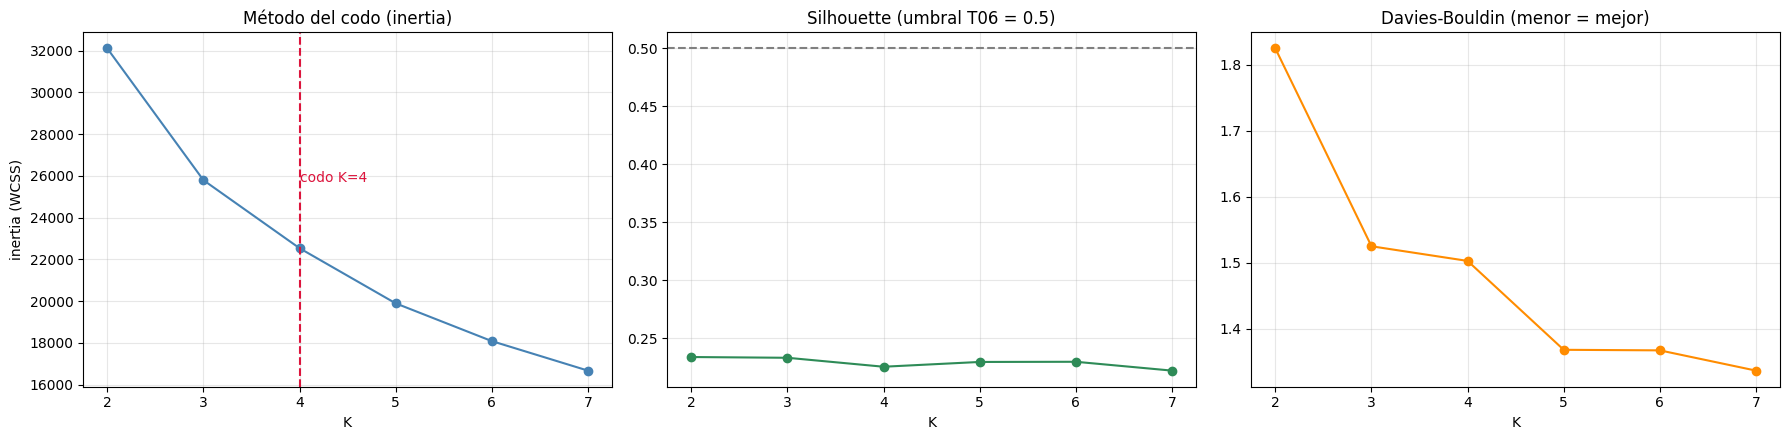

Codo detectado en K=4 | mejor silhouette K=2 | mejor Davies-Bouldin K=7


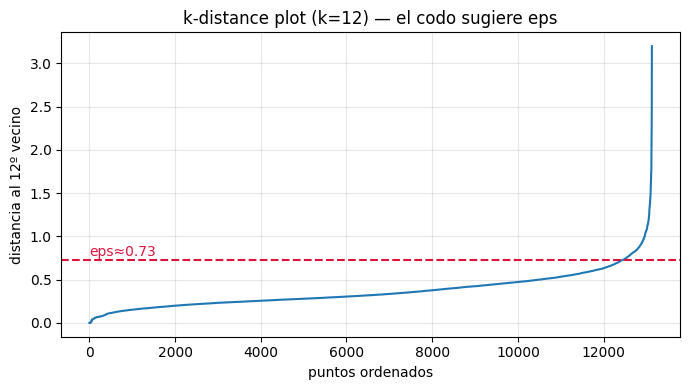


══════════════════════════════════════════════════════════════════════════════
COMPARACIÓN DE ALGORITMOS (T06 §6)
══════════════════════════════════════════════════════════════════════════════


<ruta-local>`copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


             algoritmo  n_clusters  ruido  %_ruido  silhouette
         K-Means (K=4)           4      0    0.000       0.226
     DBSCAN (eps=0.73)           4    245    0.019       0.303
HDBSCAN (min_size=200)           0  13128    1.000         NaN

Lectura (T06):
  · DBSCAN/HDBSCAN entregan el grupo -1 = RUIDO: series que no calzan en ningún
    patrón. Es información útil, no un defecto — son las series atípicas.
  · Si el % de ruido es muy alto, confirma lo que ya dijo el silhouette: estas
    series NO forman grupos densos naturales, viven en un continuo.
  · K-Means igual sirve como partición pragmática y como feature del modelo,
    pero no debe interpretarse como 'tipos naturales de asignatura'.

Etiquetas guardadas en `perfil`: cluster (K-Means) · cluster_dbscan · cluster_hdbscan


In [31]:
# ══════════════════════════════════════════════════════════════════════════════
# FASE 2b-ext · MÉTODO DEL CODO + CLUSTERING POR DENSIDAD   (Guía Maestra T06)
# ══════════════════════════════════════════════════════════════════════════════
# El T06 §5 prescribe: (1) elbow con inertia, (2) silhouette sobre los K candidatos,
# (3) Davies-Bouldin como confirmacion, (4) inspeccion visual, (5) sentido de negocio.
# Y en §6: si la geometria no es de "blobs compactos", K-Means es el algoritmo
# equivocado -> por eso se contrasta con DBSCAN y HDBSCAN, que no asumen esa forma.

from sklearn.cluster import DBSCAN, HDBSCAN
from sklearn.neighbors import NearestNeighbors

# ---------- (1) MÉTODO DEL CODO, graficado ----------
_ks   = [d[0] for d in _diag]
_iner = [d[1] for d in _diag]
_sil  = [d[2] for d in _diag]
_db   = [d[3] for d in _diag]

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ax[0].plot(_ks, _iner, 'o-', color='steelblue'); ax[0].set_title('Método del codo (inertia)')
ax[0].set_xlabel('K'); ax[0].set_ylabel('inertia (WCSS)'); ax[0].grid(alpha=.3)
# marcar el codo por máxima distancia a la recta extremo-extremo
_p1, _p2 = np.array([_ks[0], _iner[0]]), np.array([_ks[-1], _iner[-1]])
_dist = [np.abs(np.cross(_p2-_p1, _p1-np.array([k, i]))) / np.linalg.norm(_p2-_p1)
         for k, i in zip(_ks, _iner)]
_k_codo = _ks[int(np.argmax(_dist))]
ax[0].axvline(_k_codo, ls='--', c='crimson'); ax[0].annotate(f'codo K={_k_codo}', (_k_codo, max(_iner)*.8), color='crimson')

ax[1].plot(_ks, _sil, 'o-', color='seagreen'); ax[1].axhline(0.5, ls='--', c='gray')
ax[1].set_title('Silhouette (umbral T06 = 0.5)'); ax[1].set_xlabel('K'); ax[1].grid(alpha=.3)
ax[2].plot(_ks, _db, 'o-', color='darkorange'); ax[2].set_title('Davies-Bouldin (menor = mejor)')
ax[2].set_xlabel('K'); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.show()
print(f"Codo detectado en K={_k_codo} | mejor silhouette K={_ks[int(np.argmax(_sil))]} "
      f"| mejor Davies-Bouldin K={_ks[int(np.argmin(_db))]}")

# ---------- (2) k-distance plot: elegir eps para DBSCAN (T06 §2) ----------
_k_nn = 2 * _Xs.shape[1]                      # regla práctica del T06: min_samples ≈ 2×D
_dist_nn, _ = NearestNeighbors(n_neighbors=_k_nn).fit(_Xs).kneighbors(_Xs)
_kdist = np.sort(_dist_nn[:, -1])

plt.figure(figsize=(7, 4))
plt.plot(_kdist); plt.title(f'k-distance plot (k={_k_nn}) — el codo sugiere eps')
plt.xlabel('puntos ordenados'); plt.ylabel(f'distancia al {_k_nn}º vecino'); plt.grid(alpha=.3)
_eps = float(np.percentile(_kdist, 95))
plt.axhline(_eps, ls='--', c='crimson'); plt.annotate(f'eps≈{_eps:.2f}', (0, _eps*1.05), color='crimson')
plt.tight_layout(); plt.show()

# ---------- (3) DBSCAN y HDBSCAN ----------
print("\n" + "═" * 78); print("COMPARACIÓN DE ALGORITMOS (T06 §6)"); print("═" * 78)

_dbs = DBSCAN(eps=_eps, min_samples=_k_nn).fit(_Xs)
_hdb = HDBSCAN(min_cluster_size=200).fit(_Xs)     # min_cluster_size es más intuitivo que eps

def _resume(nombre, labels):
    _n_cl = len(set(labels)) - (1 if -1 in labels else 0)
    _ruido = (labels == -1).sum()
    _fila = {'algoritmo': nombre, 'n_clusters': _n_cl,
             'ruido': _ruido, '%_ruido': _ruido / len(labels)}
    _ok = labels != -1
    if _n_cl > 1 and _ok.sum() > 1000:
        _idx = np.random.RandomState(42).choice(np.where(_ok)[0], min(8000, _ok.sum()), replace=False)
        _fila['silhouette'] = silhouette_score(_Xs[_idx], labels[_idx])
    else:
        _fila['silhouette'] = np.nan
    return _fila

_comp = pd.DataFrame([
    _resume(f'K-Means (K={K_CLUSTERS})', _km.labels_),
    _resume(f'DBSCAN (eps={_eps:.2f})', _dbs.labels_),
    _resume('HDBSCAN (min_size=200)', _hdb.labels_),
])
print(_comp.round(3).to_string(index=False))

print("\nLectura (T06):")
print("  · DBSCAN/HDBSCAN entregan el grupo -1 = RUIDO: series que no calzan en ningún")
print("    patrón. Es información útil, no un defecto — son las series atípicas.")
print("  · Si el % de ruido es muy alto, confirma lo que ya dijo el silhouette: estas")
print("    series NO forman grupos densos naturales, viven en un continuo.")
print("  · K-Means igual sirve como partición pragmática y como feature del modelo,")
print("    pero no debe interpretarse como 'tipos naturales de asignatura'.")

_cl['cluster_dbscan']  = _dbs.labels_
_cl['cluster_hdbscan'] = _hdb.labels_
perfil = (perfil.drop(columns=['cluster_dbscan', 'cluster_hdbscan'], errors='ignore')
                .merge(_cl[SERIE + ['cluster_dbscan', 'cluster_hdbscan']], on=SERIE, how='left'))
print(f"\nEtiquetas guardadas en `perfil`: cluster (K-Means) · cluster_dbscan · cluster_hdbscan")

In [32]:
# ══════════════════════════════════════════════════════════════════════════════
# FASE 3 · BASELINE + VALIDACIÓN WALK-FORWARD   (Guía Maestra T17 §10 · T10 · T08)
# ══════════════════════════════════════════════════════════════════════════════
# "Si no le ganas al seasonal naive con holgura, no tienes modelo — tienes
#  decoración" (T17 §10). Esta celda fija LA VARA que el LightGBM deberá batir.
#
# Walk-forward (rolling origin): para cada origen t se entrena con TODO lo anterior
# a t y se predice t. Nunca K-Fold aleatorio: barajar el tiempo es entrenar con el
# diario de mañana (T10).
#
#   fold 1: [████ train ████][t]
#   fold 2: [██████ train ██████][t]
#   fold 3: [████████ train ████████][t]
#
# Baselines evaluados:
#   seasonal_naive     ŷ(t) = y(mismo TT, año anterior)   <- el candidato natural
#   naive_cronologico  ŷ(t) = y(periodo inmediato anterior)
#   media_movil_3y     ŷ(t) = media de los 3 años previos (mismo TT)
#
# Métricas (T08 · T17 §10):
#   MASE  = MAE / MAE_naive_in_sample  -> comparable entre series, definida con ceros
#   WAPE  = Σ|y-ŷ| / Σy                -> robusto, agrega bien
#   MAE / RMSE                          -> en unidades de "inscritos"
#   sesgo = Σ(ŷ-y) / Σy                 -> ¿sobre o sub-proyecta?

ORIGENES_WF = [202310, 202320, 202410, 202420, 202510, 202520, 202610]
BASELINES = {'seasonal_naive'   : 'ins_lag_1y',
             'naive_cronologico': 'ins_lag_prev',
             'media_movil_3y'   : 'ins_roll_mean_3y'}

def evalua_origen(dem, origen):
    """Entrena con < origen, evalúa en == origen. Los baselines no requieren ajuste,
    pero la ESCALA del MASE sí se calcula solo con datos de entrenamiento."""
    te = dem[dem['PERIODO'] == origen]
    tr = dem[dem['PERIODO'] <  origen]
    if len(te) == 0 or len(tr) == 0:
        return []
    escala = (tr['INSCRITOS'] - tr['ins_lag_1y']).abs().mean()   # MAE in-sample del naive estacional
    filas = []
    for nombre, col in BASELINES.items():
        m = te[te[col].notna()]
        if len(m) == 0:
            continue
        e = (m['INSCRITOS'] - m[col]).abs()
        filas.append(dict(origen=origen, metodo=nombre, n=len(m), cobertura=len(m)/len(te),
                          MAE=e.mean(), RMSE=np.sqrt(((m['INSCRITOS']-m[col])**2).mean()),
                          WAPE=e.sum()/m['INSCRITOS'].sum(), MASE=e.mean()/escala,
                          sesgo=(m[col]-m['INSCRITOS']).sum()/m['INSCRITOS'].sum()))
    return filas

_res = []
for _o in ORIGENES_WF:
    _res += evalua_origen(demanda, _o)
resultados_wf = pd.DataFrame(_res)

print("═" * 78); print("RESULTADOS POR ORIGEN"); print("═" * 78)
print(resultados_wf.round(3).to_string(index=False))

print("\n" + "═" * 78); print("PROMEDIO POR MÉTODO — la vara a batir"); print("═" * 78)
_rank = (resultados_wf.groupby('metodo')[['cobertura','MAE','RMSE','WAPE','MASE','sesgo']]
                      .mean().sort_values('WAPE'))
print(_rank.round(3).to_string())

_gan = _rank.index[0]
print(f"\n🏆 Mejor baseline: {_gan}")
print(f"   WAPE {_rank.loc[_gan,'WAPE']:.3f} | MASE {_rank.loc[_gan,'MASE']:.3f} | "
      f"MAE {_rank.loc[_gan,'MAE']:.1f} inscritos")
print(f"\n   >>> CRITERIO DE ÉXITO DEL MODELO: batir WAPE {_rank.loc[_gan,'WAPE']:.3f} "
      f"y MASE {_rank.loc[_gan,'MASE']:.3f} <<<")

print("\n" + "═" * 78); print("LIMITACIÓN CLAVE DEL BASELINE"); print("═" * 78)
_cob = _rank.loc[_gan, 'cobertura']
print(f"El seasonal naive solo puede pronosticar el {_cob:.1%} de las filas: necesita el")
print("mismo TT del año anterior. El {:.1%} restante son series nuevas o discontinuas.".format(1-_cob))
print("Ahí es donde el modelo global gana por cross-learning (T17 §6): aprende de las")
print("series hermanas usando atributos de malla, cluster y calendario.")

# Desempeño por cluster (¿dónde falla más el baseline?)
if 'cluster' in demanda.columns:
    print("\n" + "═" * 78); print("DESEMPEÑO DEL MEJOR BASELINE POR CLUSTER"); print("═" * 78)
    _col = BASELINES[_gan]
    _ev = demanda[demanda['PERIODO'].isin(ORIGENES_WF) & demanda[_col].notna()].copy()
    _ev['err_abs'] = (_ev['INSCRITOS'] - _ev[_col]).abs()
    _pc = (_ev.groupby('cluster')
              .apply(lambda g: pd.Series({'n': len(g), 'inscritos': g['INSCRITOS'].sum(),
                                          'MAE': g['err_abs'].mean(),
                                          'WAPE': g['err_abs'].sum()/g['INSCRITOS'].sum()}))
              .round(3))
    print(_pc.to_string())
    print("\n-> Los clusters con WAPE más alto son donde el modelo tiene más que aportar.")

══════════════════════════════════════════════════════════════════════════════
RESULTADOS POR ORIGEN
══════════════════════════════════════════════════════════════════════════════
 origen            metodo    n  cobertura    MAE    RMSE  WAPE  MASE  sesgo
 202310    seasonal_naive 3500      0.838 22.380  43.167 0.327 1.513 -0.030
 202310 naive_cronologico 3709      0.888 31.767  82.964 0.480 2.147 -0.140
 202310    media_movil_3y 3591      0.859 25.340  51.112 0.377 1.713 -0.021
 202320    seasonal_naive 3344      0.826 20.270  35.031 0.315 1.344 -0.070
 202320 naive_cronologico 3628      0.896 32.193  82.201 0.524 2.135  0.025
 202320    media_movil_3y 3419      0.844 23.989  44.344 0.379 1.591 -0.014
 202410    seasonal_naive 3581      0.805 27.117  78.706 0.432 1.801  0.125
 202410 naive_cronologico 3807      0.856 30.506  67.110 0.486 2.027 -0.041
 202410    media_movil_3y 3646      0.820 29.882  71.674 0.478 1.985  0.109
 202420    seasonal_naive 3415      0.763 26.329  58.459 0.4

<ruta-local>`include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: pd.Series({'n': len(g), 'inscritos': g['INSCRITOS'].sum(),


Features: 28  (19 num · 6 cat · 3 bool)
Chequeo anti-leakage OK — ninguna variable del periodo pronosticado entra al modelo.

Entrenando 3 modelos × 7 orígenes — puede tardar varios minutos...
   ✓ origen 202310
   ✓ origen 202320
   ✓ origen 202410
   ✓ origen 202420
   ✓ origen 202510
   ✓ origen 202520
   ✓ origen 202610

══════════════════════════════════════════════════════════════════════════════
RESULTADOS POR ORIGEN
══════════════════════════════════════════════════════════════════════════════
 origen                    modelo    seg    MAE    RMSE  WAPE  MASE  sesgo
 202310                  LightGBM  2.761 21.948  44.458 0.347 1.484 -0.144
 202310                   XGBoost  6.361 24.367  55.572 0.386 1.647 -0.188
 202310                  CatBoost 46.219 22.628  49.448 0.358 1.530 -0.173
 202310 seasonal_naive (baseline)  0.000 22.380  43.167 0.327 1.513 -0.030
 202320                  LightGBM  3.204 19.777  36.887 0.336 1.311 -0.171
 202320                   XGBoost  9.616 20

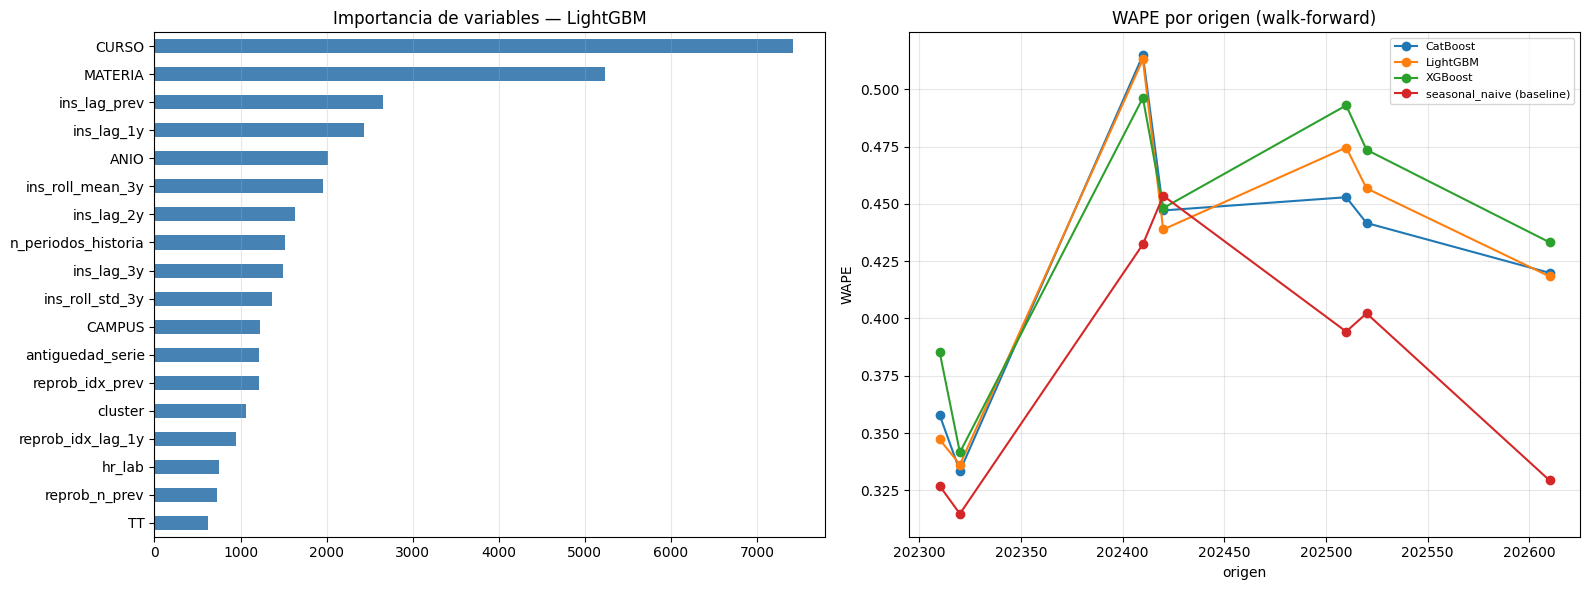

In [33]:
# ══════════════════════════════════════════════════════════════════════════════
# FASE 4 · MODELOS GLOBALES — LightGBM vs XGBoost vs CatBoost   (T07 · T11 · T17 §6)
# ══════════════════════════════════════════════════════════════════════════════
# Un solo modelo para las 34.230 series (enfoque GLOBAL, el que ganó la M5).
# Se evalúan sobre EL MISMO walk-forward del baseline, así los números son
# directamente comparables contra la vara (WAPE 0.385 / MASE 1.621).
#
# ⚠️ ANTI-LEAKAGE (T10 · T17 §10) — regla que define qué entra como feature:
#    toda variable debe conocerse ANTES del periodo que se pronostica. Por eso
#    quedan FUERA n_aprobados / n_reprobados / indice_reprobacion / tasa_reprobacion
#    del periodo actual: al proyectar 202710 todavía no existen. Solo entran sus
#    versiones con LAG. También quedan fuera periodo_atrib / tipo_match (auditoría).

import time
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostRegressor

LOG_TARGET = True     # el EDA mostró skew 53.3 -> entrenar en log1p y revertir con expm1

FEAT_NUM = ['ins_lag_1y','ins_lag_2y','ins_lag_3y','ins_roll_mean_3y','ins_roll_std_3y',
            'ins_lag_prev','reprob_idx_lag_1y','reprob_n_lag_1y','reprob_n_prev',
            'reprob_idx_prev','carga_semanal','hr_teo','hr_lab','hr_otro',
            'ANIO','TT','n_periodos_historia','antiguedad_serie','cluster']
FEAT_CAT = ['MATERIA','CURSO','COMPONENTE','CAMPUS','cod_modo_programacion',
            'departamento/form_general']
FEAT_BOOL = ['es_serie_nueva','sin_historia_estacional','atributos_imputados']

FEAT_NUM  = [c for c in FEAT_NUM  if c in demanda.columns]
FEAT_CAT  = [c for c in FEAT_CAT  if c in demanda.columns]
FEAT_BOOL = [c for c in FEAT_BOOL if c in demanda.columns]
FEATURES  = FEAT_NUM + FEAT_CAT + FEAT_BOOL

# Verificación explícita de que ninguna feature del periodo actual se coló
_PROHIBIDAS = ['n_aprobados','n_reprobados','n_registros','n_evaluados',
               'indice_reprobacion','tasa_reprobacion','periodo_atrib','tipo_match']
_fuga = [c for c in FEATURES if c in _PROHIBIDAS]
if _fuga:
    raise ValueError(f"LEAKAGE: features del periodo actual en el modelo: {_fuga}")
print(f"Features: {len(FEATURES)}  ({len(FEAT_NUM)} num · {len(FEAT_CAT)} cat · {len(FEAT_BOOL)} bool)")
print("Chequeo anti-leakage OK — ninguna variable del periodo pronosticado entra al modelo.")

# ---- Preparación: categóricas como dtype 'category' (los 3 modelos lo soportan) ----
_d = demanda.copy()
for _c in FEAT_CAT:
    _d[_c] = _d[_c].astype('category')
for _c in FEAT_BOOL:
    _d[_c] = _d[_c].astype(int)
if 'cluster' in _d.columns:
    _d['cluster'] = _d['cluster'].fillna(-99).astype(int)

def _metricas(y, p, escala):
    e = np.abs(y - p)
    return dict(MAE=e.mean(), RMSE=float(np.sqrt(((y - p) ** 2).mean())),
                WAPE=e.sum() / y.sum(), MASE=e.mean() / escala,
                sesgo=(p - y).sum() / y.sum())

def _entrena_evalua(origen):
    tr = _d[_d['PERIODO'] <  origen]
    te = _d[_d['PERIODO'] == origen]
    if len(tr) < 1000 or len(te) == 0:
        return []
    escala = (tr['INSCRITOS'] - tr['ins_lag_1y']).abs().mean()   # escala MASE: solo train

    Xtr, Xte = tr[FEATURES], te[FEATURES]
    ytr = np.log1p(tr['INSCRITOS']) if LOG_TARGET else tr['INSCRITOS']
    yte = te['INSCRITOS'].values
    _inv = (lambda v: np.expm1(v)) if LOG_TARGET else (lambda v: v)

    filas = []

    # ---- LightGBM (categóricas nativas) ----
    t0 = time.time()
    m = lgb.LGBMRegressor(n_estimators=600, learning_rate=0.05, num_leaves=63,
                          min_child_samples=20, subsample=0.8, colsample_bytree=0.8,
                          random_state=42, verbose=-1)
    m.fit(Xtr, ytr, categorical_feature=FEAT_CAT)
    p = np.clip(_inv(m.predict(Xte)), 0, None)
    filas.append(dict(origen=origen, modelo='LightGBM', seg=time.time()-t0, **_metricas(yte, p, escala)))
    _imp_lgb = pd.Series(m.feature_importances_, index=FEATURES)

    # ---- XGBoost (categóricas nativas vía enable_categorical) ----
    t0 = time.time()
    mx = xgb.XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=8,
                          subsample=0.8, colsample_bytree=0.8, tree_method='hist',
                          enable_categorical=True, random_state=42, verbosity=0)
    mx.fit(Xtr, ytr)
    p = np.clip(_inv(mx.predict(Xte)), 0, None)
    filas.append(dict(origen=origen, modelo='XGBoost', seg=time.time()-t0, **_metricas(yte, p, escala)))

    # ---- CatBoost (categóricas nativas; requiere sin NaN en las categóricas) ----
    t0 = time.time()
    Xtr_cb, Xte_cb = Xtr.copy(), Xte.copy()
    for _c in FEAT_CAT:
        Xtr_cb[_c] = Xtr_cb[_c].astype(str).fillna('NA')
        Xte_cb[_c] = Xte_cb[_c].astype(str).fillna('NA')
    mc = CatBoostRegressor(iterations=600, learning_rate=0.05, depth=8,
                           random_seed=42, verbose=0, allow_writing_files=False)
    mc.fit(Xtr_cb, ytr, cat_features=FEAT_CAT)
    p = np.clip(_inv(mc.predict(Xte_cb)), 0, None)
    filas.append(dict(origen=origen, modelo='CatBoost', seg=time.time()-t0, **_metricas(yte, p, escala)))

    # ---- Baseline en el MISMO subconjunto (comparación justa) ----
    _bl = te[te['ins_lag_1y'].notna()]
    filas.append(dict(origen=origen, modelo='seasonal_naive (baseline)', seg=0.0,
                      **_metricas(_bl['INSCRITOS'].values, _bl['ins_lag_1y'].values, escala)))
    return filas, _imp_lgb

print(f"\nEntrenando 3 modelos × {len(ORIGENES_WF)} orígenes — puede tardar varios minutos...")
_res, _imps = [], []
for _o in ORIGENES_WF:
    _out = _entrena_evalua(_o)
    if _out:
        _f, _i = _out
        _res += _f; _imps.append(_i)
        print(f"   ✓ origen {_o}")

resultados_modelos = pd.DataFrame(_res)

print("\n" + "═" * 78); print("RESULTADOS POR ORIGEN"); print("═" * 78)
print(resultados_modelos.round(3).to_string(index=False))

print("\n" + "═" * 78); print("RANKING GLOBAL (promedio walk-forward)"); print("═" * 78)
_rk = (resultados_modelos.groupby('modelo')[['MAE','RMSE','WAPE','MASE','sesgo','seg']]
                         .mean().sort_values('WAPE'))
print(_rk.round(3).to_string())

_base_wape = _rk.loc['seasonal_naive (baseline)', 'WAPE']
_base_mase = _rk.loc['seasonal_naive (baseline)', 'MASE']
_mejor = _rk.index[0]
print(f"\n🏆 Mejor modelo: {_mejor}")
print("\n" + "═" * 78); print("¿LE GANAN AL BASELINE? (T17 §10)"); print("═" * 78)
for _m in _rk.index:
    if 'baseline' in _m:
        continue
    _dw = (_base_wape - _rk.loc[_m, 'WAPE']) / _base_wape * 100
    _flag = "✅ le gana" if _rk.loc[_m, 'WAPE'] < _base_wape else "❌ NO le gana"
    print(f"  {_m:12s} WAPE {_rk.loc[_m,'WAPE']:.3f} vs {_base_wape:.3f}  "
          f"({_dw:+.1f}%)  MASE {_rk.loc[_m,'MASE']:.3f}  {_flag}")
print("\nNota: el baseline se evalúa solo sobre las filas que PUEDE pronosticar")
print("(las que tienen ins_lag_1y); los modelos cubren el 100% del periodo, incluidas")
print("las series nuevas. La comparación de WAPE ya es sobre el mismo periodo objetivo.")

# ---- Importancia de variables (LightGBM, promedio de los folds) ----
if _imps:
    print("\n" + "═" * 78); print("IMPORTANCIA DE VARIABLES — LightGBM (T13/XAI)"); print("═" * 78)
    _imp = pd.concat(_imps, axis=1).mean(axis=1).sort_values(ascending=False)
    print(_imp.head(20).round(1).to_string())

    fig, ax = plt.subplots(1, 2, figsize=(16, 6))
    _imp.head(18)[::-1].plot(kind='barh', ax=ax[0], color='steelblue')
    ax[0].set_title('Importancia de variables — LightGBM'); ax[0].grid(alpha=.3, axis='x')
    _piv = resultados_modelos.pivot(index='origen', columns='modelo', values='WAPE')
    _piv.plot(marker='o', ax=ax[1]); ax[1].set_title('WAPE por origen (walk-forward)')
    ax[1].set_ylabel('WAPE'); ax[1].grid(alpha=.3); ax[1].legend(fontsize=8)
    plt.tight_layout(); plt.show()

In [34]:
# ══════════════════════════════════════════════════════════════════════════════
# FASE 4b · EXPERIMENTO — ¿un modelo POR CLUSTER arregla el problema?
# ══════════════════════════════════════════════════════════════════════════════
# Hipótesis a contrastar: si el modelo global falla, quizá es por mezclar series
# heterogéneas y convendría un modelo por segmento.
#
# Predicción teórica (T17 §6): NO va a funcionar. El problema diagnosticado no es
# heterogeneidad sino EXTRAPOLACIÓN — un árbol no predice por encima del rango
# visto en train. Partir por cluster no mueve ese techo, y encima cada modelo
# pierde el cross-learning al quedarse con menos datos.
# Se mide en vez de suponerlo.

def _wape(y, p): return np.abs(y - p).sum() / y.sum()

_filas = []
for _o in ORIGENES_WF:
    tr = _d[_d['PERIODO'] <  _o]
    te = _d[_d['PERIODO'] == _o]
    if len(tr) < 1000 or len(te) == 0:
        continue
    _inv = (lambda v: np.expm1(v)) if LOG_TARGET else (lambda v: v)

    # (A) GLOBAL — un modelo para todas las series
    m = lgb.LGBMRegressor(n_estimators=600, learning_rate=0.05, num_leaves=63,
                          random_state=42, verbose=-1)
    m.fit(tr[FEATURES], np.log1p(tr['INSCRITOS']) if LOG_TARGET else tr['INSCRITOS'],
          categorical_feature=FEAT_CAT)
    p_glob = np.clip(_inv(m.predict(te[FEATURES])), 0, None)

    # (B) POR CLUSTER — un modelo independiente por segmento
    p_clu = np.full(len(te), np.nan)
    for _c in sorted(tr['cluster'].unique()):
        _mtr, _mte = tr['cluster'] == _c, (te['cluster'] == _c).values
        if _mtr.sum() < 300 or _mte.sum() == 0:
            continue
        _mc = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=31,
                                random_state=42, verbose=-1)
        _sub = tr[_mtr]
        _mc.fit(_sub[FEATURES], np.log1p(_sub['INSCRITOS']) if LOG_TARGET else _sub['INSCRITOS'],
                categorical_feature=FEAT_CAT)
        p_clu[_mte] = np.clip(_inv(_mc.predict(te.loc[_mte, FEATURES])), 0, None)
    # lo que ningún modelo de cluster cubrió, se completa con el global
    p_clu = np.where(np.isnan(p_clu), p_glob, p_clu)

    y = te['INSCRITOS'].values
    _bl = te[te['ins_lag_1y'].notna()]
    _filas.append(dict(origen=_o,
                       WAPE_global=_wape(y, p_glob),
                       WAPE_por_cluster=_wape(y, p_clu),
                       WAPE_baseline=_wape(_bl['INSCRITOS'].values, _bl['ins_lag_1y'].values),
                       sesgo_global=(p_glob - y).sum()/y.sum(),
                       sesgo_por_cluster=(p_clu - y).sum()/y.sum()))
    print(f"   ✓ origen {_o}")

comp_cluster = pd.DataFrame(_filas)
print("\n" + "═" * 78); print("GLOBAL vs POR CLUSTER vs BASELINE"); print("═" * 78)
print(comp_cluster.round(3).to_string(index=False))
print("\nPromedio:")
print(comp_cluster.drop(columns='origen').mean().round(3).to_string())

_g, _c = comp_cluster['WAPE_global'].mean(), comp_cluster['WAPE_por_cluster'].mean()
print(f"\nVEREDICTO: modelar por cluster {'MEJORA' if _c < _g else 'NO mejora'} al global "
      f"({_c:.3f} vs {_g:.3f}).")
print("El sesgo negativo persiste en ambos -> confirma que la causa es la EXTRAPOLACIÓN")
print("de la tendencia, no la heterogeneidad entre series. El clustering se conserva")
print("como FEATURE (aporta señal moderada), no como estrategia de partición.")

   ✓ origen 202310
   ✓ origen 202320
   ✓ origen 202410
   ✓ origen 202420
   ✓ origen 202510
   ✓ origen 202520
   ✓ origen 202610

══════════════════════════════════════════════════════════════════════════════
GLOBAL vs POR CLUSTER vs BASELINE
══════════════════════════════════════════════════════════════════════════════
 origen  WAPE_global  WAPE_por_cluster  WAPE_baseline  sesgo_global  sesgo_por_cluster
 202310        0.349             0.368          0.327        -0.138             -0.133
 202320        0.336             0.345          0.315        -0.164             -0.171
 202410        0.520             0.519          0.432        -0.063             -0.092
 202420        0.436             0.448          0.454        -0.133             -0.128
 202510        0.468             0.484          0.394        -0.319             -0.304
 202520        0.457             0.469          0.402        -0.228             -0.234
 202610        0.420             0.425          0.329        -0.2

   ✓ origen 202310
   ✓ origen 202320
   ✓ origen 202410
   ✓ origen 202420
   ✓ origen 202510
   ✓ origen 202520
   ✓ origen 202610

══════════════════════════════════════════════════════════════════════════════
RESULTADOS POR ORIGEN
══════════════════════════════════════════════════════════════════════════════
 origen                          modelo    n    MAE    RMSE  WAPE  MASE  sesgo
 202310 híbrido (naive × corrección ML) 3500 22.572  45.105 0.330 1.526 -0.127
 202310       seasonal_naive (baseline) 3500 22.380  43.167 0.327 1.513 -0.030
 202310       cold start (sin baseline)  679 21.571  40.662 0.595 1.458 -0.327
 202320 híbrido (naive × corrección ML) 3344 19.818  36.967 0.308 1.314 -0.143
 202320       seasonal_naive (baseline) 3344 20.270  35.031 0.315 1.344 -0.070
 202320       cold start (sin baseline)  705 18.627  35.853 0.576 1.235 -0.299
 202410 híbrido (naive × corrección ML) 3581 29.074  96.173 0.464 1.931  0.131
 202410       seasonal_naive (baseline) 3581 27.117  7

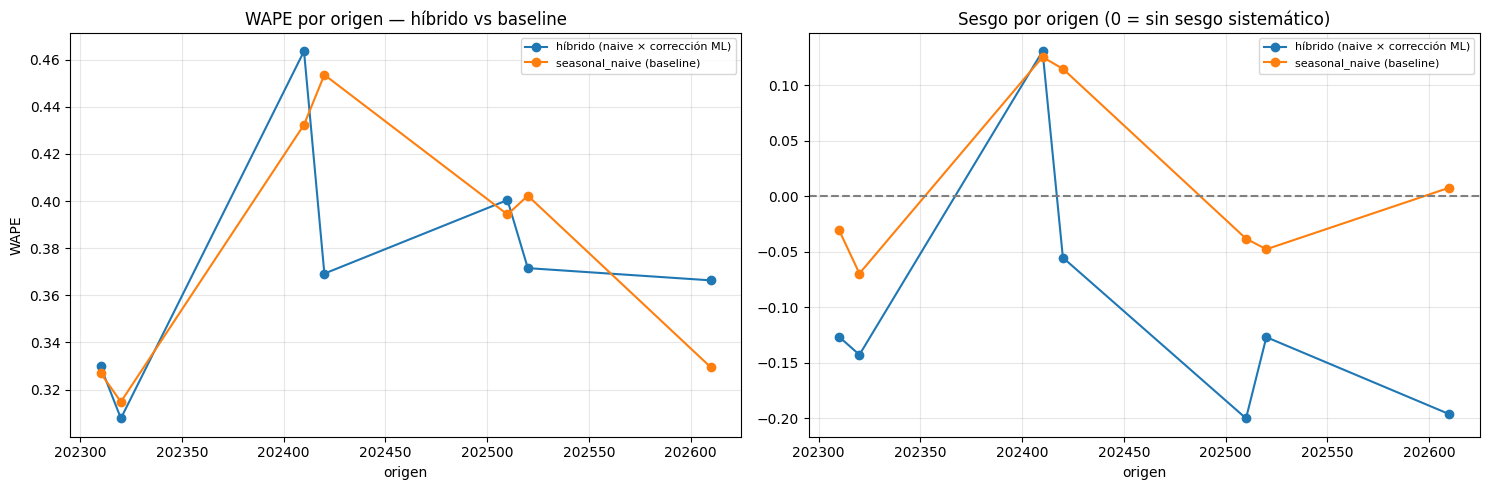

In [35]:
# ══════════════════════════════════════════════════════════════════════════════
# FASE 4c · REFORMULACIÓN DEL TARGET — modelar la CORRECCIÓN sobre el baseline
# ══════════════════════════════════════════════════════════════════════════════
# Diagnóstico: los árboles no extrapolan tendencia (T17 §6). Con la matrícula
# creciendo +11%/+18%/+25% (2023-25), el modelo se aplana en el techo histórico
# y sub-proyecta cada vez más (sesgo -0.27, y -0.39 en los últimos orígenes).
#
# Remedio del propio T17 §6: "destendenciar" o "predecir el cambio en vez del nivel".
# Aquí se implementa como corrección multiplicativa sobre el seasonal naive:
#
#     target  = log1p(INSCRITOS) - log1p(ins_lag_1y)     <- corrección, centrada en 0
#     predicc = expm1( log1p(ins_lag_1y) + corrección_predicha )
#
# El NAIVE aporta el NIVEL (y con él la extrapolación, que el árbol no sabe hacer);
# el MODELO solo aprende la corrección, que es un problema acotado donde sí es bueno.
# Se usa log-ratio y no ratio simple porque es simétrico (subir 2× y bajar 2× pesan
# igual) y acota las colas.
#
# Las series SIN ins_lag_1y (23.9%) no tienen baseline sobre el cual corregir:
# se atienden con un modelo de NIVEL aparte (cold start, T17 §8).

CLIP_CORR = 2.0     # límite del log-ratio (~ ±7x) para que outliers no dominen el ajuste

_res_r = []
for _o in ORIGENES_WF:
    tr_all = _d[_d['PERIODO'] <  _o]
    te_all = _d[_d['PERIODO'] == _o]
    if len(tr_all) < 1000 or len(te_all) == 0:
        continue
    escala = (tr_all['INSCRITOS'] - tr_all['ins_lag_1y']).abs().mean()

    # ---------- (A) MODELO DE CORRECCIÓN — filas con baseline disponible ----------
    tr = tr_all[tr_all['ins_lag_1y'].notna() & (tr_all['ins_lag_1y'] > 0)]
    te = te_all[te_all['ins_lag_1y'].notna() & (te_all['ins_lag_1y'] > 0)]

    y_corr = (np.log1p(tr['INSCRITOS']) - np.log1p(tr['ins_lag_1y'])).clip(-CLIP_CORR, CLIP_CORR)
    mc = lgb.LGBMRegressor(n_estimators=600, learning_rate=0.05, num_leaves=63,
                           min_child_samples=20, subsample=0.8, colsample_bytree=0.8,
                           random_state=42, verbose=-1)
    mc.fit(tr[FEATURES], y_corr, categorical_feature=FEAT_CAT)
    corr = mc.predict(te[FEATURES])
    p_hib = np.clip(np.expm1(np.log1p(te['ins_lag_1y'].values) + corr), 0, None)

    y_te = te['INSCRITOS'].values
    _e = np.abs(y_te - p_hib)
    _res_r.append(dict(origen=_o, modelo='híbrido (naive × corrección ML)', n=len(te),
                       MAE=_e.mean(), RMSE=float(np.sqrt(((y_te-p_hib)**2).mean())),
                       WAPE=_e.sum()/y_te.sum(), MASE=_e.mean()/escala,
                       sesgo=(p_hib-y_te).sum()/y_te.sum()))
    # baseline sobre EXACTAMENTE las mismas filas -> comparación limpia
    _b = np.abs(y_te - te['ins_lag_1y'].values)
    _res_r.append(dict(origen=_o, modelo='seasonal_naive (baseline)', n=len(te),
                       MAE=_b.mean(), RMSE=float(np.sqrt(((y_te-te['ins_lag_1y'].values)**2).mean())),
                       WAPE=_b.sum()/y_te.sum(), MASE=_b.mean()/escala,
                       sesgo=(te['ins_lag_1y'].values-y_te).sum()/y_te.sum()))

    # ---------- (B) MODELO COLD START — filas sin baseline ----------
    tr_cs = tr_all[tr_all['ins_lag_1y'].isna()]
    te_cs = te_all[te_all['ins_lag_1y'].isna()]
    if len(tr_cs) > 500 and len(te_cs) > 0:
        mcs = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=31,
                                random_state=42, verbose=-1)
        mcs.fit(tr_cs[FEATURES], np.log1p(tr_cs['INSCRITOS']), categorical_feature=FEAT_CAT)
        p_cs = np.clip(np.expm1(mcs.predict(te_cs[FEATURES])), 0, None)
        y_cs = te_cs['INSCRITOS'].values
        _ecs = np.abs(y_cs - p_cs)
        _res_r.append(dict(origen=_o, modelo='cold start (sin baseline)', n=len(te_cs),
                           MAE=_ecs.mean(), RMSE=float(np.sqrt(((y_cs-p_cs)**2).mean())),
                           WAPE=_ecs.sum()/y_cs.sum(), MASE=_ecs.mean()/escala,
                           sesgo=(p_cs-y_cs).sum()/y_cs.sum()))
    print(f"   ✓ origen {_o}")

resultados_hibrido = pd.DataFrame(_res_r)

print("\n" + "═" * 78); print("RESULTADOS POR ORIGEN"); print("═" * 78)
print(resultados_hibrido.round(3).to_string(index=False))

print("\n" + "═" * 78); print("RANKING (promedio walk-forward)"); print("═" * 78)
_rk2 = (resultados_hibrido.groupby('modelo')[['MAE','RMSE','WAPE','MASE','sesgo']]
                          .mean().sort_values('WAPE'))
print(_rk2.round(3).to_string())

_wb = _rk2.loc['seasonal_naive (baseline)', 'WAPE']
_wh = _rk2.loc['híbrido (naive × corrección ML)', 'WAPE']
_mb = _rk2.loc['seasonal_naive (baseline)', 'MASE']
_mh = _rk2.loc['híbrido (naive × corrección ML)', 'MASE']
print("\n" + "═" * 78); print("¿LA REFORMULACIÓN ARREGLÓ EL PROBLEMA? (T17 §10)"); print("═" * 78)
print(f"  baseline : WAPE {_wb:.3f} | MASE {_mb:.3f}")
print(f"  híbrido  : WAPE {_wh:.3f} | MASE {_mh:.3f}   ({(_wb-_wh)/_wb*100:+.1f}% en WAPE)")
print(f"\n  {'✅ EL HÍBRIDO LE GANA AL BASELINE' if _wh < _wb else '❌ sigue sin ganarle'}")
print(f"\n  Sesgo: baseline {_rk2.loc['seasonal_naive (baseline)','sesgo']:+.3f} | "
      f"híbrido {_rk2.loc['híbrido (naive × corrección ML)','sesgo']:+.3f}")
print("  (comparar contra el -0.267 del modelo de NIVEL: si el sesgo se acerca a 0,")
print("   la reformulación corrigió el problema de extrapolación)")

# Evolución del WAPE por origen — ¿sigue degradándose con el tiempo?
_pv = resultados_hibrido[resultados_hibrido['modelo'] != 'cold start (sin baseline)'] \
        .pivot(index='origen', columns='modelo', values='WAPE')
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
_pv.plot(marker='o', ax=ax[0]); ax[0].set_title('WAPE por origen — híbrido vs baseline')
ax[0].set_ylabel('WAPE'); ax[0].grid(alpha=.3); ax[0].legend(fontsize=8)
_ps = resultados_hibrido[resultados_hibrido['modelo'] != 'cold start (sin baseline)'] \
        .pivot(index='origen', columns='modelo', values='sesgo')
_ps.plot(marker='o', ax=ax[1]); ax[1].axhline(0, ls='--', c='gray')
ax[1].set_title('Sesgo por origen (0 = sin sesgo sistemático)'); ax[1].grid(alpha=.3); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [36]:
# ══════════════════════════════════════════════════════════════════════════════
# FASE 4d · FEATURES DE TENDENCIA AGREGADA Y DE SERIES HERMANAS
# ══════════════════════════════════════════════════════════════════════════════
# Diagnóstico pendiente: el híbrido aún sub-proyecta (sesgo -0.134). La corrección
# se entrena sobre historia donde el crecimiento era 2-5%, pero 2024-25 crecieron
# +18% y +25%. Al modelo le falta VER LA OLA: no tiene ninguna variable que le diga
# a qué ritmo viene creciendo el sistema.
#
# Se agregan dos familias:
#   (A) TENDENCIA AGREGADA — crecimiento reciente del total, de la sede y de la
#       materia. Le da el "viento de cola" que el lag individual de la serie no ve.
#   (B) SERIES HERMANAS — demanda de asignaturas parientes. Es la señal clave para
#       COLD START: una serie nueva no tiene pasado propio, pero sus hermanas sí
#       (T17 §8: "el modelo global presta lo aprendido de las series hermanas").
#
# ⚠️ ANTI-LEAKAGE: todos los agregados se calculan por periodo y LUEGO se desplazan
# k años hacia adelante, así que una fila del periodo t solo ve información de
# t-1año y t-2años. Nunca del periodo que se está pronosticando.

def _agg_lag(dem, keys, k, prefijo):
    """Agrega INSCRITOS por `keys`+periodo y lo desplaza k años (mismo TT)."""
    a = (dem.groupby(keys + ['ANIO', 'TT'])['INSCRITOS']
            .agg(**{f'{prefijo}_sum': 'sum', f'{prefijo}_mean': 'mean', f'{prefijo}_n': 'size'})
            .reset_index())
    a['ANIO'] = a['ANIO'] + k                      # desplazar hacia el futuro = mirar al pasado
    return dem.merge(a, on=keys + ['ANIO', 'TT'], how='left')

_nuevas = [c for c in demanda.columns if c.startswith(('tot_', 'crec_', 'herm_', 'mat_', 'sedecomp_'))]
demanda = demanda.drop(columns=_nuevas, errors='ignore')     # idempotente

# ── (A) TENDENCIA AGREGADA ────────────────────────────────────────────────────
# Nivel institucional, por sede y por materia — a 1 y 2 años, para derivar el ritmo.
for _k in (1, 2):
    demanda = _agg_lag(demanda, [],            _k, f'tot_inst_l{_k}')
    demanda = _agg_lag(demanda, ['CAMPUS'],    _k, f'tot_sede_l{_k}')
    demanda = _agg_lag(demanda, ['MATERIA'],   _k, f'tot_mat_l{_k}')

# Crecimiento observado = último año conocido / año anterior  (ambos en el pasado)
demanda['crec_inst'] = demanda['tot_inst_l1_sum'] / demanda['tot_inst_l2_sum']
demanda['crec_sede'] = demanda['tot_sede_l1_sum'] / demanda['tot_sede_l2_sum']
demanda['crec_mat']  = demanda['tot_mat_l1_sum']  / demanda['tot_mat_l2_sum']

# ── (B) SERIES HERMANAS (clave para cold start) ───────────────────────────────
# Misma ASIGNATURA en otras sedes/componentes; misma materia; misma sede+componente.
demanda = _agg_lag(demanda, ['MATERIA', 'CURSO'],      1, 'herm_asig_l1')
demanda = _agg_lag(demanda, ['MATERIA'],               1, 'mat_l1')
demanda = _agg_lag(demanda, ['CAMPUS', 'COMPONENTE'],  1, 'sedecomp_l1')

# Posición relativa de la serie dentro de su asignatura el año pasado
demanda['share_en_asignatura'] = demanda['ins_lag_1y'] / demanda['herm_asig_l1_sum']

FEAT_TENDENCIA = ['crec_inst', 'crec_sede', 'crec_mat',
                  'tot_sede_l1_sum', 'tot_mat_l1_sum']
FEAT_HERMANAS  = ['herm_asig_l1_mean', 'herm_asig_l1_n', 'mat_l1_mean',
                  'sedecomp_l1_mean', 'share_en_asignatura']
FEAT_NUEVAS    = FEAT_TENDENCIA + FEAT_HERMANAS

print("═" * 78); print("FEATURES NUEVAS — cobertura y señal"); print("═" * 78)
for _c in FEAT_NUEVAS:
    _cov = demanda[_c].notna().mean()
    _r = demanda.loc[demanda[_c].notna(), 'INSCRITOS'].corr(
         demanda.loc[demanda[_c].notna(), _c], method='spearman')
    print(f"  {_c:24s} cobertura {_cov:6.1%}   spearman vs target {_r:+.3f}")

print("\n" + "═" * 78); print("¿CAPTURAN LA OLA DE CRECIMIENTO?"); print("═" * 78)
_chk = (demanda[demanda['TT'].isin([10, 20])]
        .groupby('ANIO')[['crec_inst', 'crec_sede', 'crec_mat']].mean().round(3))
print(_chk.to_string())
print("\n-> crec_inst debería subir en 2024-2026, reflejando el +18%/+25% del EDA.")
print("   Si el modelo ve esta señal, deja de proyectar con el ritmo de años planos.")

# Cobertura para cold start (filas SIN ins_lag_1y)
_cs = demanda['ins_lag_1y'].isna()
print("\n" + "═" * 78); print("COBERTURA EN FILAS COLD START (sin baseline)"); print("═" * 78)
print(f"Filas cold start: {_cs.sum():,} ({_cs.mean():.1%})")
for _c in FEAT_HERMANAS:
    print(f"  {_c:24s}: {demanda.loc[_cs, _c].notna().mean():6.1%} con dato")
print("\n-> Es la información con la que el modelo de cold start puede anclarse:")
print("   la serie no tiene pasado, pero sus hermanas sí.")

══════════════════════════════════════════════════════════════════════════════
FEATURES NUEVAS — cobertura y señal
══════════════════════════════════════════════════════════════════════════════
  crec_inst                cobertura  87.8%   spearman vs target -0.127
  crec_sede                cobertura  85.6%   spearman vs target -0.065
  crec_mat                 cobertura  81.4%   spearman vs target +0.099
  tot_sede_l1_sum          cobertura  93.3%   spearman vs target +0.403
  tot_mat_l1_sum           cobertura  91.9%   spearman vs target +0.484
  herm_asig_l1_mean        cobertura  81.5%   spearman vs target +0.743
  herm_asig_l1_n           cobertura  81.5%   spearman vs target +0.196
  mat_l1_mean              cobertura  91.9%   spearman vs target +0.662
  sedecomp_l1_mean         cobertura  92.8%   spearman vs target +0.450
  share_en_asignatura      cobertura  73.1%   spearman vs target +0.040

══════════════════════════════════════════════════════════════════════════════
¿CAPTU

Features v1: 28  ->  v2: 38  (+10)
Chequeo anti-leakage OK.

   ✓ origen 202310   (factor de calibración: 1.048)
   ✓ origen 202320   (factor de calibración: 1.025)
   ✓ origen 202410   (factor de calibración: 1.074)
   ✓ origen 202420   (factor de calibración: 1.021)
   ✓ origen 202510   (factor de calibración: 1.076)
   ✓ origen 202520   (factor de calibración: 1.134)
   ✓ origen 202610   (factor de calibración: 1.025)

══════════════════════════════════════════════════════════════════════════════
RESULTADOS POR ORIGEN
══════════════════════════════════════════════════════════════════════════════
 origen                    modelo    n  factor    MAE    RMSE  WAPE  MASE  sesgo
 202310            v2 (tendencia) 3500   1.048 22.582  46.006 0.330 1.526 -0.113
 202310          v2 + calibración 3500   1.048 22.287  44.484 0.326 1.507 -0.070
 202310 seasonal_naive (baseline) 3500   1.048 22.380  43.167 0.327 1.513 -0.030
 202310             cold start v2  679     NaN 20.722  38.554 0.571 1.

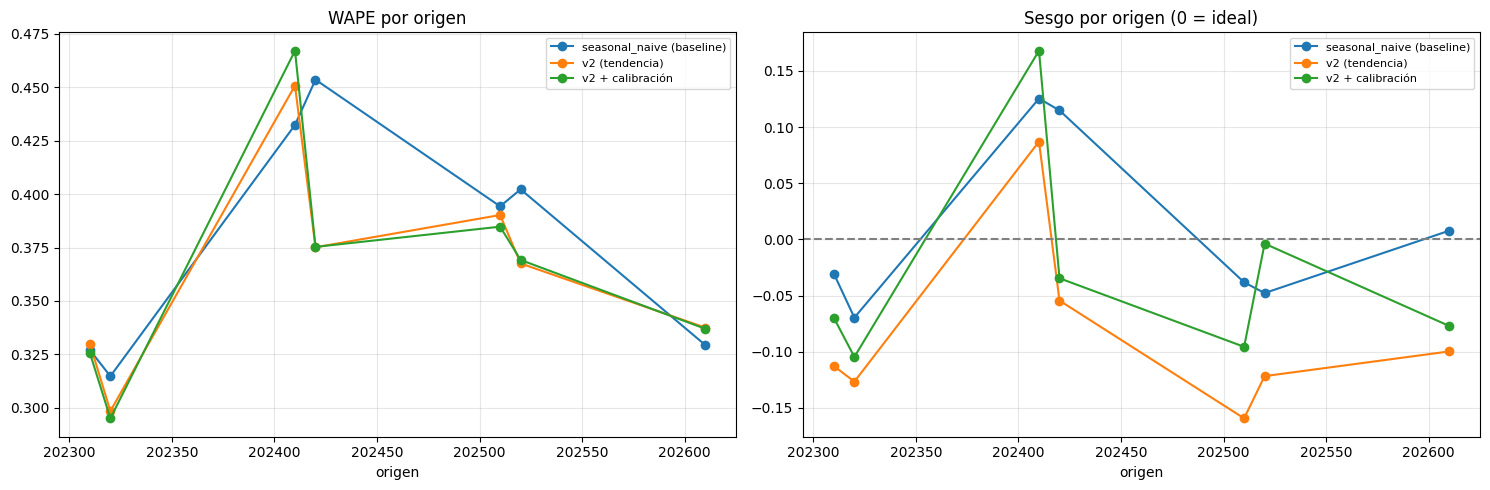

In [37]:
# ══════════════════════════════════════════════════════════════════════════════
# FASE 4e · MODELO v2 — híbrido + tendencia + CALIBRACIÓN DE SESGO + cold start
# ══════════════════════════════════════════════════════════════════════════════
# Tres correcciones sobre el v1, cada una atacando un problema medido:
#
#   (1) FEATURES DE TENDENCIA   -> el sesgo -0.134 venía de no ver la ola de
#       crecimiento. Ahora el modelo recibe crec_inst / crec_sede / crec_mat.
#
#   (2) CALIBRACIÓN DE SESGO    -> aunque el modelo vea la tendencia, tiende a
#       quedarse corto. Se estima un factor de nivel en un FOLD DE CALIBRACIÓN
#       (el último periodo del train, nunca el de test) y se aplica a la predicción.
#       Es un ajuste honesto: se calibra con datos que el modelo ya podía ver.
#
#   (3) COLD START REFORZADO    -> era el eslabón débil (WAPE 0.648, sesgo -0.483).
#       Ahora usa las features de series HERMANAS: la serie no tiene pasado propio,
#       pero sus parientes sí (T17 §8).

FEATURES_V2 = FEATURES + [c for c in FEAT_NUEVAS if c in demanda.columns]
print(f"Features v1: {len(FEATURES)}  ->  v2: {len(FEATURES_V2)}  (+{len(FEATURES_V2)-len(FEATURES)})")

_fuga = [c for c in FEATURES_V2 if c in _PROHIBIDAS]
if _fuga:
    raise ValueError(f"LEAKAGE: {_fuga}")
print("Chequeo anti-leakage OK.\n")

# Recalcular la matriz con las features nuevas
_d2 = demanda.copy()
for _c in FEAT_CAT:
    _d2[_c] = _d2[_c].astype('category')
for _c in FEAT_BOOL:
    _d2[_c] = _d2[_c].astype(int)
if 'cluster' in _d2.columns:
    _d2['cluster'] = _d2['cluster'].fillna(-99).astype(int)

CLIP_CORR = 2.0
CALIBRAR  = True

def _fit_correccion(tr, feats):
    """Modelo de corrección log-ratio sobre el seasonal naive."""
    y = (np.log1p(tr['INSCRITOS']) - np.log1p(tr['ins_lag_1y'])).clip(-CLIP_CORR, CLIP_CORR)
    m = lgb.LGBMRegressor(n_estimators=600, learning_rate=0.05, num_leaves=63,
                          min_child_samples=20, subsample=0.8, colsample_bytree=0.8,
                          random_state=42, verbose=-1)
    m.fit(tr[feats], y, categorical_feature=FEAT_CAT)
    return m

def _predice(m, te, feats):
    return np.clip(np.expm1(np.log1p(te['ins_lag_1y'].values) + m.predict(te[feats])), 0, None)

_res2 = []
for _o in ORIGENES_WF:
    tr_all = _d2[_d2['PERIODO'] <  _o]
    te_all = _d2[_d2['PERIODO'] == _o]
    if len(tr_all) < 1000 or len(te_all) == 0:
        continue
    escala = (tr_all['INSCRITOS'] - tr_all['ins_lag_1y']).abs().mean()

    _con = lambda d: d[d['ins_lag_1y'].notna() & (d['ins_lag_1y'] > 0)]
    tr, te = _con(tr_all), _con(te_all)

    # ---------- (2) FOLD DE CALIBRACIÓN: último periodo del train ----------
    factor = 1.0
    if CALIBRAR:
        _p_cal = sorted(tr['PERIODO'].unique())[-1]
        _tr_cal, _te_cal = _con(tr_all[tr_all['PERIODO'] < _p_cal]), _con(tr_all[tr_all['PERIODO'] == _p_cal])
        if len(_tr_cal) > 500 and len(_te_cal) > 50:
            _pc = _predice(_fit_correccion(_tr_cal, FEATURES_V2), _te_cal, FEATURES_V2)
            if _pc.sum() > 0:
                factor = float(_te_cal['INSCRITOS'].sum() / _pc.sum())
                factor = float(np.clip(factor, 0.7, 1.6))     # cota de seguridad

    # ---------- (1) MODELO v2 sobre todo el train ----------
    m = _fit_correccion(tr, FEATURES_V2)
    p_v2  = _predice(m, te, FEATURES_V2)
    p_cal = np.clip(p_v2 * factor, 0, None)

    y = te['INSCRITOS'].values
    def _met(nombre, p, n=None):
        e = np.abs(y - p) if n is None else None
        return dict(origen=_o, modelo=nombre, n=len(te), factor=factor,
                    MAE=e.mean(), RMSE=float(np.sqrt(((y-p)**2).mean())),
                    WAPE=e.sum()/y.sum(), MASE=e.mean()/escala, sesgo=(p-y).sum()/y.sum())
    _res2 += [_met('v2 (tendencia)', p_v2),
              _met('v2 + calibración', p_cal),
              _met('seasonal_naive (baseline)', te['ins_lag_1y'].values)]

    # ---------- (3) COLD START REFORZADO ----------
    tr_cs, te_cs = tr_all[tr_all['ins_lag_1y'].isna()], te_all[te_all['ins_lag_1y'].isna()]
    if len(tr_cs) > 500 and len(te_cs) > 0:
        mcs = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.05, num_leaves=31,
                                random_state=42, verbose=-1)
        mcs.fit(tr_cs[FEATURES_V2], np.log1p(tr_cs['INSCRITOS']), categorical_feature=FEAT_CAT)
        p_cs = np.clip(np.expm1(mcs.predict(te_cs[FEATURES_V2])), 0, None)
        y_cs = te_cs['INSCRITOS'].values
        e_cs = np.abs(y_cs - p_cs)
        _res2.append(dict(origen=_o, modelo='cold start v2', n=len(te_cs), factor=np.nan,
                          MAE=e_cs.mean(), RMSE=float(np.sqrt(((y_cs-p_cs)**2).mean())),
                          WAPE=e_cs.sum()/y_cs.sum(), MASE=e_cs.mean()/escala,
                          sesgo=(p_cs-y_cs).sum()/y_cs.sum()))
    print(f"   ✓ origen {_o}   (factor de calibración: {factor:.3f})")

resultados_v2 = pd.DataFrame(_res2)

print("\n" + "═" * 78); print("RESULTADOS POR ORIGEN"); print("═" * 78)
print(resultados_v2.round(3).to_string(index=False))

print("\n" + "═" * 78); print("RANKING FINAL"); print("═" * 78)
_rk3 = (resultados_v2.groupby('modelo')[['MAE','RMSE','WAPE','MASE','sesgo']]
                     .mean().sort_values('WAPE'))
print(_rk3.round(3).to_string())

_wb = _rk3.loc['seasonal_naive (baseline)', 'WAPE']
print("\n" + "═" * 78); print("EVOLUCIÓN DEL MODELO (WAPE, menor = mejor)"); print("═" * 78)
print(f"  v0  modelo de NIVEL          : 0.466   ❌ {(_wb-0.466)/_wb*100:+.1f}% vs baseline")
print(f"  v1  híbrido (corrección)     : 0.373   ✅ {(_wb-0.373)/_wb*100:+.1f}%")
for _m in ['v2 (tendencia)', 'v2 + calibración']:
    if _m in _rk3.index:
        _w = _rk3.loc[_m, 'WAPE']
        print(f"  {_m:28s}: {_w:.3f}   {'✅' if _w < _wb else '❌'} {(_wb-_w)/_wb*100:+.1f}%  "
              f"(sesgo {_rk3.loc[_m,'sesgo']:+.3f})")
print(f"  baseline seasonal_naive      : {_wb:.3f}   (sesgo {_rk3.loc['seasonal_naive (baseline)','sesgo']:+.3f})")

print("\n" + "═" * 78); print("COLD START — antes vs ahora"); print("═" * 78)
if 'cold start v2' in _rk3.index:
    print(f"  v1: WAPE 0.648 | MASE 3.322 | sesgo -0.483")
    print(f"  v2: WAPE {_rk3.loc['cold start v2','WAPE']:.3f} | MASE {_rk3.loc['cold start v2','MASE']:.3f} | "
          f"sesgo {_rk3.loc['cold start v2','sesgo']:+.3f}")

# Gráficos de seguimiento
_sinCS = resultados_v2[resultados_v2['modelo'] != 'cold start v2']
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
_sinCS.pivot(index='origen', columns='modelo', values='WAPE').plot(marker='o', ax=ax[0])
ax[0].set_title('WAPE por origen'); ax[0].grid(alpha=.3); ax[0].legend(fontsize=8)
_sinCS.pivot(index='origen', columns='modelo', values='sesgo').plot(marker='o', ax=ax[1])
ax[1].axhline(0, ls='--', c='gray'); ax[1].set_title('Sesgo por origen (0 = ideal)')
ax[1].grid(alpha=.3); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

   ✓ origen 202310   (w=0.9, factor global=1.033, segmentos=5)
   ✓ origen 202320   (w=1.0, factor global=1.025, segmentos=5)
   ✓ origen 202410   (w=1.0, factor global=1.074, segmentos=5)
   ✓ origen 202420   (w=1.0, factor global=1.021, segmentos=5)
   ✓ origen 202510   (w=1.0, factor global=1.076, segmentos=5)
   ✓ origen 202520   (w=1.0, factor global=1.134, segmentos=5)
   ✓ origen 202610   (w=1.0, factor global=1.025, segmentos=3)

══════════════════════════════════════════════════════════════════════════════
RESULTADOS POR ORIGEN
══════════════════════════════════════════════════════════════════════════════
 origen                         modelo    n   w   fac    MAE    RMSE  WAPE  MASE  sesgo
 202310               v2 (solo modelo) 3500 0.9 1.033 22.582  46.006 0.330 1.526 -0.113
 202310                       v3 blend 3500 0.9 1.033 22.313  45.139 0.326 1.508 -0.104
 202310      v3 blend + calib segmento 3500 0.9 1.033 23.153  48.007 0.338 1.565 -0.155
 202310      seasonal_naiv

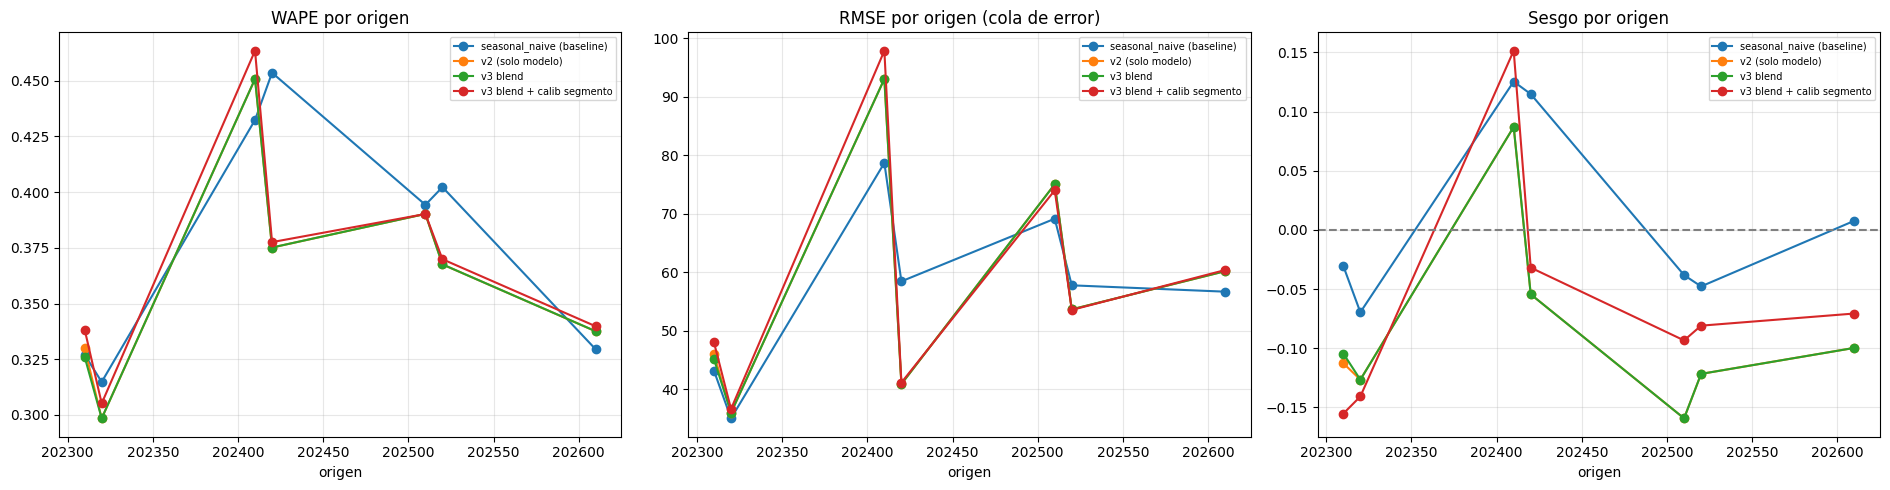

In [38]:
# ══════════════════════════════════════════════════════════════════════════════
# FASE 4f · MODELO v3 — blend + calibración por segmento + cold start replanteado
# ══════════════════════════════════════════════════════════════════════════════
# Tres correcciones sobre v2, cada una atacando un problema medido:
#
#  (1) BLEND baseline+modelo. El v2 pierde en 202610 (0.333 vs 0.295) y tiene peor
#      RMSE (80.3 vs 57.7): acierta más "en promedio" pero se equivoca más feo en
#      las colas. Combinar dos predictores poco correlacionados reduce varianza —
#      es la técnica más establecida del forecasting para eso. El peso w NO se
#      elige mirando el test: se aprende en el fold de calibración.
#
#  (2) CALIBRACIÓN POR SEGMENTO y acotada. El factor global 1.368 de 202610
#      sobre-corrigió (sesgo -0.147 -> +0.167). Se calcula un factor por SEDE con
#      cota estrecha [0.85, 1.25] y fallback al global si el segmento es chico.
#
#  (3) COLD START replanteado. Las features de hermanas solo llegan al 25.8% de
#      esas filas, por eso apenas mejoró (0.648 -> 0.624). Se contrasta el modelo
#      contra HEURÍSTICOS simples anclados en variables de alta cobertura. Si un
#      heurístico gana, se usa el heurístico: no hay premio por complejidad.

GRID_W    = np.arange(0, 1.01, 0.1)      # peso del modelo en el blend
CLIP_SEG  = (0.85, 1.25)                 # cota estrecha para la calibración
MIN_SEG   = 200                          # filas mínimas para calibrar un segmento

def _wape_np(y, p): return np.abs(y - p).sum() / y.sum()

_res3 = []
for _o in ORIGENES_WF:
    tr_all = _d2[_d2['PERIODO'] <  _o]
    te_all = _d2[_d2['PERIODO'] == _o]
    if len(tr_all) < 1000 or len(te_all) == 0:
        continue
    escala = (tr_all['INSCRITOS'] - tr_all['ins_lag_1y']).abs().mean()
    _con = lambda d: d[d['ins_lag_1y'].notna() & (d['ins_lag_1y'] > 0)]
    tr, te = _con(tr_all), _con(te_all)

    # ── FOLD DE CALIBRACIÓN: se aprenden w y los factores SIN tocar el test ──
    w_opt, fac_glob, fac_seg = 0.5, 1.0, {}
    _p_cal = sorted(tr['PERIODO'].unique())[-1]
    _trc, _tec = _con(tr_all[tr_all['PERIODO'] < _p_cal]), _con(tr_all[tr_all['PERIODO'] == _p_cal])
    if len(_trc) > 500 and len(_tec) > 50:
        _pc = _predice(_fit_correccion(_trc, FEATURES_V2), _tec, FEATURES_V2)
        _bc = _tec['ins_lag_1y'].values
        _yc = _tec['INSCRITOS'].values
        # (1) peso óptimo del blend
        w_opt = float(GRID_W[np.argmin([_wape_np(_yc, w*_pc + (1-w)*_bc) for w in GRID_W])])
        # (2) factores de calibración sobre el blend ya formado
        _mix = w_opt*_pc + (1-w_opt)*_bc
        if _mix.sum() > 0:
            fac_glob = float(np.clip(_yc.sum()/_mix.sum(), *CLIP_SEG))
        _tmp = pd.DataFrame({'seg': _tec['CAMPUS'].values, 'y': _yc, 'p': _mix})
        for _s, _g in _tmp.groupby('seg', observed=True):
            if len(_g) >= MIN_SEG and _g['p'].sum() > 0:
                fac_seg[_s] = float(np.clip(_g['y'].sum()/_g['p'].sum(), *CLIP_SEG))

    # ── MODELO SOBRE TODO EL TRAIN ──
    m = _fit_correccion(tr, FEATURES_V2)
    p_mod = _predice(m, te, FEATURES_V2)
    p_bas = te['ins_lag_1y'].values
    y     = te['INSCRITOS'].values

    p_blend = w_opt*p_mod + (1-w_opt)*p_bas
    _f = te['CAMPUS'].map(fac_seg).fillna(fac_glob).astype(float).values
    p_v3 = np.clip(p_blend * _f, 0, None)

    def _met(nombre, p, extra=None):
        e = np.abs(y - p)
        d = dict(origen=_o, modelo=nombre, n=len(te), w=w_opt, fac=fac_glob,
                 MAE=e.mean(), RMSE=float(np.sqrt(((y-p)**2).mean())),
                 WAPE=e.sum()/y.sum(), MASE=e.mean()/escala, sesgo=(p-y).sum()/y.sum())
        return d
    _res3 += [_met('v2 (solo modelo)', p_mod),
              _met('v3 blend', p_blend),
              _met('v3 blend + calib segmento', p_v3),
              _met('seasonal_naive (baseline)', p_bas)]

    # ── (3) COLD START: modelo vs heurísticos ──
    tr_cs, te_cs = tr_all[tr_all['ins_lag_1y'].isna()], te_all[te_all['ins_lag_1y'].isna()]
    if len(tr_cs) > 500 and len(te_cs) > 0:
        y_cs = te_cs['INSCRITOS'].values
        _cands = {}
        # heurísticos anclados en variables de ALTA cobertura
        _cands['CS heurístico: sede+componente'] = te_cs['sedecomp_l1_mean'].values
        _cands['CS heurístico: materia']          = te_cs['mat_l1_mean'].values
        # modelo
        mcs = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.05, num_leaves=31,
                                random_state=42, verbose=-1)
        mcs.fit(tr_cs[FEATURES_V2], np.log1p(tr_cs['INSCRITOS']), categorical_feature=FEAT_CAT)
        _cands['CS modelo LightGBM'] = np.expm1(mcs.predict(te_cs[FEATURES_V2]))
        _med = tr_cs['INSCRITOS'].median()
        for _nm, _p in _cands.items():
            _p = np.clip(pd.Series(_p).fillna(_med).values, 0, None)   # sin dato -> mediana del train
            _e = np.abs(y_cs - _p)
            _res3.append(dict(origen=_o, modelo=_nm, n=len(te_cs), w=np.nan, fac=np.nan,
                              MAE=_e.mean(), RMSE=float(np.sqrt(((y_cs-_p)**2).mean())),
                              WAPE=_e.sum()/y_cs.sum(), MASE=_e.mean()/escala,
                              sesgo=(_p-y_cs).sum()/y_cs.sum()))
    print(f"   ✓ origen {_o}   (w={w_opt:.1f}, factor global={fac_glob:.3f}, segmentos={len(fac_seg)})")

resultados_v3 = pd.DataFrame(_res3)

print("\n" + "═" * 78); print("RESULTADOS POR ORIGEN"); print("═" * 78)
print(resultados_v3.round(3).to_string(index=False))

_CS = resultados_v3['modelo'].str.startswith('CS ')
print("\n" + "═" * 78); print("RANKING — filas CON baseline"); print("═" * 78)
_rk4 = (resultados_v3[~_CS].groupby('modelo')[['MAE','RMSE','WAPE','MASE','sesgo']]
                            .mean().sort_values('WAPE'))
print(_rk4.round(3).to_string())

print("\n" + "═" * 78); print("RANKING — COLD START (filas sin baseline)"); print("═" * 78)
_rk5 = (resultados_v3[_CS].groupby('modelo')[['MAE','RMSE','WAPE','MASE','sesgo']]
                           .mean().sort_values('WAPE'))
print(_rk5.round(3).to_string())
_gcs = _rk5.index[0]
print(f"\n🏆 Mejor en cold start: {_gcs}")
if 'heurístico' in _gcs:
    print("   ⚠️  Un heurístico simple le gana al modelo -> usar el heurístico.")
    print("       No hay premio por complejidad si no mejora la métrica (T17 §10).")

_wb = _rk4.loc['seasonal_naive (baseline)', 'WAPE']
print("\n" + "═" * 78); print("EVOLUCIÓN COMPLETA (WAPE)"); print("═" * 78)
print(f"  v0  nivel                     : 0.466   ❌ {(_wb-0.466)/_wb*100:+.1f}%")
print(f"  v1  híbrido                   : 0.373   ✅ {(_wb-0.373)/_wb*100:+.1f}%")
print(f"  v2  + tendencia               : 0.361   ✅ {(_wb-0.361)/_wb*100:+.1f}%")
for _m in ['v3 blend', 'v3 blend + calib segmento']:
    if _m in _rk4.index:
        _w = _rk4.loc[_m,'WAPE']; _r = _rk4.loc[_m,'RMSE']; _s = _rk4.loc[_m,'sesgo']
        print(f"  {_m:29s}: {_w:.3f}   {'✅' if _w<_wb else '❌'} {(_wb-_w)/_wb*100:+.1f}%   "
              f"RMSE {_r:.1f}  sesgo {_s:+.3f}")
print(f"  baseline                      : {_wb:.3f}   RMSE {_rk4.loc['seasonal_naive (baseline)','RMSE']:.1f}  "
      f"sesgo {_rk4.loc['seasonal_naive (baseline)','sesgo']:+.3f}")

print("\n" + "═" * 78); print("¿SE ARREGLÓ EL CASO 202610?"); print("═" * 78)
_p10 = resultados_v3[(resultados_v3['origen'] == 202610) & (~_CS)][['modelo','WAPE','RMSE','sesgo']]
print(_p10.round(3).to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(19, 5))
_sc = resultados_v3[~_CS]
_sc.pivot(index='origen', columns='modelo', values='WAPE').plot(marker='o', ax=ax[0])
ax[0].set_title('WAPE por origen'); ax[0].grid(alpha=.3); ax[0].legend(fontsize=7)
_sc.pivot(index='origen', columns='modelo', values='RMSE').plot(marker='o', ax=ax[1])
ax[1].set_title('RMSE por origen (cola de error)'); ax[1].grid(alpha=.3); ax[1].legend(fontsize=7)
_sc.pivot(index='origen', columns='modelo', values='sesgo').plot(marker='o', ax=ax[2])
ax[2].axhline(0, ls='--', c='gray'); ax[2].set_title('Sesgo por origen'); ax[2].grid(alpha=.3); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

══════════════════════════════════════════════════════════════════════════════
FEATURES DE TASA POR NIVEL
══════════════════════════════════════════════════════════════════════════════
  crec_nivel             cobertura  89.2%   spearman vs target -0.127
  crec_nivel_sede        cobertura  87.6%   spearman vs target -0.092
  crec_nivel_mat         cobertura  83.7%   spearman vs target +0.090
  tot_nivel_l1           cobertura  94.6%   spearman vs target +0.329
  tot_nivel_sede_l1      cobertura  94.0%   spearman vs target +0.405
  peso_serie_en_nivel    cobertura  73.1%   spearman vs target +0.653

══════════════════════════════════════════════════════════════════════════════
CRECIMIENTO ANUAL POR NIVEL (lo que ve el modelo)
══════════════════════════════════════════════════════════════════════════════
ANIO                  2020   2021   2022   2023   2024   2025   2026
desc_nivel_asig                                                     
DOCTORADO            1.018  1.901  1.763  0.965 

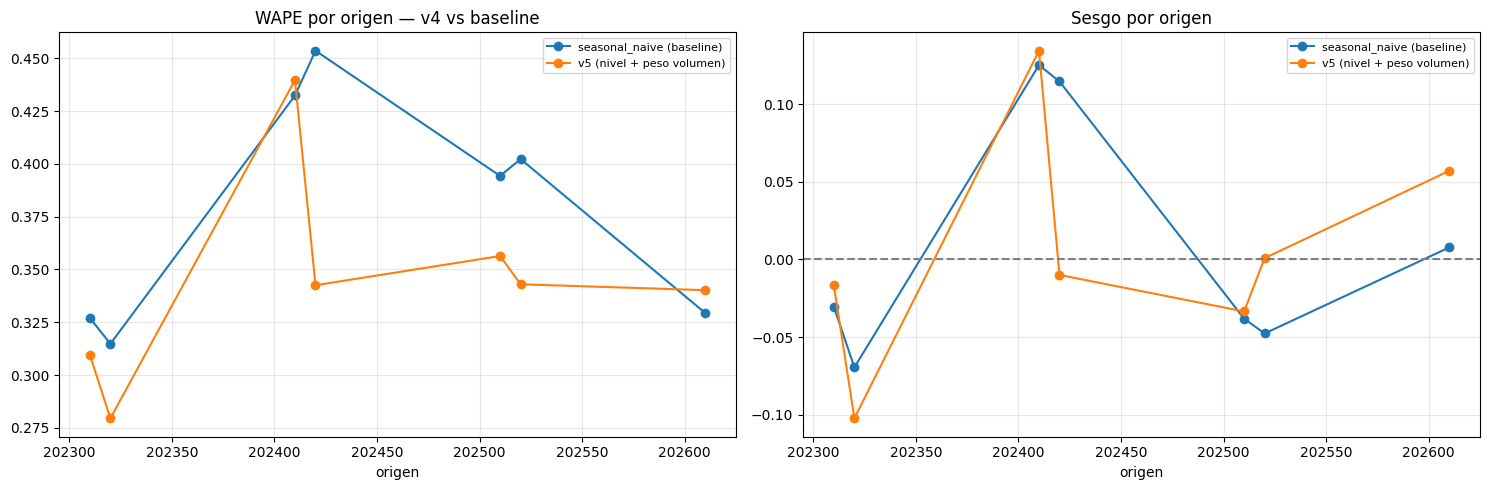


`_d2` reconstruido: 144,662 filas × 99 columnas — incluye las 6 features de nivel


In [39]:
# ══════════════════════════════════════════════════════════════════════════════
# FASE 4g · TASA DE CRECIMIENTO POR NIVEL   (regla de negocio)
# ══════════════════════════════════════════════════════════════════════════════
# Corrección sobre las features de tendencia de la Fase 4d.
#
# PROBLEMA: `crec_inst` / `crec_sede` / `crec_mat` comparan MISMO TT contra MISMO
# TT (202510 vs 202410). Para una asignatura de PREGRADO eso ignora la mitad de la
# información —el 2º semestre también informa el nivel de demanda— y para una de
# ADVANCE compara contra un trimestre en vez de contra el año completo.
#
# REGLA CORRECTA: la tasa se calcula sobre TODOS los períodos que tributan al
# nivel de la asignatura. Confirmado empíricamente en el pipeline:
#
#     PREGRADO             -> TT 10, 20, 30   (97,7% del nivel)
#     TRIMESTRAL PREGRADO  -> TT 05, 15, 25   (99,7%)
#     MAGISTER / DP / PE   -> TT 00 (anual)
#     DOCTORADO            -> TT 10, 20, 12, 22
#
# La GRILLA de proyección NO cambia: sigue siendo el período homólogo
# (202510 -> 202610). Lo que cambia es de dónde sale la TASA.

# Parámetros heredados de la celda v3; se definen aquí también por si esta celda
# se ejecuta de forma aislada.
GRID_W   = globals().get('GRID_W', np.arange(0, 1.01, 0.1))
CLIP_SEG = globals().get('CLIP_SEG', (0.85, 1.25))
CLIP_CORR = globals().get('CLIP_CORR', 2.0)

if 'cod_nivel_asig' not in demanda.columns:
    raise ValueError("Falta `cod_nivel_asig`: re-ejecutar el PIPELINE (celda de nivel) "
                     "y regenerar DEMANDA_PROCESADA.parquet")

# ── Volumen anual por nivel: suma de TODOS sus períodos en el año ─────────────
_niv_anio = (demanda.groupby(['cod_nivel_asig', 'ANIO'])['INSCRITOS'].sum()
                    .rename('tot_nivel').reset_index())

# ── Volumen anual por nivel × sede y por nivel × materia ─────────────────────
_niv_sede = (demanda.groupby(['cod_nivel_asig', 'CAMPUS', 'ANIO'])['INSCRITOS'].sum()
                    .rename('tot_nivel_sede').reset_index())
_niv_mat  = (demanda.groupby(['cod_nivel_asig', 'MATERIA', 'ANIO'])['INSCRITOS'].sum()
                    .rename('tot_nivel_mat').reset_index())

def _lag_anual(dem, agg, keys, col, k, nombre):
    """Trae `col` de k años atrás (anti-leakage: solo mira años cerrados previos)."""
    a = agg.copy(); a['ANIO'] = a['ANIO'] + k
    return dem.merge(a.rename(columns={col: nombre}), on=keys + ['ANIO'], how='left')

_nuevas_niv = ['tot_nivel_l1','tot_nivel_l2','tot_nivel_sede_l1','tot_nivel_sede_l2',
               'tot_nivel_mat_l1','tot_nivel_mat_l2',
               'crec_nivel','crec_nivel_sede','crec_nivel_mat','peso_serie_en_nivel']
demanda = demanda.drop(columns=_nuevas_niv, errors='ignore')     # idempotente

for _k, _suf in [(1, 'l1'), (2, 'l2')]:
    demanda = _lag_anual(demanda, _niv_anio, ['cod_nivel_asig'], 'tot_nivel', _k, f'tot_nivel_{_suf}')
    demanda = _lag_anual(demanda, _niv_sede, ['cod_nivel_asig','CAMPUS'], 'tot_nivel_sede', _k, f'tot_nivel_sede_{_suf}')
    demanda = _lag_anual(demanda, _niv_mat,  ['cod_nivel_asig','MATERIA'], 'tot_nivel_mat', _k, f'tot_nivel_mat_{_suf}')

demanda['crec_nivel']      = demanda['tot_nivel_l1']      / demanda['tot_nivel_l2']
demanda['crec_nivel_sede'] = demanda['tot_nivel_sede_l1'] / demanda['tot_nivel_sede_l2']
demanda['crec_nivel_mat']  = demanda['tot_nivel_mat_l1']  / demanda['tot_nivel_mat_l2']
# Peso de la serie dentro de su nivel el año pasado (señal de importancia relativa)
demanda['peso_serie_en_nivel'] = demanda['ins_lag_1y'] / demanda['tot_nivel_l1']

FEAT_NIVEL = ['crec_nivel', 'crec_nivel_sede', 'crec_nivel_mat',
              'tot_nivel_l1', 'tot_nivel_sede_l1', 'peso_serie_en_nivel']

print("═" * 78); print("FEATURES DE TASA POR NIVEL"); print("═" * 78)
for _c in FEAT_NIVEL:
    _cov = demanda[_c].notna().mean()
    _ok = demanda[_c].notna() & demanda['INSCRITOS'].notna()
    _r = demanda.loc[_ok, 'INSCRITOS'].corr(demanda.loc[_ok, _c], method='spearman')
    print(f"  {_c:22s} cobertura {_cov:6.1%}   spearman vs target {_r:+.3f}")

print("\n" + "═" * 78); print("CRECIMIENTO ANUAL POR NIVEL (lo que ve el modelo)"); print("═" * 78)
_piv = (demanda[demanda['crec_nivel'].notna()]
        .groupby(['desc_nivel_asig', 'ANIO'])['crec_nivel'].first().unstack().round(3))
print(_piv.loc[:, _piv.columns >= 2020].to_string())

print("\n" + "═" * 78); print("COMPARACIÓN: tasa por TT (v2) vs tasa por NIVEL (v4)"); print("═" * 78)
_cmp = (demanda[demanda['TT'].isin([10, 20])]
        .groupby('ANIO')[['crec_inst', 'crec_nivel']].mean().round(3))
print(_cmp.loc[_cmp.index >= 2022].to_string())
print("\n-> `crec_inst` mira solo el mismo TT; `crec_nivel` suma todos los períodos")
print("   del nivel, así que es una medida más estable y completa del ritmo real.")

# ── Re-evaluar el modelo con las nuevas features ─────────────────────────────
FEATURES_V4 = FEATURES_V2 + [c for c in FEAT_NIVEL if c in demanda.columns]
if 'cod_nivel_asig' in demanda.columns and 'cod_nivel_asig' not in FEAT_CAT:
    FEAT_CAT_V4 = FEAT_CAT + ['cod_nivel_asig']
    FEATURES_V4 = FEATURES_V4 + ['cod_nivel_asig']
else:
    FEAT_CAT_V4 = FEAT_CAT
# ── Features que habilitó la homologación (2026-08-26) ──────────────────────
# N_CODIGOS_ORIGEN : cuántos códigos históricos se fundieron en esta serie. Una
#                    serie armada con 13 códigos de 6 materias es estructuralmente
#                    distinta de una de código único, y el modelo no tenía cómo
#                    distinguirlas.
# REGLA            : el slot curricular al que pertenece. Agrupa asignaturas
#                    vecinas que MATERIA/CURSO no relaciona.
#                    ⚠️ alta cardinalidad (~4.100 niveles) y 2,1% de nulos: si el
#                    WAPE empeora al agregarla, sacarla es lo primero que probar.
# ⛔ REGLA SE DESCARTÓ (2026-08-26, FASE 4g-ter). Medído sobre 7 orígenes:
#      LightGBM CON REGLA  WAPE 0,3707  ventaja sobre el naive +2,21%
#      LightGBM SIN REGLA  WAPE 0,3565  ventaja                +5,97%
#    Sacarla mejora 3,85% y casi triplica la ventaja. Era la variable más
#    importante del modelo (17,19%) y a la vez lo estaba degradando: con 3.516
#    niveles sobre ~100.000 filas hay ~29 filas por categoría, así que el árbol
#    la usaba para MEMORIZAR, no para generalizar. Importancia alta ≠ aporte.
#    CatBoost también mejora al quitarla (0,3461 -> 0,3450).
_FEAT_HOM_NUM = [c for c in ['N_CODIGOS_ORIGEN'] if c in demanda.columns]
_FEAT_HOM_CAT = []      # REGLA fuera: sobreajusta
if _FEAT_HOM_NUM or _FEAT_HOM_CAT:
    FEATURES_V4 = FEATURES_V4 + _FEAT_HOM_NUM + _FEAT_HOM_CAT
    FEAT_CAT_V4 = FEAT_CAT_V4 + _FEAT_HOM_CAT
    print(f"  + features de homologación: {_FEAT_HOM_NUM + _FEAT_HOM_CAT}")
else:
    print("  ⚠️ la sábana no trae N_CODIGOS_ORIGEN/REGLA: correr el PIPELINE actualizado")

print(f"\nFeatures v2: {len(FEATURES_V2)}  ->  v4: {len(FEATURES_V4)}")

_d4 = demanda.copy()
for _c in FEAT_CAT_V4:
    _d4[_c] = _d4[_c].astype('category')
for _c in FEAT_BOOL:
    _d4[_c] = _d4[_c].astype(int)
if 'cluster' in _d4.columns:
    _d4['cluster'] = _d4['cluster'].fillna(-99).astype(int)

# ⭐ v5 · PONDERACIÓN POR VOLUMEN (promovido el 2026-07-29, ver FASE 4i)
# El target es un log-ratio: sin peso, un error del 20% en una serie de 2.000 aporta
# a la pérdida lo mismo que en una de 10, aunque en inscritos sean 400 alumnos contra
# 2. `sample_weight = ins_lag_1y` alinea el entrenamiento con el error absoluto.
# Medido: error absoluto −2,58% global y −3,84% en el tramo >200, donde la mejora
# sobre el naive pasó de +1,2% a +5,0%. El sesgo se mantiene bajo (+1,9%).
# `ins_lag_1y` es información del año anterior: no introduce leakage.
PESO_VOLUMEN = True

# ⭐ ALGORITMO: CatBoost (2026-08-26, FASE 4g-ter). Medido sobre 7 orígenes con
# las mismas features y el mismo target de corrección:
#      LightGBM  WAPE 0,3565   ventaja sobre el naive +5,97%   160 s
#      CatBoost  WAPE 0,3450   ventaja                +8,99%   673 s
# Gana 3,2% y cuesta ~4x. La comparación anterior ("empatan a 17x el tiempo")
# se había hecho sobre el v0 de NIVEL, que era otro problema.
# ⚠️ Su sesgo es más negativo (−0,096 vs −0,059): sub-proyecta más, y eso
# interactúa con la reconciliación de nivel. Vigilar el sesgo agregado.
USAR_CATBOOST = True
try:
    from catboost import CatBoostRegressor
except ImportError:
    USAR_CATBOOST = False
    print("⚠️ CatBoost no instalado: se usa LightGBM (WAPE esperado ~0,357 en vez de ~0,345)")


def _cat_str(X, cols):
    """Prepara las categóricas para CatBoost.

    ⚠️ CatBoost exige str y NO acepta NaN en cat_features: falla con
    "cat_features must be integer or string". Un `.astype(str)` sobre una columna
    'category' con nulos NO siempre los materializa, así que hay que pasar por
    'object' y rellenar explícitamente. El NaN se vuelve una categoría propia,
    que es lo correcto: aquí "sin dato" es información, no ausencia de ella
    (una serie sin `departamento` es distinta de una con departamento X)."""
    X = X.copy()
    for _c in cols:
        if _c in X.columns:
            X[_c] = X[_c].astype('object').fillna('__NA__').astype(str)
    # ⚠️ CatBoost trata como categórica CUALQUIER columna con dtype 'category',
    # esté o no en `cat_features`, y exige que no tenga NaN. Si el pipeline dejó
    # alguna fuera de FEAT_CAT_V4, el fit falla con un mensaje que solo da el
    # ÍNDICE de la columna, no su nombre. Se materializan también y se avisa cuáles.
    _huerf = [c for c in X.columns if isinstance(X[c].dtype, pd.CategoricalDtype)]
    for _c in _huerf:
        X[_c] = X[_c].astype('object').fillna('__NA__').astype(str)
    if _huerf and not globals().get('_AVISO_HUERF'):
        print(f"     · categóricas fuera de la lista, convertidas igual: {_huerf}")
        globals()['_AVISO_HUERF'] = True
    # verificación final: si algo sigue con NaN, decir QUÉ columna
    _sucias = [c for c in cols if c in X.columns and X[c].isna().any()]
    if _sucias:
        raise ValueError(f"_cat_str dejó NaN en {_sucias}: CatBoost va a fallar.")
    return X


class _CatWrap:
    """Envuelve un CatBoost para que se comporte como un LGBMRegressor.

    ⚠️ POR QUÉ EXISTE: el notebook llama `.predict(X)` en muchos sitios pasando
    el DataFrame tal cual, con categóricas de pandas y NaN — que es lo que
    LightGBM acepta. CatBoost NO: exige str sin NaN también al predecir, y falla
    con un mensaje que solo da el ÍNDICE de la columna. Envolverlo aquí evita
    tener que recordar `_cat_str` en cada una de esas llamadas (fue exactamente
    lo que se olvidó y provocó cuatro corridas perdidas)."""

    def __init__(self, m, cats):
        self._m, self._cats = m, list(cats)
        self.feature_importances_ = m.feature_importances_

    def predict(self, X, *a, **k):
        return self._m.predict(_cat_str(X, self._cats), *a, **k)

    def __getattr__(self, n):        # cualquier otro atributo va al modelo real
        return getattr(self._m, n)


def _fit_corr_v4(tr):
    y = (np.log1p(tr['INSCRITOS']) - np.log1p(tr['ins_lag_1y'])).clip(-CLIP_CORR, CLIP_CORR)
    _sw = tr['ins_lag_1y'].values if PESO_VOLUMEN else None
    if USAR_CATBOOST:
        _X = _cat_str(tr[FEATURES_V4], FEAT_CAT_V4)
        m = CatBoostRegressor(iterations=600, learning_rate=0.05, depth=8,
                              random_seed=42, verbose=0)
        m.fit(_X, y, cat_features=list(FEAT_CAT_V4), sample_weight=_sw)
        return _CatWrap(m, FEAT_CAT_V4)
    m = lgb.LGBMRegressor(n_estimators=600, learning_rate=0.05, num_leaves=63,
                          min_child_samples=20, subsample=0.8, colsample_bytree=0.8,
                          random_state=42, verbose=-1)
    m.fit(tr[FEATURES_V4], y, sample_weight=_sw, categorical_feature=FEAT_CAT_V4)
    return m

_res4 = []
for _o in ORIGENES_WF:
    tr_all = _d4[_d4['PERIODO'] <  _o]
    te_all = _d4[_d4['PERIODO'] == _o]
    if len(tr_all) < 1000 or len(te_all) == 0:
        continue
    escala = (tr_all['INSCRITOS'] - tr_all['ins_lag_1y']).abs().mean()
    _con = lambda d: d[d['ins_lag_1y'].notna() & (d['ins_lag_1y'] > 0)]
    tr, te = _con(tr_all), _con(te_all)
    y = te['INSCRITOS'].values

    # fold de calibración -> peso del blend y factor de nivel
    w_opt, fac = 0.5, 1.0
    _pc_per = sorted(tr['PERIODO'].unique())[-1]
    _trc, _tec = _con(tr_all[tr_all['PERIODO'] < _pc_per]), _con(tr_all[tr_all['PERIODO'] == _pc_per])
    if len(_trc) > 500 and len(_tec) > 50:
        _p = np.clip(np.expm1(np.log1p(_tec['ins_lag_1y'].values) +
                              _fit_corr_v4(_trc).predict(_tec[FEATURES_V4])), 0, None)
        _b = _tec['ins_lag_1y'].values; _yc = _tec['INSCRITOS'].values
        w_opt = float(GRID_W[np.argmin([np.abs(_yc - (w*_p + (1-w)*_b)).sum()/_yc.sum() for w in GRID_W])])
        _mix = w_opt*_p + (1-w_opt)*_b
        if _mix.sum() > 0:
            fac = float(np.clip(_yc.sum()/_mix.sum(), *CLIP_SEG))

    p_mod = np.clip(np.expm1(np.log1p(te['ins_lag_1y'].values) +
                             _fit_corr_v4(tr).predict(te[FEATURES_V4])), 0, None)
    p_v4 = np.clip((w_opt*p_mod + (1-w_opt)*te['ins_lag_1y'].values) * fac, 0, None)
    for _n, _p in [('v5 (nivel + peso volumen)', p_v4), ('seasonal_naive (baseline)', te['ins_lag_1y'].values)]:
        e = np.abs(y - _p)
        _res4.append(dict(origen=_o, modelo=_n, w=w_opt, fac=fac, MAE=e.mean(),
                          RMSE=float(np.sqrt(((y-_p)**2).mean())), WAPE=e.sum()/y.sum(),
                          MASE=e.mean()/escala, sesgo=(_p-y).sum()/y.sum()))
    print(f"   ✓ origen {_o}   (w={w_opt:.1f}, factor={fac:.3f})")

resultados_v4 = pd.DataFrame(_res4)
print("\n" + "═" * 78); print("RESULTADOS POR ORIGEN"); print("═" * 78)
print(resultados_v4.round(3).to_string(index=False))

_rk6 = resultados_v4.groupby('modelo')[['MAE','RMSE','WAPE','MASE','sesgo']].mean().sort_values('WAPE')
print("\n" + "═" * 78); print("RANKING"); print("═" * 78)
print(_rk6.round(3).to_string())

_wb = _rk6.loc['seasonal_naive (baseline)', 'WAPE']
print("\n" + "═" * 78); print("EVOLUCIÓN COMPLETA (WAPE)"); print("═" * 78)
# ⚠️ Estos WAPE son CIFRAS HISTÓRICAS de la corrida del 2026-07-30, no de esta:
# las versiones v0-v3 ya no se reentrenan. Sirven para ver la evolución del
# método, pero el único WAPE vivo de este bloque es el del v5. El % contra el
# baseline SÍ se recalcula, así que compara cifras de corridas distintas: leerlo
# solo como orden de magnitud.
_EVOL_HIST = [('v0  nivel', 0.466, -0.267), ('v1  híbrido', 0.373, -0.134),
              ('v2  + tendencia por TT', 0.361, -0.115), ('v3  blend + calib', 0.358, -0.048)]
for _et, _w, _s in _EVOL_HIST:
    print(f"  {_et:26s}: {_w:.3f}   {(_wb-_w)/_wb*100:+5.1f}%   sesgo {_s:+.3f}   (histórico)")
_w3 = _EVOL_HIST[-1][1]        # WAPE del v3 — referencia para el veredicto del v5
_w4 = _rk6.loc['v5 (nivel + peso volumen)', 'WAPE']
print(f"  {'v5  + peso por VOLUMEN':26s}: {_w4:.3f}   {(_wb-_w4)/_wb*100:+5.1f}%   "
      f"sesgo {_rk6.loc['v5 (nivel + peso volumen)','sesgo']:+.3f}   "
      f"{'✅ mejora' if _w4 < _w3 else '⚠️ no mejora sobre v3'}")
print(f"  {'baseline':26s}: {_wb:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
resultados_v4.pivot(index='origen', columns='modelo', values='WAPE').plot(marker='o', ax=ax[0])
ax[0].set_title('WAPE por origen — v4 vs baseline'); ax[0].grid(alpha=.3); ax[0].legend(fontsize=8)
resultados_v4.pivot(index='origen', columns='modelo', values='sesgo').plot(marker='o', ax=ax[1])
ax[1].axhline(0, ls='--', c='gray'); ax[1].set_title('Sesgo por origen'); ax[1].grid(alpha=.3); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()


# ── Reconstrucción de `_d2` con las features del v4 ──────────────────────────
# `_d2` se creó en la FASE 4e, ANTES de que existieran las features de nivel, y
# nunca se refrescó. Las celdas siguientes lo siguen usando como matriz de
# trabajo: sin esto, la FASE 7 falla con KeyError al pedir `crec_nivel` sobre él.
_d2 = demanda.copy()
for _c in FEAT_CAT_V4:
    if _c in _d2.columns:
        _d2[_c] = _d2[_c].astype('category')
for _c in FEAT_BOOL:
    if _c in _d2.columns:
        _d2[_c] = _d2[_c].astype(int)
if 'cluster' in _d2.columns:
    _d2['cluster'] = _d2['cluster'].fillna(-99).astype(int)

_falta_v4 = [c for c in FEATURES_V4 if c not in _d2.columns]
if _falta_v4:
    raise ValueError(f"`_d2` quedó sin features del v4: {_falta_v4}")
print(f"\n`_d2` reconstruido: {_d2.shape[0]:,} filas × {_d2.shape[1]} columnas "
      f"— incluye las {len(FEAT_NIVEL)} features de nivel")


In [40]:
## ══════════════════════════════════════════════════════════════════════════════
## FASE 4g-bis · RANKING DE MODELOS, ENSEMBLE E IMPORTANCIA DEL MODELO VIGENTE
## ══════════════════════════════════════════════════════════════════════════════
## POR QUÉ EXISTE ESTA CELDA:
##   La comparación de algoritmos de la FASE 4 se hizo sobre el modelo v0 —el de
##   NIVEL, que perdió contra el baseline por 17% y quedó descartado—. Desde
##   entonces nadie volvió a comparar algoritmos sobre el target que el modelo
##   realmente usa: la CORRECCIÓN log1p(y) − log1p(naive). La importancia de
##   variables que el notebook reportaba también era la del v0, así que las
##   decisiones de feature engineering se tomaban mirando el modelo equivocado.
##
## QUÉ HACE : (a) compara LightGBM / XGBoost / CatBoost sobre el target de
##                corrección, con walk-forward;
##            (b) prueba un ENSEMBLE de los tres (media y mediana);
##            (c) reporta la importancia del modelo VIGENTE.
## ENTRADA  : _d2, FEATURES_V4, FEAT_CAT_V4, ORIGENES_WF, CLIP_CORR, PESO_VOLUMEN
## SALIDA   : `ranking_modelos`, `importancia_v5`
## CLAVE    : ⛔ El ensemble NO es "un modelo por cluster". Esa vía se probó y
##            perdió (PLAN §13.9: 0,479 vs 0,469 del global, con sesgo IDÉNTICO
##            → la causa era la extrapolación, no la heterogeneidad), y el
##            clustering nunca tuvo estructura real. El ensemble usa TODOS los
##            datos y solo promedia predicciones: no fragmenta el entrenamiento
##            ni sacrifica el cross-learning entre series hermanas.
## ──────────────────────────────────────────────────────────────────────────────
import time

_ALGOS = {}
_ALGOS['LightGBM'] = lambda: lgb.LGBMRegressor(
    n_estimators=600, learning_rate=0.05, num_leaves=63, min_child_samples=20,
    subsample=0.8, colsample_bytree=0.8, random_state=42, verbose=-1)
try:
    import xgboost as xgb
    _ALGOS['XGBoost'] = lambda: xgb.XGBRegressor(
        n_estimators=600, learning_rate=0.05, max_depth=8, subsample=0.8,
        colsample_bytree=0.8, random_state=42, tree_method='hist',
        enable_categorical=True, verbosity=0)
except ImportError:
    print("· XGBoost no instalado, se omite")
try:
    from catboost import CatBoostRegressor
    _ALGOS['CatBoost'] = lambda: CatBoostRegressor(
        iterations=600, learning_rate=0.05, depth=8, random_seed=42, verbose=0)
except ImportError:
    print("· CatBoost no instalado, se omite")

print("═" * 78)
print(f"RANKING DE MODELOS + ENSEMBLE — target CORRECCIÓN, {len(_ALGOS)} algoritmos")
print("═" * 78)
print(f"  features: {len(FEATURES_V4)}  |  categóricas: {len(FEAT_CAT_V4)}")
print(f"  orígenes walk-forward: {ORIGENES_WF}")

_con = lambda d: d[d['ins_lag_1y'].notna() & (d['ins_lag_1y'] > 0)]
_seg = {n: 0.0 for n in _ALGOS}
_acum = {n: [] for n in _ALGOS}          # WAPE por origen, por algoritmo
_acum['ENSEMBLE (media)'] = []
_acum['ENSEMBLE (mediana)'] = []
_sesg = {k: [] for k in _acum}

for _o in ORIGENES_WF:
    _tr, _te = _con(_d2[_d2['PERIODO'] < _o]), _con(_d2[_d2['PERIODO'] == _o])
    if len(_tr) < 1000 or len(_te) == 0:
        continue
    _y = (np.log1p(_tr['INSCRITOS']) - np.log1p(_tr['ins_lag_1y'])).clip(-CLIP_CORR, CLIP_CORR)
    _w = _tr['ins_lag_1y'].values if PESO_VOLUMEN else None
    _real = _te['INSCRITOS'].values
    _base = np.log1p(_te['ins_lag_1y'].values)
    _pred_origen = {}                    # predicciones en INSCRITOS, alineadas

    for _nom, _mk in _ALGOS.items():
        _t0 = time.time()
        try:
            _m = _mk()
            if _nom == 'CatBoost':       # CatBoost pide las categóricas como str
                _Xtr, _Xte = _tr[FEATURES_V4].copy(), _te[FEATURES_V4].copy()
                _Xtr = _cat_str(_Xtr, FEAT_CAT_V4)
                _Xte = _cat_str(_Xte, FEAT_CAT_V4)
                _m.fit(_Xtr, _y, cat_features=list(FEAT_CAT_V4), sample_weight=_w)
                _corr = _m.predict(_Xte)
            elif _nom == 'XGBoost':
                _m.fit(_tr[FEATURES_V4], _y, sample_weight=_w)
                _corr = _m.predict(_te[FEATURES_V4])
            else:
                _m.fit(_tr[FEATURES_V4], _y, sample_weight=_w,
                       categorical_feature=FEAT_CAT_V4)
                _corr = _m.predict(_te[FEATURES_V4])
        except Exception as _e:
            print(f"  ⚠️ {_nom} falló en {_o}: {str(_e)[:70]}")
            continue
        _seg[_nom] += time.time() - _t0
        _p = np.clip(np.expm1(_base + _corr), 0, None)
        _pred_origen[_nom] = _p
        _acum[_nom].append(np.abs(_p - _real).sum() / _real.sum())
        _sesg[_nom].append((_p.sum() - _real.sum()) / _real.sum())

    # ── ENSEMBLE: combina las predicciones de este mismo origen ─────────────
    if len(_pred_origen) >= 2:
        _M = np.vstack(list(_pred_origen.values()))
        for _et, _agg in [('ENSEMBLE (media)', _M.mean(axis=0)),
                          ('ENSEMBLE (mediana)', np.median(_M, axis=0))]:
            _acum[_et].append(np.abs(_agg - _real).sum() / _real.sum())
            _sesg[_et].append((_agg.sum() - _real.sum()) / _real.sum())

_filas = [{'modelo': _k, 'WAPE': float(np.mean(_v)), 'sesgo': float(np.mean(_sesg[_k])),
           'origenes': len(_v), 'segundos': round(_seg.get(_k, 0.0), 1)}
          for _k, _v in _acum.items() if _v]
ranking_modelos = pd.DataFrame(_filas).sort_values('WAPE', ignore_index=True)

print("\n" + "─" * 78)
print("RESULTADO (WAPE sobre INSCRITOS, menor es mejor)")
print("─" * 78)
print(ranking_modelos.to_string(index=False, float_format=lambda x: f"{x:,.4f}"))

if len(ranking_modelos):
    _mejor = ranking_modelos.iloc[0]
    print(f"\n  🏆 mejor: {_mejor['modelo']}  (WAPE {_mejor['WAPE']:.4f})")
    _solos = ranking_modelos[~ranking_modelos['modelo'].str.startswith('ENSEMBLE')]
    _ens = ranking_modelos[ranking_modelos['modelo'].str.startswith('ENSEMBLE')]
    if len(_solos) and len(_ens):
        _mejor_solo = _solos.iloc[0]
        _mejor_ens = _ens.sort_values('WAPE').iloc[0]
        _dif = (_mejor_solo['WAPE'] - _mejor_ens['WAPE']) / _mejor_solo['WAPE']
        print(f"     mejor individual : {_mejor_solo['modelo']}  {_mejor_solo['WAPE']:.4f}")
        print(f"     mejor ensemble   : {_mejor_ens['modelo']}  {_mejor_ens['WAPE']:.4f}")
        if _dif > 0.005:
            print(f"     ✅ el ensemble gana {_dif:.2%} — vale la pena adoptarlo")
        elif _dif > 0:
            print(f"     ~ el ensemble gana solo {_dif:.2%}: no compensa entrenar 3 modelos")
        else:
            print(f"     ❌ el ensemble NO mejora ({_dif:.2%}): quedarse con el individual")
    _lgb = ranking_modelos[ranking_modelos['modelo'] == 'LightGBM']
    if len(_lgb) and _mejor['modelo'] != 'LightGBM':
        print(f"\n     LightGBM (vigente) queda en el puesto "
              f"{int(ranking_modelos.index[ranking_modelos['modelo']=='LightGBM'][0]) + 1} "
              f"con {_lgb.iloc[0]['WAPE']:.4f}")

# ── IMPORTANCIA DEL MODELO VIGENTE ──────────────────────────────────────────
print("\n" + "═" * 78)
print("IMPORTANCIA DE VARIABLES — MODELO VIGENTE (v5, target = corrección)")
print("═" * 78)
_tr_full = _con(_d2[_d2['PERIODO'] < max(ORIGENES_WF)])
_mv = _fit_corr_v4(_tr_full)
importancia_v5 = pd.Series(_mv.feature_importances_, index=FEATURES_V4).sort_values(ascending=False)
importancia_v5 = (importancia_v5 / importancia_v5.sum() * 100).round(2)
print(f"  entrenado sobre {len(_tr_full):,} filas | {len(FEATURES_V4)} features\n")
print("  TOP 20 (% de la importancia total):")
for _c, _v in importancia_v5.head(20).items():
    print(f"     {_c:26s} {_v:>6.2f}%{'  🆕' if _c in ('N_CODIGOS_ORIGEN', 'REGLA') else ''}")
_cero = importancia_v5[importancia_v5 <= 0.05]
print(f"\n  ⚠️ features con importancia ≤0,05% ({len(_cero)}): candidatas a descarte")
if len(_cero):
    print("     " + ', '.join(_cero.index[:14]))
for _f in ('N_CODIGOS_ORIGEN', 'REGLA'):
    if _f in importancia_v5.index:
        print(f"\n  🆕 {_f}: {importancia_v5[_f]:.2f}%  "
              f"(puesto {list(importancia_v5.index).index(_f) + 1} de {len(importancia_v5)})")

_out = f'{CARPETA}/RANKING_MODELOS_E_IMPORTANCIA.csv'
importancia_v5.rename('importancia_pct').to_frame().to_csv(_out, sep=';', decimal=',',
                                                           encoding='utf-8-sig')
print(f"\n✔ Exportado: {_out}")


══════════════════════════════════════════════════════════════════════════════
RANKING DE MODELOS + ENSEMBLE — target CORRECCIÓN, 3 algoritmos
══════════════════════════════════════════════════════════════════════════════
  features: 46  |  categóricas: 7
  orígenes walk-forward: [202310, 202320, 202410, 202420, 202510, 202520, 202610]

──────────────────────────────────────────────────────────────────────────────
RESULTADO (WAPE sobre INSCRITOS, menor es mejor)
──────────────────────────────────────────────────────────────────────────────
            modelo   WAPE   sesgo  origenes  segundos
          CatBoost 0.3450 -0.0956         7  366.0000
  ENSEMBLE (media) 0.3474 -0.0639         7    0.0000
ENSEMBLE (mediana) 0.3511 -0.0637         7    0.0000
          LightGBM 0.3565 -0.0593         7   28.8000
           XGBoost 0.3697 -0.0369         7   70.7000

  🏆 mejor: CatBoost  (WAPE 0.3450)
     mejor individual : CatBoost  0.3450
     mejor ensemble   : ENSEMBLE (media)  0.3474
    

In [41]:
## ══════════════════════════════════════════════════════════════════════════════
## FASE 4g-ter · PRUEBAS DE CONFIGURACIÓN — ¿REGLA ayuda? ¿CatBoost? ¿qué sobra?
## ══════════════════════════════════════════════════════════════════════════════
## QUÉ PRUEBA: las tres hipótesis que dejó abiertas la FASE 4g-bis.
##   1. `REGLA` es la variable más importante (17,19%) pero el v5 quedó empatado
##      con el baseline (0,377 vs 0,379). Sospecha: con 3.516 niveles sobre
##      ~100.000 filas hay ~29 filas por categoría — LightGBM la usa porque
##      MEMORIZA, no porque generalice.
##   2. CatBoost ganó por 6,6% (0,3461 vs 0,3707). Su *ordered target encoding*
##      es justo la técnica para categóricas de alta cardinalidad.
##   3. Cinco features salieron con importancia ≤0,05%.
##
## ENTRADA  : _d2, FEATURES_V4, FEAT_CAT_V4, ORIGENES_WF, CLIP_CORR, PESO_VOLUMEN
## SALIDA   : `pruebas_config`
## CLAVE    : El criterio NO es el WAPE absoluto sino la VENTAJA SOBRE EL BASELINE
##            del mismo conjunto de test. Con la homologación el naive se volvió
##            más difícil de batir, así que comparar WAPE entre corridas engaña.
## ⏱️  ~15 min: 3 configuraciones LightGBM + 2 CatBoost × 7 orígenes.
## ──────────────────────────────────────────────────────────────────────────────
import time

MUERTAS = ['hr_otro', 'cod_nivel_asig', 'sin_historia_estacional',
           'es_serie_nueva', 'cod_modo_programacion']

_F_BASE = list(FEATURES_V4)
_C_BASE = list(FEAT_CAT_V4)
_CONFIGS = [
    ('1 · LightGBM + REGLA (actual)', 'lgb', _F_BASE, _C_BASE),
    ('2 · LightGBM SIN REGLA',        'lgb',
     [c for c in _F_BASE if c != 'REGLA'], [c for c in _C_BASE if c != 'REGLA']),
    ('3 · LightGBM SIN REGLA ni muertas', 'lgb',
     [c for c in _F_BASE if c != 'REGLA' and c not in MUERTAS],
     [c for c in _C_BASE if c != 'REGLA' and c not in MUERTAS]),
    ('4 · CatBoost + REGLA',          'cat', _F_BASE, _C_BASE),
    ('5 · CatBoost SIN REGLA',        'cat',
     [c for c in _F_BASE if c != 'REGLA'], [c for c in _C_BASE if c != 'REGLA']),
]
try:
    from catboost import CatBoostRegressor
except ImportError:
    print("· CatBoost no disponible: se omiten las configuraciones 4 y 5")
    _CONFIGS = [c for c in _CONFIGS if c[1] != 'cat']

print("═" * 78)
print("PRUEBAS DE CONFIGURACIÓN")
print("═" * 78)
print(f"  configuraciones: {len(_CONFIGS)}  |  orígenes: {len(ORIGENES_WF)}")
print(f"  features base: {len(_F_BASE)}  |  muertas a evaluar: {MUERTAS}")

_con = lambda d: d[d['ins_lag_1y'].notna() & (d['ins_lag_1y'] > 0)]
_res = []
for _et, _tipo, _F, _C in _CONFIGS:
    _t0, _w_mod, _w_base, _sesgos = time.time(), [], [], []
    for _o in ORIGENES_WF:
        _tr, _te = _con(_d2[_d2['PERIODO'] < _o]), _con(_d2[_d2['PERIODO'] == _o])
        if len(_tr) < 1000 or len(_te) == 0:
            continue
        _y = (np.log1p(_tr['INSCRITOS']) - np.log1p(_tr['ins_lag_1y'])).clip(-CLIP_CORR, CLIP_CORR)
        _sw = _tr['ins_lag_1y'].values if PESO_VOLUMEN else None
        try:
            if _tipo == 'cat':
                _Xtr, _Xte = _tr[_F].copy(), _te[_F].copy()
                _Xtr = _cat_str(_Xtr, _C)
                _Xte = _cat_str(_Xte, _C)
                _m = CatBoostRegressor(iterations=600, learning_rate=0.05, depth=8,
                                       random_seed=42, verbose=0)
                _m.fit(_Xtr, _y, cat_features=list(_C), sample_weight=_sw)
                _corr = _m.predict(_Xte)
            else:
                _m = lgb.LGBMRegressor(n_estimators=600, learning_rate=0.05, num_leaves=63,
                                       min_child_samples=20, subsample=0.8,
                                       colsample_bytree=0.8, random_state=42, verbose=-1)
                _m.fit(_tr[_F], _y, sample_weight=_sw, categorical_feature=_C)
                _corr = _m.predict(_te[_F])
        except Exception as _e:
            print(f"  ⚠️ {_et} falló en {_o}: {str(_e)[:70]}")
            continue
        _real = _te['INSCRITOS'].values
        _p = np.clip(np.expm1(np.log1p(_te['ins_lag_1y'].values) + _corr), 0, None)
        _nv = _te['ins_lag_1y'].values                      # el baseline del MISMO test
        _w_mod.append(np.abs(_p - _real).sum() / _real.sum())
        _w_base.append(np.abs(_nv - _real).sum() / _real.sum())
        _sesgos.append((_p.sum() - _real.sum()) / _real.sum())
    if _w_mod:
        _wm, _wb = float(np.mean(_w_mod)), float(np.mean(_w_base))
        _res.append({'config': _et, 'n_feat': len(_F), 'WAPE': _wm, 'baseline': _wb,
                     'ventaja_%': (_wb - _wm) / _wb * 100, 'sesgo': float(np.mean(_sesgos)),
                     'seg': round(time.time() - _t0, 1)})
        print(f"  ✓ {_et:34s} WAPE {_wm:.4f}  ventaja {(_wb-_wm)/_wb*100:+5.2f}%  "
              f"({time.time()-_t0:.0f}s)")

pruebas_config = pd.DataFrame(_res).sort_values('WAPE', ignore_index=True)
print("\n" + "─" * 78)
print("RESULTADO — ordenado por WAPE")
print("─" * 78)
print(pruebas_config.to_string(index=False, float_format=lambda x: f"{x:,.4f}"))

print("\n" + "─" * 78)
print("VEREDICTOS")
print("─" * 78)
_g = {r['config']: r for r in _res}
_c1 = next((v for k, v in _g.items() if k.startswith('1 ·')), None)
_c2 = next((v for k, v in _g.items() if k.startswith('2 ·')), None)
_c3 = next((v for k, v in _g.items() if k.startswith('3 ·')), None)
_c4 = next((v for k, v in _g.items() if k.startswith('4 ·')), None)
_c5 = next((v for k, v in _g.items() if k.startswith('5 ·')), None)

if _c1 and _c2:
    _d = (_c1['WAPE'] - _c2['WAPE']) / _c1['WAPE'] * 100
    print(f"  1) ¿REGLA ayuda o sobreajusta?  con {_c1['WAPE']:.4f} vs sin {_c2['WAPE']:.4f}")
    print(f"     -> {'SOBREAJUSTA: sacarla mejora ' + format(_d, '.2f') + '%' if _d > 0.5 else ('APORTA: mantenerla' if _d < -0.5 else 'INDIFERENTE: sacarla por simplicidad')}")
if _c2 and _c3:
    _d = (_c2['WAPE'] - _c3['WAPE']) / _c2['WAPE'] * 100
    print(f"  2) ¿Las 5 features muertas estorban?  {_c2['WAPE']:.4f} -> {_c3['WAPE']:.4f}")
    print(f"     -> {'sacarlas MEJORA ' + format(_d, '.2f') + '%' if _d > 0.2 else ('sacarlas EMPEORA' if _d < -0.2 else 'indiferente: sacarlas igual, simplifica')}")
if _c1 and _c4:
    _d = (_c1['WAPE'] - _c4['WAPE']) / _c1['WAPE'] * 100
    print(f"  3) ¿CatBoost sobre LightGBM?  {_c1['WAPE']:.4f} -> {_c4['WAPE']:.4f}")
    print(f"     -> {'CatBoost gana ' + format(_d, '.2f') + '%' if _d > 0.5 else 'no compensa el cambio'}"
          f"   (costo: {_c4['seg']:.0f}s vs {_c1['seg']:.0f}s)")
if _c4 and _c5:
    print(f"  4) CatBoost con REGLA {_c4['WAPE']:.4f} vs sin {_c5['WAPE']:.4f}")

_mej = pruebas_config.iloc[0]
print(f"\n  🏆 GANADORA: {_mej['config']}")
print(f"     WAPE {_mej['WAPE']:.4f} | baseline {_mej['baseline']:.4f} | "
      f"ventaja {_mej['ventaja_%']:+.2f}% | {int(_mej['n_feat'])} features")
print(f"\n  referencia: la corrida vigente daba ventaja +0,6% (v5 0,377 vs naive 0,379)")


══════════════════════════════════════════════════════════════════════════════
PRUEBAS DE CONFIGURACIÓN
══════════════════════════════════════════════════════════════════════════════
  configuraciones: 5  |  orígenes: 7
  features base: 46  |  muertas a evaluar: ['hr_otro', 'cod_nivel_asig', 'sin_historia_estacional', 'es_serie_nueva', 'cod_modo_programacion']
  ✓ 1 · LightGBM + REGLA (actual)      WAPE 0.3565  ventaja +5.97%  (27s)
  ✓ 2 · LightGBM SIN REGLA             WAPE 0.3565  ventaja +5.97%  (25s)
  ✓ 3 · LightGBM SIN REGLA ni muertas  WAPE 0.3572  ventaja +5.78%  (22s)
  ✓ 4 · CatBoost + REGLA               WAPE 0.3450  ventaja +8.99%  (346s)
  ✓ 5 · CatBoost SIN REGLA             WAPE 0.3450  ventaja +8.99%  (344s)

──────────────────────────────────────────────────────────────────────────────
RESULTADO — ordenado por WAPE
──────────────────────────────────────────────────────────────────────────────
                           config  n_feat   WAPE  baseline  ventaja_%   sesg

══════════════════════════════════════════════════════════════════════════════
RECONSTRUYENDO LAS PREDICCIONES DEL v4 FILA A FILA
══════════════════════════════════════════════════════════════════════════════
   ✓ origen 202310   n=3,500  (w=0.8, fac=1.132)
   ✓ origen 202320   n=3,344  (w=1.0, fac=1.045)
   ✓ origen 202410   n=3,581  (w=0.9, fac=1.103)
   ✓ origen 202420   n=3,415  (w=1.0, fac=1.086)
   ✓ origen 202510   n=3,348  (w=1.0, fac=1.131)
   ✓ origen 202520   n=3,392  (w=1.0, fac=1.130)
   ✓ origen 202610   n=3,681  (w=1.0, fac=1.103)

Predicciones reconstruidas: 24,261 filas · 1,628,352 inscritos reales

══════════════════════════════════════════════════════════════════════════════
GLOBAL — error sobre INSCRITOS
══════════════════════════════════════════════════════════════════════════════
  filas 24,261 · inscritos 1,628,352
  MAE   23.1 inscritos por combinación
  WAPE  0.344   (naive 0.376)
  sesgo +0.007

═════════════════════════════════════════════════════════════════

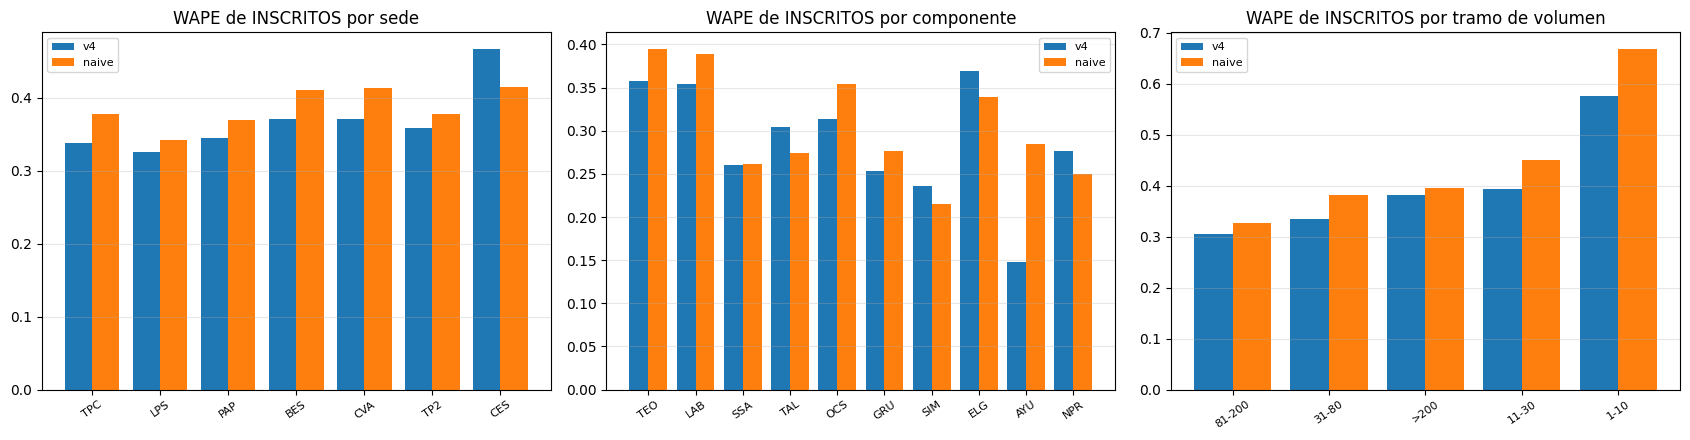

In [42]:
# ══════════════════════════════════════════════════════════════════════════════
# FASE 4h · ERROR DE INSCRITOS POR SEGMENTO   (T08 · T17 §10)
# ══════════════════════════════════════════════════════════════════════════════
# LA VARIABLE OBJETIVO ES `INSCRITOS` por PERIODO × MATERIA × CURSO × COMPONENTE
# × CAMPUS. Todo lo demás —número de secciones, cupos— es una derivada aritmética
# posterior. Esta celda mide el error SOBRE LOS INSCRITOS, que es lo que el
# modelo realmente pronostica.
#
# POR QUÉ NO ALCANZA EL WAPE GLOBAL: 0,355 es un solo número sobre 24.884 filas.
# Puede esconder un 0,20 en TEO-TPC y un 0,80 en GRU-RCG. Quien planifica la
# oferta necesita saber en qué segmentos la cifra es sólida y en cuáles es un
# número con forma de dato.
#
# Se re-ejecuta el walk-forward del v4 —misma lógica de la FASE 4g: blend `w` y
# factor `fac` calibrados en el fold anterior a cada origen— pero guardando la
# predicción FILA A FILA para poder segmentarla.
#
# Produce tres objetos que consume la proyección (FASE 7b) para el WAPE por línea:
#     WAPE_SERIE     · WAPE histórico de cada serie individual
#     WAPE_CAMCOMP   · WAPE por CAMPUS × COMPONENTE
#     WAPE_GLOBAL    · WAPE global (último recurso)

_D = _d4 if '_d4' in globals() else _d2
MIN_OBS_SERIE = 3          # observaciones mínimas para fiarse del WAPE de una serie

print("═" * 78); print("RECONSTRUYENDO LAS PREDICCIONES DEL v4 FILA A FILA"); print("═" * 78)

_filas = []
for _o in ORIGENES_WF:
    tr_all = _D[_D['PERIODO'] <  _o]
    te_all = _D[_D['PERIODO'] == _o]
    if len(tr_all) < 1000 or len(te_all) == 0:
        continue
    _con = lambda d: d[d['ins_lag_1y'].notna() & (d['ins_lag_1y'] > 0)]
    tr, te = _con(tr_all), _con(te_all)

    # mismo fold de calibración que la FASE 4g
    w_opt, fac = 0.5, 1.0
    _pc_per = sorted(tr['PERIODO'].unique())[-1]
    _trc, _tec = _con(tr_all[tr_all['PERIODO'] < _pc_per]), _con(tr_all[tr_all['PERIODO'] == _pc_per])
    if len(_trc) > 500 and len(_tec) > 50:
        _p = np.clip(np.expm1(np.log1p(_tec['ins_lag_1y'].values) +
                              _fit_corr_v4(_trc).predict(_tec[FEATURES_V4])), 0, None)
        _b = _tec['ins_lag_1y'].values; _yc = _tec['INSCRITOS'].values
        w_opt = float(GRID_W[np.argmin([np.abs(_yc - (w*_p + (1-w)*_b)).sum()/_yc.sum()
                                        for w in GRID_W])])
        _mix = w_opt*_p + (1-w_opt)*_b
        if _mix.sum() > 0:
            fac = float(np.clip(_yc.sum()/_mix.sum(), *CLIP_SEG))

    p_mod = np.clip(np.expm1(np.log1p(te['ins_lag_1y'].values) +
                             _fit_corr_v4(tr).predict(te[FEATURES_V4])), 0, None)
    p_v4 = np.clip((w_opt*p_mod + (1-w_opt)*te['ins_lag_1y'].values) * fac, 0, None)

    _cols = [c for c in DIMS + ['INSCRITOS', 'ins_lag_1y', 'desc_nivel_asig',
                                'n_periodos_historia'] if c in te.columns]
    _f = te[_cols].copy()
    _f['pred_v4'] = p_v4
    _f['pred_naive'] = te['ins_lag_1y'].values
    _filas.append(_f)
    print(f"   ✓ origen {_o}   n={len(_f):,}  (w={w_opt:.1f}, fac={fac:.3f})")

pred_wf = pd.concat(_filas, ignore_index=True)
print(f"\nPredicciones reconstruidas: {pred_wf.shape[0]:,} filas · "
      f"{pred_wf['INSCRITOS'].sum():,} inscritos reales")


def _met(g):
    """Métricas de INSCRITOS de un segmento. WAPE = suma|error| / suma real."""
    y, p, b = g['INSCRITOS'].values, g['pred_v4'].values, g['pred_naive'].values
    _sy = y.sum()
    return pd.Series({
        'n': len(g), 'inscritos': int(_sy),
        'MAE': np.abs(y - p).mean(),
        'WAPE': np.abs(y - p).sum() / _sy if _sy else np.nan,
        'sesgo': (p - y).sum() / _sy if _sy else np.nan,
        'WAPE_naive': np.abs(y - b).sum() / _sy if _sy else np.nan,
    })


def _tabla(keys, titulo, minimo=0):
    t = pred_wf.groupby(keys, observed=True).apply(_met, include_groups=False)
    t = t[t['n'] >= minimo].copy()
    t['gana_naive'] = np.where(t['WAPE'] < t['WAPE_naive'], '✔', '✘')
    t['mejora'] = (t['WAPE_naive'] - t['WAPE']) / t['WAPE_naive']
    t['%_volumen'] = t['inscritos'] / pred_wf['INSCRITOS'].sum()
    print("\n" + "═" * 78); print(titulo); print("═" * 78)
    print(t.sort_values('inscritos', ascending=False)
           .assign(n=lambda d: d['n'].astype(int))
           .round({'MAE': 1, 'WAPE': 3, 'sesgo': 3, 'WAPE_naive': 3,
                   'mejora': 3, '%_volumen': 4}).to_string())
    return t

_glob = _met(pred_wf)
print("\n" + "═" * 78); print("GLOBAL — error sobre INSCRITOS"); print("═" * 78)
print(f"  filas {int(_glob['n']):,} · inscritos {int(_glob['inscritos']):,}")
print(f"  MAE   {_glob['MAE']:.1f} inscritos por combinación")
print(f"  WAPE  {_glob['WAPE']:.3f}   (naive {_glob['WAPE_naive']:.3f})")
print(f"  sesgo {_glob['sesgo']:+.3f}")

wape_campus     = _tabla(['CAMPUS'],      'POR SEDE')
wape_componente = _tabla(['COMPONENTE'],  'POR COMPONENTE')
if 'desc_nivel_asig' in pred_wf.columns:
    wape_nivel  = _tabla(['desc_nivel_asig'], 'POR NIVEL ACADÉMICO')

# ── tramo de volumen: se define con ins_lag_1y (conocido de antemano), no con el
#    target, para que sirva igual al clasificar la proyección futura ───────────
_bins = [0, 10, 30, 80, 200, np.inf]
_lbl  = ['1-10', '11-30', '31-80', '81-200', '>200']
pred_wf['tramo_volumen'] = pd.cut(pred_wf['ins_lag_1y'], bins=_bins, labels=_lbl)
wape_tramo = _tabla(['tramo_volumen'], 'POR TRAMO DE VOLUMEN (según ins_lag_1y)')

if 'n_periodos_historia' in pred_wf.columns:
    pred_wf['madurez'] = pd.cut(pred_wf['n_periodos_historia'], bins=[-1, 2, 5, 10, np.inf],
                                labels=['≤2 períodos', '3-5', '6-10', '>10'])
    wape_madurez = _tabla(['madurez'], 'POR MADUREZ DE LA SERIE')

wape_camcomp = _tabla(['CAMPUS', 'COMPONENTE'], 'POR SEDE × COMPONENTE (≥100 filas)', minimo=100)

# ── WAPE por SERIE — base del indicador por línea de la proyección ───────────
wape_serie = (pred_wf.groupby(['MATERIA', 'CURSO', 'COMPONENTE', 'CAMPUS'], observed=True)
                     .apply(_met, include_groups=False))
wape_serie = wape_serie[wape_serie['n'] >= MIN_OBS_SERIE]
print("\n" + "═" * 78); print(f"WAPE POR SERIE (con ≥{MIN_OBS_SERIE} observaciones)"); print("═" * 78)
print(f"  series con WAPE propio: {len(wape_serie):,} de "
      f"{pred_wf.groupby(SERIE, observed=True).ngroups:,} evaluadas")
print(f"  cubren {wape_serie['inscritos'].sum()/pred_wf['INSCRITOS'].sum():.1%} del volumen")
print(wape_serie['WAPE'].describe(percentiles=[.1,.25,.5,.75,.9]).round(3).to_string())

# ── Objetos que consume la FASE 7b ──────────────────────────────────────────
WAPE_GLOBAL  = float(_glob['WAPE'])
WAPE_SERIE   = wape_serie['WAPE']
WAPE_CAMCOMP = wape_camcomp['WAPE']

print("\n" + "═" * 78); print("LECTURA"); print("═" * 78)
_peor = wape_campus.sort_values('WAPE', ascending=False).head(1)
_mejor = wape_campus.sort_values('WAPE').head(1)
print(f"  · Sedes: mejor {_mejor.index[0]} (WAPE {_mejor['WAPE'].iloc[0]:.3f}) · "
      f"peor {_peor.index[0]} (WAPE {_peor['WAPE'].iloc[0]:.3f})")
_pierde = wape_camcomp[wape_camcomp['gana_naive'] == '✘']
print(f"  · Segmentos sede×componente donde el naive GANA: {len(_pierde)} de "
      f"{len(wape_camcomp)}  ({_pierde['%_volumen'].sum():.1%} del volumen)")
if len(_pierde):
    print("    ", list(_pierde.index[:6]))
print(f"  · El error NO es uniforme: WAPE por sede va de {wape_campus['WAPE'].min():.3f} "
      f"a {wape_campus['WAPE'].max():.3f}")
print("  · `tramo_volumen` es la lectura de negocio: en las series chicas el WAPE")
print("    relativo es alto pero el error ABSOLUTO (MAE) es de pocos inscritos.")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for _i, (_t, _n) in enumerate([(wape_campus, 'sede'), (wape_componente, 'componente'),
                               (wape_tramo, 'tramo de volumen')]):
    _s = _t.sort_values('inscritos', ascending=False).head(10)
    _x = np.arange(len(_s))
    ax[_i].bar(_x - 0.2, _s['WAPE'], 0.4, label='v4')
    ax[_i].bar(_x + 0.2, _s['WAPE_naive'], 0.4, label='naive')
    ax[_i].set_xticks(_x); ax[_i].set_xticklabels([str(v) for v in _s.index], rotation=35, fontsize=8)
    ax[_i].set_title(f'WAPE de INSCRITOS por {_n}'); ax[_i].legend(fontsize=8)
    ax[_i].grid(alpha=.3, axis='y')
plt.tight_layout(); plt.show()


══════════════════════════════════════════════════════════════════════════════
ENTRENANDO LAS VARIANTES SOBRE EL MISMO WALK-FORWARD
══════════════════════════════════════════════════════════════════════════════
   ✓ v4  (sin peso)
   ✓ v5a (peso lineal)
   ✓ v5b (peso sqrt)
   ✓ v5c (peso log1p)

══════════════════════════════════════════════════════════════════════════════
GLOBAL — la métrica que decide es `err_abs` (inscritos)
══════════════════════════════════════════════════════════════════════════════
                     MAE    WAPE   err_abs   sesgo  err_abs_vs_v4
variante                                                         
v4  (sin peso)     24.58  0.3663  596407.0 -0.0139         0.0000
v5a (peso lineal)  24.14  0.3596  585622.0 -0.0006        -0.0181
v5b (peso sqrt)    24.32  0.3623  589962.0 -0.0032        -0.0108
v5c (peso log1p)   24.42  0.3639  592551.0 -0.0087        -0.0065
seasonal_naive     25.24  0.3760  612233.0  0.0068         0.0265

  err_abs = suma de |erro

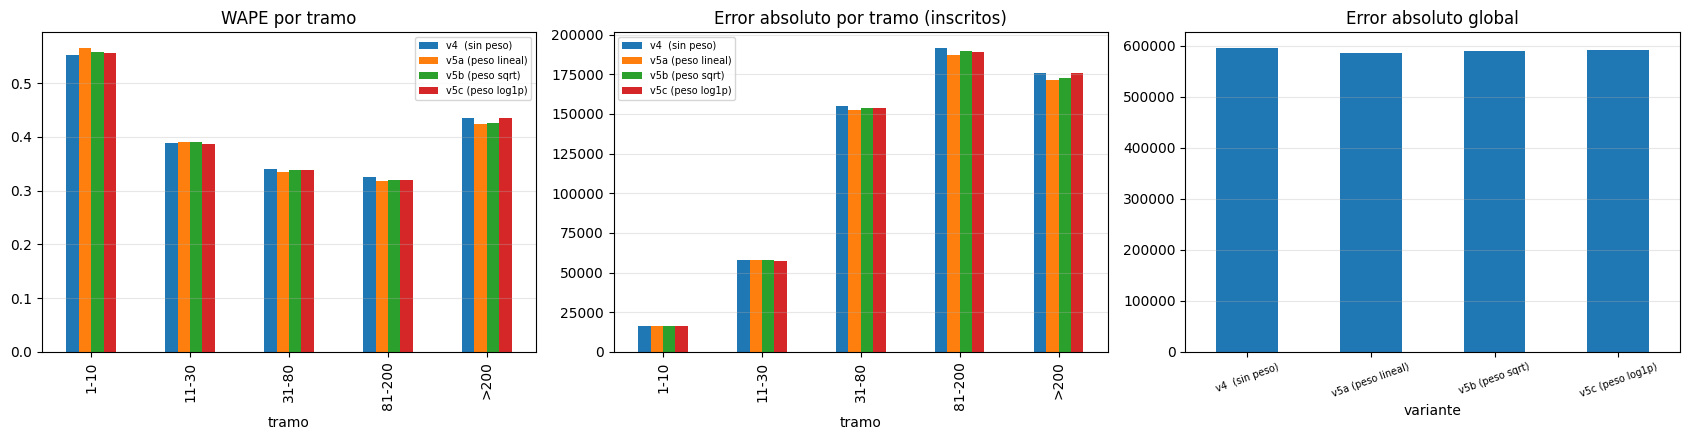

In [43]:
# ══════════════════════════════════════════════════════════════════════════════
# FASE 4i · PONDERACIÓN POR VOLUMEN — ¿se puede mejorar el tramo alto?   (T11)
# ══════════════════════════════════════════════════════════════════════════════
# EL PROBLEMA (medido en la FASE 4h): el aporte del modelo es inverso al tamaño de
# la serie. Mejora +21% donde el error son 4 inscritos y +1,2% donde son 124.
#
#   tramo      % filas   % del error absoluto   mejora vs naive
#   >200          4,9%          27,8%                +1,2%
#   81-200       19,4%          31,6%                +8,9%
#   1-10         13,5%           2,7%               +21,3%
#
# LA CAUSA: el target es log1p(y) − log1p(lag). En espacio logarítmico un error del
# 20% en una serie de 2.000 pesa IGUAL que en una de 10, así que LightGBM reparte
# su atención por igual. Pero en inscritos el primero son 400 alumnos (~10 secciones
# mal dimensionadas) y el segundo son 2 (ninguna). El modelo optimiza una métrica
# que el negocio no tiene.
#
# LA PRUEBA: pasar `sample_weight` en el .fit() para que el entrenamiento pese cada
# fila según su volumen. Se comparan tres formas de ponderar, porque la agresividad
# importa: con peso lineal la serie de 9.532 inscritos pesa 953× más que una de 10,
# y eso puede desestabilizar el ajuste.
#
# HIPÓTESIS EXPLÍCITA, para no acomodar la lectura al resultado:
#   se espera que el WAPE global EMPEORE un poco (las series chicas dejan de estar
#   tan atendidas) mientras el ERROR ABSOLUTO agregado y el tramo >200 mejoran.
#   Si el error absoluto no baja, la idea se descarta.

PESOS = {
    'v4  (sin peso)':      None,
    'v5a (peso lineal)':   lambda d: d['ins_lag_1y'].values,
    'v5b (peso sqrt)':     lambda d: np.sqrt(d['ins_lag_1y'].values),
    'v5c (peso log1p)':    lambda d: np.log1p(d['ins_lag_1y'].values),
}

_D = _d4 if '_d4' in globals() else _d2


def _fit_pond(tr, wfun):
    """Mismo modelo del v4, con sample_weight opcional."""
    y = (np.log1p(tr['INSCRITOS']) - np.log1p(tr['ins_lag_1y'])).clip(-CLIP_CORR, CLIP_CORR)
    m = lgb.LGBMRegressor(n_estimators=600, learning_rate=0.05, num_leaves=63,
                          min_child_samples=20, subsample=0.8, colsample_bytree=0.8,
                          random_state=42, verbose=-1)
    m.fit(tr[FEATURES_V4], y,
          sample_weight=(wfun(tr) if wfun is not None else None),
          categorical_feature=FEAT_CAT_V4)
    return m


print("═" * 78); print("ENTRENANDO LAS VARIANTES SOBRE EL MISMO WALK-FORWARD"); print("═" * 78)

_pred = []
for _nom, _wf in PESOS.items():
    for _o in ORIGENES_WF:
        tr_all, te_all = _D[_D['PERIODO'] < _o], _D[_D['PERIODO'] == _o]
        if len(tr_all) < 1000 or len(te_all) == 0:
            continue
        _con = lambda d: d[d['ins_lag_1y'].notna() & (d['ins_lag_1y'] > 0)]
        tr, te = _con(tr_all), _con(te_all)

        # calibración en el fold anterior, igual que el v4 (cada variante recalibra
        # su propio w y fac: si no, la comparación sería injusta)
        w_opt, fac = 0.5, 1.0
        _pc = sorted(tr['PERIODO'].unique())[-1]
        _trc, _tec = _con(tr_all[tr_all['PERIODO'] < _pc]), _con(tr_all[tr_all['PERIODO'] == _pc])
        if len(_trc) > 500 and len(_tec) > 50:
            _p = np.clip(np.expm1(np.log1p(_tec['ins_lag_1y'].values) +
                                  _fit_pond(_trc, _wf).predict(_tec[FEATURES_V4])), 0, None)
            _b, _yc = _tec['ins_lag_1y'].values, _tec['INSCRITOS'].values
            w_opt = float(GRID_W[np.argmin([np.abs(_yc - (w*_p + (1-w)*_b)).sum()/_yc.sum()
                                            for w in GRID_W])])
            _mix = w_opt*_p + (1-w_opt)*_b
            if _mix.sum() > 0:
                fac = float(np.clip(_yc.sum()/_mix.sum(), *CLIP_SEG))

        _pm = np.clip(np.expm1(np.log1p(te['ins_lag_1y'].values) +
                               _fit_pond(tr, _wf).predict(te[FEATURES_V4])), 0, None)
        _pf = np.clip((w_opt*_pm + (1-w_opt)*te['ins_lag_1y'].values) * fac, 0, None)

        _f = te[DIMS + ['INSCRITOS', 'ins_lag_1y']].copy()
        _f['variante'], _f['pred'], _f['naive'] = _nom, _pf, te['ins_lag_1y'].values
        _pred.append(_f)
    print(f"   ✓ {_nom}")

comp = pd.concat(_pred, ignore_index=True)
comp['tramo'] = pd.cut(comp['ins_lag_1y'], [0, 10, 30, 80, 200, np.inf],
                       labels=['1-10', '11-30', '31-80', '81-200', '>200'])


def _m(g):
    y, p = g['INSCRITOS'].values, g['pred'].values
    _e = np.abs(y - p)
    return pd.Series({'MAE': _e.mean(), 'WAPE': _e.sum()/y.sum(),
                      'err_abs': _e.sum(), 'sesgo': (p-y).sum()/y.sum()})


# ── 1) GLOBAL ────────────────────────────────────────────────────────────────
_g = comp.groupby('variante', observed=True).apply(_m, include_groups=False)
_nv = comp[comp['variante'] == 'v4  (sin peso)']
_en = np.abs(_nv['INSCRITOS'] - _nv['naive'])
_g.loc['seasonal_naive'] = {'MAE': _en.mean(), 'WAPE': _en.sum()/_nv['INSCRITOS'].sum(),
                            'err_abs': _en.sum(),
                            'sesgo': (_nv['naive']-_nv['INSCRITOS']).sum()/_nv['INSCRITOS'].sum()}
_g['err_abs_vs_v4'] = _g['err_abs'] / _g.loc['v4  (sin peso)', 'err_abs'] - 1

print("\n" + "═" * 78); print("GLOBAL — la métrica que decide es `err_abs` (inscritos)"); print("═" * 78)
print(_g.round({'MAE': 2, 'WAPE': 4, 'err_abs': 0, 'sesgo': 4, 'err_abs_vs_v4': 4}).to_string())
print("\n  err_abs = suma de |error| en INSCRITOS. Es lo que el negocio paga:")
print("  cada inscrito mal proyectado es capacidad mal dimensionada.")

# ── 2) POR TRAMO — el objetivo del experimento ───────────────────────────────
_t = (comp.groupby(['tramo', 'variante'], observed=True).apply(_m, include_groups=False)
          .reset_index())
print("\n" + "═" * 78); print("WAPE POR TRAMO DE VOLUMEN"); print("═" * 78)
print(_t.pivot(index='tramo', columns='variante', values='WAPE').round(4).to_string())
print("\n" + "═" * 78); print("MAE POR TRAMO (inscritos)"); print("═" * 78)
print(_t.pivot(index='tramo', columns='variante', values='MAE').round(2).to_string())
print("\n" + "═" * 78); print("ERROR ABSOLUTO POR TRAMO — dónde se gana o se pierde"); print("═" * 78)
_ea = _t.pivot(index='tramo', columns='variante', values='err_abs')
_base = _ea['v4  (sin peso)'].copy()
_delta = pd.DataFrame({_c + ' Δ%': (_ea[_c] / _base - 1)
                       for _c in _ea.columns if _c != 'v4  (sin peso)'})
# los absolutos y los porcentajes se imprimen aparte: con un round(0) común, los
# Δ% (del orden de −0,04) se aplastaban a 0,0 y la tabla no decía nada.
print(_ea.round(0).to_string())
print("\nΔ% del error absoluto respecto al v4 (negativo = mejora):")
print(_delta.map(lambda v: f'{v:+.2%}').to_string())

# ── 3) VEREDICTO ─────────────────────────────────────────────────────────────
print("\n" + "═" * 78); print("VEREDICTO"); print("═" * 78)
_mejor = _g.drop(index='seasonal_naive')['err_abs'].idxmin()
_d_glob = _g.loc[_mejor, 'err_abs'] / _g.loc['v4  (sin peso)', 'err_abs'] - 1
_alto_v4 = _ea.loc['>200', 'v4  (sin peso)']
_alto_mj = _ea.loc['>200', _mejor]
_d_alto = _alto_mj / _alto_v4 - 1
print(f"  Mejor variante por error absoluto: {_mejor}")
print(f"    error absoluto global : {_d_glob:+.2%} vs v4")
print(f"    tramo >200            : {_d_alto:+.2%} vs v4")
print(f"    WAPE global           : {_g.loc[_mejor,'WAPE']:.4f} vs {_g.loc['v4  (sin peso)','WAPE']:.4f} del v4")
print(f"    sesgo                 : {_g.loc[_mejor,'sesgo']:+.4f} vs {_g.loc['v4  (sin peso)','sesgo']:+.4f}")
if _d_glob < -0.01 and _d_alto < -0.01:
    print("\n  ✅ LA PONDERACIÓN FUNCIONA: baja el error absoluto global Y el del tramo alto.")
    print("     Evaluar promoverla a modelo vigente (implica re-emitir la proyección).")
elif _d_alto < -0.01:
    print("\n  ⚠️ MEJORA EL TRAMO ALTO pero no el error absoluto global: el trade-off")
    print("     depende de cuánto valga acertar en las asignaturas grandes.")
else:
    print("\n  ❌ NO FUNCIONA: la ponderación no reduce el error donde debía.")
    print("     Se descarta y queda documentado como camino cerrado.")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
_pv = _t.pivot(index='tramo', columns='variante', values='WAPE')
_pv.plot(kind='bar', ax=ax[0]); ax[0].set_title('WAPE por tramo'); ax[0].legend(fontsize=7)
_pv2 = _t.pivot(index='tramo', columns='variante', values='err_abs')
_pv2.plot(kind='bar', ax=ax[1]); ax[1].set_title('Error absoluto por tramo (inscritos)'); ax[1].legend(fontsize=7)
_g.drop(index='seasonal_naive')['err_abs'].plot(kind='bar', ax=ax[2])
ax[2].set_title('Error absoluto global'); ax[2].tick_params(axis='x', rotation=20, labelsize=7)
for _a in ax: _a.grid(alpha=.3, axis='y')
plt.tight_layout(); plt.show()


══════════════════════════════════════════════════════════════════════════════
TARGET DE SUPERVIVENCIA
══════════════════════════════════════════════════════════════════════════════
Períodos parciales (<50% del típico de su TT): [202620]   <- excluidos como sucesor
Períodos etiquetables (con sucesor cerrado): 49 de 55
Filas etiquetadas: 129,152  |  tasa de supervivencia: 81.8%
  · períodos con tasa baja pero < 100 filas (no evaluables): {201515: 2, 201615: 5}
  ✔ guards OK — tasa global 81.8% | por período evaluable (53.3% - 93.2%, 47 de 49 períodos)
Features: 22

══════════════════════════════════════════════════════════════════════════════
VALIDACIÓN WALK-FORWARD
══════════════════════════════════════════════════════════════════════════════
   ✓ 202310   n=4,179  supervivencia real 85.7%  AUC 0.857
   ✓ 202320   n=4,049  supervivencia real 84.3%  AUC 0.879
   ✓ 202410   n=4,449  supervivencia real 75.3%  AUC 0.742
   ✓ 202420   n=4,478  supervivencia real 75.7%  AUC 0.870
   ✓ 202510

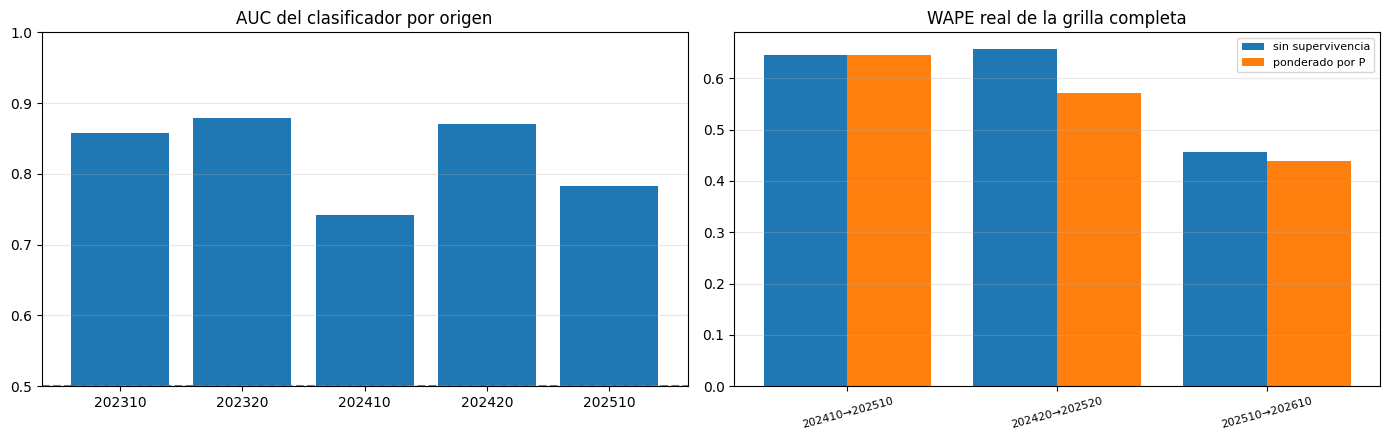

In [44]:
# ══════════════════════════════════════════════════════════════════════════════
# FASE 4j · MODELO DE SUPERVIVENCIA — ¿la asignatura se seguirá dictando?
# ══════════════════════════════════════════════════════════════════════════════
# EL PROBLEMA QUE NINGUNA MÉTRICA ANTERIOR MEDÍA:
# Todo el backtesting (F3–F4i) evalúa sobre `te = _d2[PERIODO == origen]`, es decir
# las filas que SÍ existieron. Pero la proyección construye la grilla con el período
# FUENTE, que incluye series que van a desaparecer. Ese error nunca se midió.
#
#     período      WAPE reportado    WAPE real     volumen a series que no se dictan
#     202510           0,396           0,729                  25,1%
#     202520           0,413           0,768                  27,1%
#     202610           0,322           0,541                  17,6%
#     ─────────────────────────────────────────────────────────────────────────
#     media            0,418           0,634            +52% de error real
#
# Entre el 13% y el 30% de las series desaparecen de un período al siguiente, y un
# 26-29% de las del período destino son nuevas (que la grilla ni siquiera contempla).
#
# LA SOLUCIÓN — descomponer en dos partes (hurdle model):
#
#     demanda_esperada  =  P(la serie se dicte)  ×  E[demanda | se dicta]
#                          └── esta celda ──┘      └── el modelo v5 ──┘
#
# ⚠️ EL TARGET NO ES TRIVIAL: solo se puede etiquetar un período si su SUCESOR está
# cerrado. Si el sucesor está parcial (p. ej. 202620 recién abriendo), casi ninguna
# serie figura como superviviente y la etiqueta es un artefacto. Sin este filtro,
# 202520 aparecía con 2,0% de supervivencia en vez de ~70%.

print("═" * 78); print("TARGET DE SUPERVIVENCIA"); print("═" * 78)

_per_all = sorted(_d2['PERIODO'].unique())

# ⚠️ LOS PERÍODOS PARCIALES SE CALCULAN AQUÍ, NO SE HEREDAN.
# Esto era `globals().get('PERIODOS_PARCIALES', [])`, pero esa variable se define en
# la FASE 7b, CINCO celdas más adelante: con el kernel limpio llegaba vacía y no se
# filtraba nada. El notebook solo "funcionaba" al reejecutarlo sin reiniciar el
# kernel, heredando el valor de la corrida anterior — resultado no reproducible.
# Efecto medido cuando llega vacía: 202620 está al 3% de su volumen típico, así que
# 202520 se etiquetaba contra un período sin cerrar y salía con ~2% de
# supervivencia; el clasificador aprendía eso y la FASE 7b abortaba con
# P(se dicte) = 0,025.  Mismo criterio y umbral que la FASE 7b.
UMBRAL_COMPLETITUD_SV = 0.50
_volp = _d2.groupby('PERIODO')['INSCRITOS'].sum()
_refp = {}
for _p in _volp.index:
    _prev = [_q for _q in _volp.index if _q % 100 == _p % 100 and _q < _p]
    _refp[_p] = _volp[_prev].median() if _prev else np.nan
_complp = pd.Series({_p: (_volp[_p] / _refp[_p]
                          if pd.notna(_refp[_p]) and _refp[_p] > 0 else np.nan)
                     for _p in _volp.index})
PERIODOS_PARCIALES_SV = sorted(_complp[_complp < UMBRAL_COMPLETITUD_SV].index.tolist())
print(f"Períodos parciales (<{UMBRAL_COMPLETITUD_SV:.0%} del típico de su TT): "
      f"{PERIODOS_PARCIALES_SV}   <- excluidos como sucesor")

_CERR_S = set(_per_all) - set(PERIODOS_PARCIALES_SV)
_SUC = {p: p + 100 for p in _per_all if (p + 100) in _CERR_S}
print(f"Períodos etiquetables (con sucesor cerrado): {len(_SUC)} de {len(_per_all)}")

_ex = set(map(tuple, _d2[SERIE + ['PERIODO']].values))
_sv = _d2[_d2['PERIODO'].isin(_SUC)].copy()
_sv['sobrevive'] = [tuple(list(_r) + [_SUC[_p]]) in _ex
                    for _r, _p in zip(_sv[SERIE].values, _sv['PERIODO'])]
_tasa_sv = _sv['sobrevive'].mean()
print(f"Filas etiquetadas: {len(_sv):,}  |  tasa de supervivencia: {_tasa_sv:.1%}")

# ── GUARDS: abortan en vez de dejar pasar un target corrupto ─────────────
if not (0.55 <= _tasa_sv <= 0.95):
    raise ValueError(
        f"Tasa de supervivencia global {_tasa_sv:.1%}, fuera del rango plausible "
        f"55-95%. Revisar la detección de períodos parciales.")
# ⚠️ El guard por período exige un MÍNIMO DE FILAS para que la tasa signifique
# algo. Sin eso da falsos positivos: el TT 15 arrancaba en 2015 con 2 y 5 series
# (6 y 41 inscritos) y ninguna llegó al período siguiente — 0% de supervivencia
# sobre una base sin valor estadístico, que NO es corrupción de etiquetas.
# Lo que sí hay que atrapar es el caso 202520: 1,8% sobre 4.560 series.
MIN_FILAS_GUARD_SV = 100
_agg_per = _sv.groupby('PERIODO')['sobrevive'].agg(['mean', 'size'])
_tasa_x_per = _agg_per['mean']
_evaluables = _agg_per[_agg_per['size'] >= MIN_FILAS_GUARD_SV]
_sospechosos = _evaluables[_evaluables['mean'] < 0.30]
_ignorados = _agg_per[(_agg_per['size'] < MIN_FILAS_GUARD_SV) & (_agg_per['mean'] < 0.30)]
if len(_ignorados):
    print(f"  · períodos con tasa baja pero < {MIN_FILAS_GUARD_SV} filas (no evaluables): "
          f"{ {int(p): int(n) for p, n in _ignorados['size'].items()} }")
if len(_sospechosos):
    raise ValueError(
        f"Períodos con supervivencia < 30% sobre ≥{MIN_FILAS_GUARD_SV} filas: "
        f"{_sospechosos['mean'].round(3).to_dict()} (n={_sospechosos['size'].to_dict()}). "
        f"Su sucesor no está cerrado y no fue detectado como parcial: la etiqueta "
        f"es un artefacto, no una baja real.")
print(f"  ✔ guards OK — tasa global {_tasa_sv:.1%} | por período evaluable "
      f"({_evaluables['mean'].min():.1%} - {_evaluables['mean'].max():.1%}, "
      f"{len(_evaluables)} de {len(_agg_per)} períodos)")

# ── features del clasificador ───────────────────────────────────────────────
# Todo lo que se conoce ANTES de saber si la serie continúa. `INSCRITOS` y
# `n_secciones` del propio período sí entran: al decidir si una asignatura se
# vuelve a dictar, su tamaño y su oferta actual son justamente lo que se mira.
FEAT_SV_NUM = [c for c in ['INSCRITOS', 'n_secciones', 'ins_lag_1y', 'ins_lag_2y',
                           'ins_roll_mean_3y', 'ins_lag_prev', 'n_periodos_historia',
                           'antiguedad_serie', 'ANIO', 'TT', 'estandar_observado',
                           'carga_semanal', 'indice_reprobacion', 'ratio_ocupacion']
               if c in _sv.columns]
FEAT_SV_CAT = [c for c in SERIE + ['cod_modo_programacion', 'departamento/form_general',
                                   'cod_nivel_asig'] if c in _sv.columns]
for _c in FEAT_SV_CAT:
    _sv[_c] = _sv[_c].astype('category')
if 'vigente' in _sv.columns:
    _sv['vigente'] = _sv['vigente'].astype(float)
    FEAT_SV_NUM.append('vigente')
FEATURES_SV = FEAT_SV_NUM + FEAT_SV_CAT
print(f"Features: {len(FEATURES_SV)}")


def _fit_supervivencia(tr):
    m = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31,
                           min_child_samples=20, random_state=42, verbose=-1)
    m.fit(tr[FEATURES_SV], tr['sobrevive'].astype(int),
          categorical_feature=FEAT_SV_CAT)
    return m


# ── validación walk-forward ─────────────────────────────────────────────────
from sklearn.metrics import roc_auc_score

print("\n" + "═" * 78); print("VALIDACIÓN WALK-FORWARD"); print("═" * 78)
_rs = []
for _o in [p for p in ORIGENES_WF if p in _SUC]:
    _tr, _te = _sv[_sv['PERIODO'] < _o], _sv[_sv['PERIODO'] == _o]
    if len(_tr) < 2000 or len(_te) < 200:
        continue
    _m = _fit_supervivencia(_tr)
    _p = _m.predict_proba(_te[FEATURES_SV])[:, 1]
    _y = _te['sobrevive'].astype(int).values
    _volm = _te.loc[_y == 0, 'INSCRITOS'].sum()
    _r = dict(origen=_o, n=len(_te), tasa_real=_y.mean(), AUC=roc_auc_score(_y, _p))
    for _u in (0.3, 0.5, 0.7):
        _pm = _p < _u
        _r[f'capta_muerto_{_u}'] = _te.loc[(_y == 0) & _pm, 'INSCRITOS'].sum() / max(_volm, 1)
        _r[f'descarta_vivo_{_u}'] = (_te.loc[(_y == 1) & _pm, 'INSCRITOS'].sum() /
                                     max(_te.loc[_y == 1, 'INSCRITOS'].sum(), 1))
    _rs.append(_r)
    print(f"   ✓ {_o}   n={len(_te):,}  supervivencia real {_y.mean():.1%}  AUC {_r['AUC']:.3f}")

resultados_sv = pd.DataFrame(_rs)
print("\n" + "═" * 78); print("CAPACIDAD DEL CLASIFICADOR"); print("═" * 78)
print(resultados_sv.round(3).to_string(index=False))
_auc = resultados_sv['AUC'].mean()
print(f"\n  AUC medio: {_auc:.3f}")
print("\n  Por umbral (qué proporción del volumen se acierta / se sacrifica):")
for _u in (0.3, 0.5, 0.7):
    print(f"    P < {_u}:  captura {resultados_sv[f'capta_muerto_{_u}'].mean():5.1%} del volumen "
          f"que muere  ·  descarta por error {resultados_sv[f'descarta_vivo_{_u}'].mean():4.1%} del vivo")

# ── impacto real sobre el WAPE de la grilla completa ────────────────────────
print("\n" + "═" * 78); print("IMPACTO SOBRE EL WAPE REAL (grilla completa)"); print("═" * 78)
_imp = []
for _o in [p for p in ORIGENES_WF if p in _SUC][-3:]:
    _tr, _te = _sv[_sv['PERIODO'] < _o], _sv[_sv['PERIODO'] == _o]
    if len(_tr) < 2000:
        continue
    _p = _fit_supervivencia(_tr).predict_proba(_te[FEATURES_SV])[:, 1]
    _nx = _SUC[_o]
    _real = (_d2[_d2['PERIODO'] == _nx][SERIE + ['INSCRITOS']]
             .rename(columns={'INSCRITOS': 'real'}))
    _g = (_te[SERIE + ['INSCRITOS']].rename(columns={'INSCRITOS': 'naive'})
          .merge(_real, on=SERIE, how='left'))
    _g['real'] = _g['real'].fillna(0)
    _g['P'] = _p
    _w0 = np.abs(_g['real'] - _g['naive']).sum() / _g['real'].sum()
    _w1 = np.abs(_g['real'] - _g['naive'] * _g['P']).sum() / _g['real'].sum()
    _imp.append(dict(transicion=f'{_o}→{_nx}', WAPE_sin=_w0, WAPE_con=_w1, mejora=_w1/_w0 - 1))
    print(f"   {_o}→{_nx}:  {_w0:.3f}  ->  {_w1:.3f}   ({_w1/_w0-1:+.1%})")
impacto_sv = pd.DataFrame(_imp)
print(f"\n  Mejora media del WAPE real: {impacto_sv['mejora'].mean():+.1%}")
print("\n  ⚠️ Es una mejora REAL pero MODESTA. El clasificador discrimina bien (AUC")
print("     0,83) pero las series grandes que mueren son las más difíciles de")
print("     anticipar: con umbral 0,5 solo se captura ~15% del volumen que muere.")
print("     Ponderar por la probabilidad funciona mejor que aplicar un corte binario.")

# ── modelo final, entrenado con todo lo etiquetable ─────────────────────────
MODELO_SV = _fit_supervivencia(_sv)
print(f"\nModelo de supervivencia entrenado con {len(_sv):,} filas -> `MODELO_SV`")
print("  Lo consume la FASE 7b para agregar P(se dicte) a cada fila proyectada.")

_impsv = pd.Series(MODELO_SV.feature_importances_, index=FEATURES_SV).sort_values(ascending=False)
print("\nTop features:")
print(_impsv.head(8).to_string())

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].bar(resultados_sv['origen'].astype(str), resultados_sv['AUC'], color='#1f77b4')
ax[0].axhline(0.5, ls='--', c='gray'); ax[0].set_ylim(0.5, 1)
ax[0].set_title('AUC del clasificador por origen'); ax[0].grid(alpha=.3, axis='y')
_x = np.arange(len(impacto_sv))
ax[1].bar(_x - 0.2, impacto_sv['WAPE_sin'], 0.4, label='sin supervivencia')
ax[1].bar(_x + 0.2, impacto_sv['WAPE_con'], 0.4, label='ponderado por P')
ax[1].set_xticks(_x); ax[1].set_xticklabels(impacto_sv['transicion'], rotation=15, fontsize=8)
ax[1].set_title('WAPE real de la grilla completa'); ax[1].legend(fontsize=8)
ax[1].grid(alpha=.3, axis='y')
plt.tight_layout(); plt.show()


   ✓ origen 202310
   ✓ origen 202320
   ✓ origen 202410
   ✓ origen 202420
   ✓ origen 202510
   ✓ origen 202520
   ✓ origen 202610

══════════════════════════════════════════════════════════════════════════════
CALIBRACIÓN DE LOS CUANTILES
══════════════════════════════════════════════════════════════════════════════
               cobertura_real  cobertura_teorica  pinball  media_pred  desvio
cuantil                                                                      
P10                     0.146                0.1    5.327      39.472   0.046
P50                     0.492                0.5   11.176      64.333  -0.008
P90                     0.828                0.9    6.813      88.802  -0.072
ancho_P10_P90           0.681                0.8      NaN      49.331  -0.119

Lectura (T17 §9):
  P10: cobertura real 14.6% vs teórica 10%  (+4.6%)  ✅ bien calibrado
  P50: cobertura real 49.2% vs teórica 50%  (-0.8%)  ✅ bien calibrado
  P90: cobertura real 82.8% vs teórica 90%  (-7.2%) 

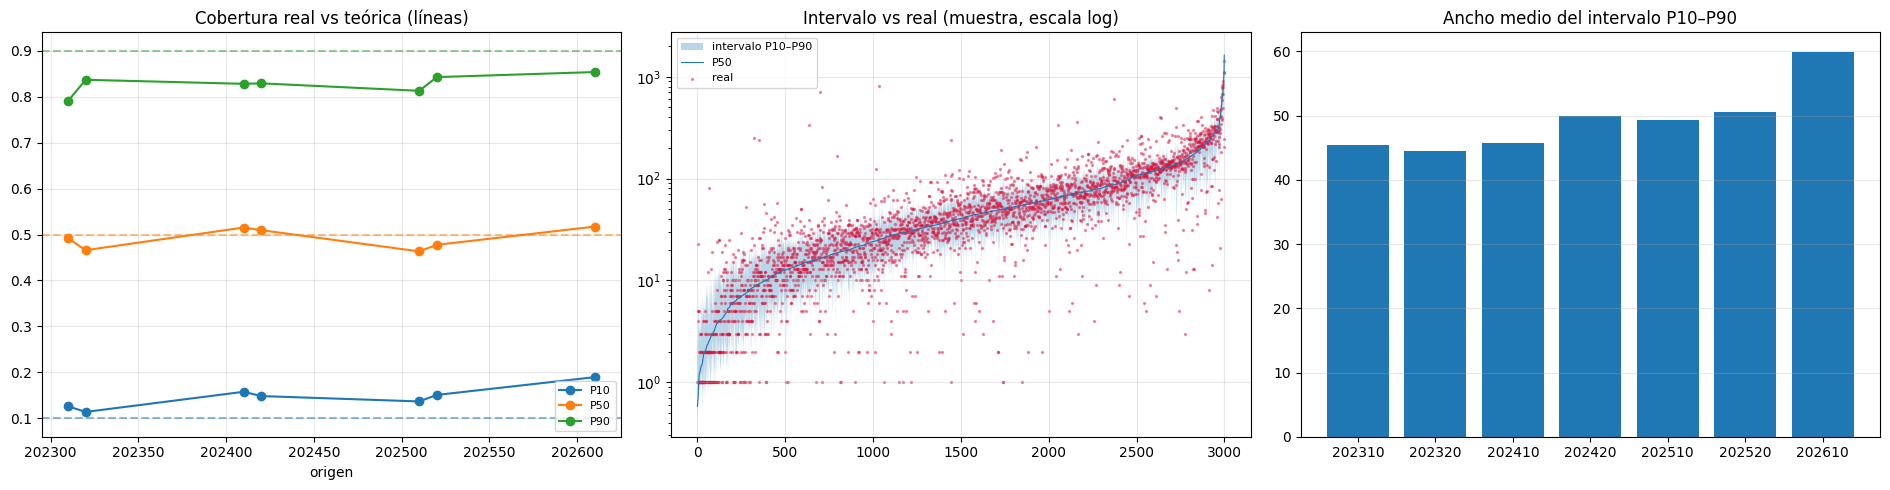

In [45]:
# ══════════════════════════════════════════════════════════════════════════════
# FASE 5 · PRONÓSTICO PROBABILÍSTICO — cuantiles P10 / P50 / P90   (T17 §9)
# ══════════════════════════════════════════════════════════════════════════════
# "Casi ninguna decisión de negocio se toma con la media del pronóstico. El stock
#  de seguridad, la capacidad, la dotación — todas viven en un CUANTIL ALTO, porque
#  el costo de quedarse corto no es igual al de sobrar." (T17 §9)
#
# Aquí: el costo de sub-dimensionar (estudiantes sin cupo, secciones que se abren
# a última hora) NO es igual al de sobre-dimensionar (sección semivacía). Por eso
# la planificación debe decidir con el P90, no con el punto.
#
# Implementación: LightGBM con objective='quantile' sobre el MISMO target de
# corrección del v3, un modelo por cuantil, y se invierte igual que el puntual.
#
# ⚠️ REGLA DE EVALUACIÓN (T17 §9): "un intervalo se evalúa por su COBERTURA, no por
# lo angosto". Un P90 es honesto si el valor real cae por debajo ~90% de las veces.
# Un intervalo angosto que solo cubre el 60% da falsa seguridad.

CUANTILES = [0.10, 0.50, 0.90]

def _fit_cuantil(tr, feats, alpha):
    """Cuantil de la corrección. SIN ponderar por volumen — y es a propósito.

    ⛔ NO llevar aquí el `sample_weight` del v5. Dos razones, ambas verificadas:

    1. SEMÁNTICA. Ponderando, el "P50" deja de ser "el valor bajo el cual cae el 50%
       de las FILAS" y pasa a ser "bajo el cual cae el 50% del VOLUMEN". Son cosas
       distintas, y la banda que se entrega es por fila. Medido: la cobertura del
       P50 caía de 0,487 a 0,446 al ponderar.
    2. ESTABILIDAD. Con `objective='quantile'` y pesos de hasta 9.532, las hojas
       producen correcciones enormes y `expm1` desborda a infinito (pinball = inf).

    El peso del v5 vive solo en el modelo PUNTUAL (`_fit_corr_v4`), que es donde
    minimizar el error absoluto agregado tiene sentido. — El ALGORITMO, en cambio,
    sí es el mismo desde la FASE 5c: CatBoost también gana aquí, y sin descentrar
    el P50 (ver el bloque de abajo)."""
    y = (np.log1p(tr['INSCRITOS']) - np.log1p(tr['ins_lag_1y'])).clip(-CLIP_CORR, CLIP_CORR)
    _cats = [c for c in (FEAT_CAT_V4 if 'FEAT_CAT_V4' in globals() else FEAT_CAT)
             if c in feats]
    # ⭐ ALGORITMO: CatBoost (2026-08-27, FASE 5c). Medido sobre 4 orígenes, SIN CQR:
    #      pinball   LightGBM 8,78   CatBoost 7,90   (−10%)
    #      cob. P90  LightGBM 81,9%  CatBoost 84,5%
    #      intervalo LightGBM 65,2%  CatBoost 67,9%
    #      ancho     LightGBM 54,6   CatBoost 53,0
    # Mejora la cobertura Y estrecha el intervalo a la vez — no es un trade-off.
    # 🔑 Y sobre todo NO DESCENTRA EL P50 (50,5% vs 49,9%), que era la condición
    #    de veto: el precedente D-17 mostró que un cuantil puede mejorar en error y
    #    descentrarse (0,487 -> 0,446), y eso el CQR no lo corrige.
    # ⚠️ Cuesta ~12x (681 s vs 56 s) y duplica los cuantiles cruzados (0,82% ->
    #    1,63%); el reordenamiento por fila de la F7b los absorbe, pero conviene
    #    vigilar cuántas filas reporta.
    if globals().get('USAR_CATBOOST'):
        m = CatBoostRegressor(loss_function=f'Quantile:alpha={alpha}', iterations=600,
                              learning_rate=0.05, depth=8, random_seed=42, verbose=0)
        m.fit(_cat_str(tr[feats], _cats), y, cat_features=list(_cats))
        return _CatWrap(m, _cats)
    m = lgb.LGBMRegressor(objective='quantile', alpha=alpha,
                          n_estimators=600, learning_rate=0.05, num_leaves=63,
                          min_child_samples=20, random_state=42, verbose=-1)
    m.fit(tr[feats], y, categorical_feature=[c for c in FEAT_CAT if c in feats])
    return m


def _pred_corr(m, X):
    # CatBoost predice sobre categóricas en str; LightGBM sobre 'category'.
    if m.__class__.__name__.startswith('CatBoost'):
        X = _cat_str(X, FEAT_CAT_V4 if 'FEAT_CAT_V4' in globals() else FEAT_CAT)
    """Predice la corrección ACOTADA al mismo rango en que se entrenó el target.

    El target va clipeado a ±CLIP_CORR, pero la predicción nunca se acotó: una hoja
    puede devolver un valor enorme y `expm1(log1p(lag) + eso)` desborda. Sin peso no
    ocurría; conviene la salvaguarda de todos modos."""
    return np.clip(m.predict(X), -CLIP_CORR, CLIP_CORR)

def _pinball(y, p, alpha):
    d = y - p
    return np.mean(np.maximum(alpha * d, (alpha - 1) * d))

_res5, _pred5 = [], []
for _o in ORIGENES_WF:
    tr_all = _d2[_d2['PERIODO'] <  _o]
    te_all = _d2[_d2['PERIODO'] == _o]
    if len(tr_all) < 1000 or len(te_all) == 0:
        continue
    _con = lambda d: d[d['ins_lag_1y'].notna() & (d['ins_lag_1y'] > 0)]
    tr, te = _con(tr_all), _con(te_all)
    y = te['INSCRITOS'].values
    _base_log = np.log1p(te['ins_lag_1y'].values)

    _q = {}
    for _a in CUANTILES:
        _m = _fit_cuantil(tr, FEATURES_V2, _a)
        _q[_a] = np.clip(np.expm1(_base_log + _pred_corr(_m, te[FEATURES_V2])), 0, None)

    # los cuantiles pueden cruzarse; se ordenan para garantizar P10 <= P50 <= P90
    _stack = np.sort(np.vstack([_q[a] for a in CUANTILES]), axis=0)
    _q = {a: _stack[i] for i, a in enumerate(CUANTILES)}

    for _a in CUANTILES:
        _res5.append(dict(origen=_o, cuantil=f'P{int(_a*100)}',
                          pinball=_pinball(y, _q[_a], _a),
                          cobertura_real=float((y <= _q[_a]).mean()),
                          cobertura_teorica=_a,
                          media_pred=_q[_a].mean()))
    _res5.append(dict(origen=_o, cuantil='ancho_P10_P90', pinball=np.nan,
                      cobertura_real=float(((y >= _q[0.10]) & (y <= _q[0.90])).mean()),
                      cobertura_teorica=0.80, media_pred=(_q[0.90] - _q[0.10]).mean()))
    _pred5.append(pd.DataFrame({'origen': _o, 'INSCRITOS': y,
                                'P10': _q[0.10], 'P50': _q[0.50], 'P90': _q[0.90],
                                'capacidad': te['maximos_estudiantes_seccion'].values
                                             if 'maximos_estudiantes_seccion' in te.columns else np.nan}))
    print(f"   ✓ origen {_o}")

resultados_q = pd.DataFrame(_res5)
pred_cuantiles = pd.concat(_pred5, ignore_index=True)

print("\n" + "═" * 78); print("CALIBRACIÓN DE LOS CUANTILES"); print("═" * 78)
_cal = (resultados_q.groupby('cuantil')
        .agg(cobertura_real=('cobertura_real','mean'), cobertura_teorica=('cobertura_teorica','mean'),
             pinball=('pinball','mean'), media_pred=('media_pred','mean')))
_cal['desvio'] = _cal['cobertura_real'] - _cal['cobertura_teorica']
print(_cal.round(3).to_string())

print("\nLectura (T17 §9):")
for _c in ['P10','P50','P90']:
    if _c in _cal.index:
        _d_ = _cal.loc[_c,'desvio']
        _ok = "✅ bien calibrado" if abs(_d_) < 0.05 else ("⚠️ conservador (cubre de más)" if _d_ > 0 else "⚠️ optimista (cubre de menos)")
        print(f"  {_c}: cobertura real {_cal.loc[_c,'cobertura_real']:.1%} vs teórica "
              f"{_cal.loc[_c,'cobertura_teorica']:.0%}  ({_d_:+.1%})  {_ok}")
print("\n  Un P90 optimista es PELIGROSO para planificar: promete cubrir 90% de los")
print("  casos y cubre menos -> secciones sub-dimensionadas más seguido de lo previsto.")

# Gráfico: distribución del intervalo y cobertura por origen
fig, ax = plt.subplots(1, 3, figsize=(19, 5))
_cv = resultados_q[resultados_q['cuantil'].isin(['P10','P50','P90'])].pivot(
        index='origen', columns='cuantil', values='cobertura_real')
_cv.plot(marker='o', ax=ax[0])
for _y_, _c_ in [(.1,'C0'), (.5,'C1'), (.9,'C2')]:
    ax[0].axhline(_y_, ls='--', c=_c_, alpha=.5)
ax[0].set_title('Cobertura real vs teórica (líneas)'); ax[0].grid(alpha=.3); ax[0].legend(fontsize=8)

_s = pred_cuantiles.sample(min(3000, len(pred_cuantiles)), random_state=42).sort_values('P50')
ax[1].fill_between(range(len(_s)), _s['P10'], _s['P90'], alpha=.3, label='intervalo P10–P90')
ax[1].plot(range(len(_s)), _s['P50'], lw=.8, label='P50')
ax[1].scatter(range(len(_s)), _s['INSCRITOS'], s=2, c='crimson', alpha=.4, label='real')
ax[1].set_yscale('log'); ax[1].set_title('Intervalo vs real (muestra, escala log)')
ax[1].legend(fontsize=8); ax[1].grid(alpha=.3)

_anch = resultados_q[resultados_q['cuantil'] == 'ancho_P10_P90']
ax[2].bar(_anch['origen'].astype(str), _anch['media_pred'])
ax[2].set_title('Ancho medio del intervalo P10–P90'); ax[2].grid(alpha=.3, axis='y')
plt.tight_layout(); plt.show()

   ✓ origen 202310   (Q conformal = +0.174 en log)
   ✓ origen 202320   (Q conformal = +0.155 en log)
   ✓ origen 202410   (Q conformal = +0.155 en log)
   ✓ origen 202420   (Q conformal = +0.098 en log)
   ✓ origen 202510   (Q conformal = +0.094 en log)
   ✓ origen 202520   (Q conformal = +0.048 en log)
   ✓ origen 202610   (Q conformal = +0.106 en log)

══════════════════════════════════════════════════════════════════════════════
EFECTO DE LA CALIBRACIÓN CONFORMAL
══════════════════════════════════════════════════════════════════════════════
 origen  Q_conformal  n_cal  cob_P90_raw  cob_P90_cqr  cob_int_raw  cob_int_cqr  ancho_raw  ancho_cqr
 202310        0.174   2158        0.790        0.899        0.662        0.816     45.293     67.314
 202320        0.155   2015        0.836        0.916        0.720        0.845     44.381     63.668
 202410        0.155   2061        0.828        0.914        0.668        0.806     45.374     66.971
 202420        0.098   2108        0.829 

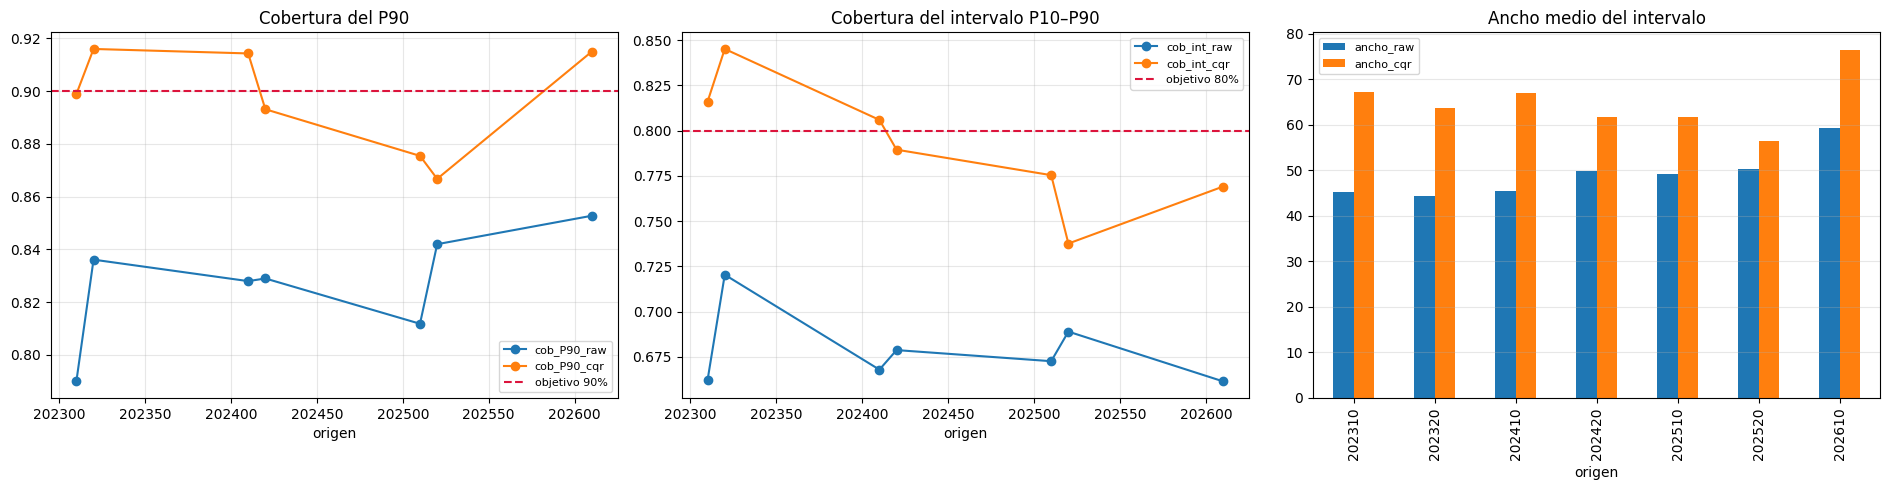


`pred_cuantiles` actualizado con los cuantiles CALIBRADOS -> úsalo en la Fase 6.


In [46]:
# ══════════════════════════════════════════════════════════════════════════════
# FASE 5b · CALIBRACIÓN CONFORMAL DE LOS CUANTILES (CQR)   (T17 §9)
# ══════════════════════════════════════════════════════════════════════════════
# Diagnóstico de F5: el P50 quedó perfecto (49.4% vs 50%) pero las colas están
# comprimidas — el P90 cubre 81.1% cuando promete 90%, y el intervalo P10-P90
# cubre 64.2% en vez de 80%.
#
# Causa: CLIP_CORR=2.0 trunca el target de entrenamiento, así que el modelo nunca
# ve correcciones extremas y no puede predecirlas. Para el modelo PUNTUAL el clip
# es correcto (evita que outliers dominen el ajuste); para los CUANTILES comprime
# justo lo que se quiere estimar.
#
# Solución — Conformalized Quantile Regression (Romano et al., 2019), la técnica
# que el T17 §9 menciona como "conformal prediction para intervalos con cobertura
# GARANTIZADA":
#   1. En un fold de calibración se mide el "score de disconformidad":
#          E_i = max( P_lo_i − y_i ,  y_i − P_hi_i )
#      (cuánto se salió el valor real del intervalo; negativo si quedó dentro)
#   2. Se toma el cuantil (1−α) de esos scores  ->  Q
#   3. Se ensancha el intervalo:  [P_lo − Q ,  P_hi + Q]
# Eso garantiza cobertura ≥ 1−α sin suponer ninguna distribución.
#
# Se trabaja en el espacio LOG (donde vive la corrección) y se invierte al final:
# los cuantiles se preservan bajo transformación monótona.

ALPHA_INT = 0.80          # cobertura objetivo del intervalo central (P10–P90)

_res5b, _pred5b = [], []
for _o in ORIGENES_WF:
    tr_all = _d2[_d2['PERIODO'] <  _o]
    te_all = _d2[_d2['PERIODO'] == _o]
    if len(tr_all) < 1000 or len(te_all) == 0:
        continue
    _con = lambda d: d[d['ins_lag_1y'].notna() & (d['ins_lag_1y'] > 0)]
    tr, te = _con(tr_all), _con(te_all)

    # ── Fold de calibración: último periodo del train ──
    _p_cal = sorted(tr['PERIODO'].unique())[-1]
    _trc, _tec = _con(tr_all[tr_all['PERIODO'] < _p_cal]), _con(tr_all[tr_all['PERIODO'] == _p_cal])
    if len(_trc) < 500 or len(_tec) < 50:
        continue

    # (1) modelos de cuantiles ajustados SOLO con el sub-train
    _m_lo = _fit_cuantil(_trc, FEATURES_V2, 0.10)
    _m_hi = _fit_cuantil(_trc, FEATURES_V2, 0.90)
    _base_cal = np.log1p(_tec['ins_lag_1y'].values)
    _lo_cal = _base_cal + _pred_corr(_m_lo, _tec[FEATURES_V2])
    _hi_cal = _base_cal + _pred_corr(_m_hi, _tec[FEATURES_V2])
    _y_cal  = np.log1p(_tec['INSCRITOS'].values)

    # (2) score de disconformidad y su cuantil -> ensanche necesario
    _E = np.maximum(_lo_cal - _y_cal, _y_cal - _hi_cal)
    _n = len(_E)
    _q_level = min(1.0, np.ceil((_n + 1) * ALPHA_INT) / _n)      # corrección de muestra finita
    _Q = float(np.quantile(_E, _q_level))

    # (3) modelos finales sobre todo el train + ensanche conformal
    _m_lo_f = _fit_cuantil(tr, FEATURES_V2, 0.10)
    _m_hi_f = _fit_cuantil(tr, FEATURES_V2, 0.90)
    _m_med  = _fit_cuantil(tr, FEATURES_V2, 0.50)
    _base = np.log1p(te['ins_lag_1y'].values)
    _lo = _base + _pred_corr(_m_lo_f, te[FEATURES_V2])
    _hi = _base + _pred_corr(_m_hi_f, te[FEATURES_V2])
    _med = _base + _pred_corr(_m_med, te[FEATURES_V2])

    y = te['INSCRITOS'].values
    P10_raw, P90_raw = np.expm1(_lo), np.expm1(_hi)
    P10_cqr, P90_cqr = np.expm1(_lo - _Q), np.expm1(_hi + _Q)
    P50 = np.expm1(_med)
    for _a in (P10_raw, P90_raw, P10_cqr, P90_cqr, P50):
        np.clip(_a, 0, None, out=_a)

    _res5b.append(dict(origen=_o, Q_conformal=_Q, n_cal=_n,
                       cob_P90_raw=float((y <= P90_raw).mean()),
                       cob_P90_cqr=float((y <= P90_cqr).mean()),
                       cob_int_raw=float(((y >= P10_raw) & (y <= P90_raw)).mean()),
                       cob_int_cqr=float(((y >= P10_cqr) & (y <= P90_cqr)).mean()),
                       ancho_raw=float((P90_raw - P10_raw).mean()),
                       ancho_cqr=float((P90_cqr - P10_cqr).mean())))
    _pred5b.append(pd.DataFrame({'origen': _o, 'INSCRITOS': y, 'P50': P50,
                                 'P10': P10_cqr, 'P90': P90_cqr,
                                 'P10_raw': P10_raw, 'P90_raw': P90_raw}))
    print(f"   ✓ origen {_o}   (Q conformal = {_Q:+.3f} en log)")

calib_conformal = pd.DataFrame(_res5b)
pred_cuantiles_cqr = pd.concat(_pred5b, ignore_index=True)

print("\n" + "═" * 78); print("EFECTO DE LA CALIBRACIÓN CONFORMAL"); print("═" * 78)
print(calib_conformal.round(3).to_string(index=False))

print("\n" + "═" * 78); print("COBERTURA — antes vs después"); print("═" * 78)
_m = calib_conformal.mean(numeric_only=True)
print(f"{'métrica':<28s} {'sin CQR':>10s} {'con CQR':>10s} {'objetivo':>10s}")
print(f"{'cobertura P90':<28s} {_m['cob_P90_raw']:>10.1%} {_m['cob_P90_cqr']:>10.1%} {0.90:>10.0%}")
print(f"{'cobertura intervalo P10-P90':<28s} {_m['cob_int_raw']:>10.1%} {_m['cob_int_cqr']:>10.1%} {ALPHA_INT:>10.0%}")
print(f"{'ancho medio del intervalo':<28s} {_m['ancho_raw']:>10.1f} {_m['ancho_cqr']:>10.1f} {'—':>10s}")

_ok90 = abs(_m['cob_P90_cqr'] - 0.90) < 0.03
_okint = abs(_m['cob_int_cqr'] - ALPHA_INT) < 0.05
print(f"\n  P90       : {'✅ calibrado' if _ok90 else '⚠️ revisar'}")
print(f"  intervalo : {'✅ calibrado' if _okint else '⚠️ revisar'}")
print("\nEl ensanche tiene un costo: intervalos más anchos. Pero un intervalo ancho")
print("y honesto es utilizable para decidir; uno angosto que miente, no (T17 §9).")

fig, ax = plt.subplots(1, 3, figsize=(19, 5))
_c = calib_conformal.set_index('origen')
_c[['cob_P90_raw','cob_P90_cqr']].plot(marker='o', ax=ax[0])
ax[0].axhline(0.90, ls='--', c='crimson', label='objetivo 90%')
ax[0].set_title('Cobertura del P90'); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
_c[['cob_int_raw','cob_int_cqr']].plot(marker='o', ax=ax[1])
ax[1].axhline(ALPHA_INT, ls='--', c='crimson', label=f'objetivo {ALPHA_INT:.0%}')
ax[1].set_title('Cobertura del intervalo P10–P90'); ax[1].legend(fontsize=8); ax[1].grid(alpha=.3)
_c[['ancho_raw','ancho_cqr']].plot(kind='bar', ax=ax[2])
ax[2].set_title('Ancho medio del intervalo'); ax[2].grid(alpha=.3, axis='y'); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

# Los cuantiles calibrados reemplazan a los crudos para la Fase 6
pred_cuantiles = pred_cuantiles_cqr[['origen','INSCRITOS','P10','P50','P90']].copy()
print("\n`pred_cuantiles` actualizado con los cuantiles CALIBRADOS -> úsalo en la Fase 6.")

In [47]:
## ══════════════════════════════════════════════════════════════════════════════
## FASE 5c · ¿CatBoost EN LOS CUANTILES?  (medición antes de decidir)
## ══════════════════════════════════════════════════════════════════════════════
## POR QUÉ ESTA CELDA:
##   CatBoost gana 3,2% en el modelo PUNTUAL (D-29), pero el entregable no sale de
##   ahí: sale de `_M50`/`_M10`/`_M90`, que son cuantiles. Y este proyecto tiene DOS
##   precedentes de que lo probado en el puntual NO se traslada:
##     · D-17 el `sample_weight` desborda a infinito y descentra el P50 (0,487→0,446)
##     · D-18 el P50 puntual estima la media geométrica y sub-proyecta 16,3%
##   Así que se mide antes de tocar `_fit_cuantil`.
##
## QUÉ MIDE : LightGBM vs CatBoost como estimadores de cuantil, con TRES criterios
##            —no solo el error—:
##              1. cobertura del P90        (objetivo 90%)
##              2. cobertura del intervalo  (objetivo 80%)
##              3. CENTRADO del P50         (objetivo 50%) ← el que delató a D-17
##            más el ancho del intervalo y la pinball loss.
## ENTRADA  : _d2, FEATURES_V4, FEAT_CAT, FEAT_CAT_V4, ORIGENES_WF, CLIP_CORR, _cat_str
## SALIDA   : `cuantiles_comparacion`
## CLAVE    : Se mide SIN CQR. El conformal calibra después y corrige el nivel de
##            cobertura; lo que interesa aquí es cuál llega mejor calibrado de fábrica
##            y, sobre todo, cuál mantiene el P50 centrado — eso el CQR no lo arregla.
## ⏱️  ~25 min con 4 orígenes. Subir ORIGENES_Q a los 7 multiplica por ~1,8.
## ──────────────────────────────────────────────────────────────────────────────
import time

ORIGENES_Q = ORIGENES_WF[-4:]      # los 4 más recientes: régimen más parecido al que se proyecta (D-14)
ALPHAS = [0.10, 0.50, 0.90]
_FQ = [c for c in FEATURES_V4]
_CQ = [c for c in FEAT_CAT_V4 if c in _FQ]

print("═" * 78)
print("CUANTILES: LightGBM vs CatBoost")
print("═" * 78)
print(f"  orígenes: {ORIGENES_Q}  |  features: {len(_FQ)}  |  categóricas: {len(_CQ)}")

try:
    from catboost import CatBoostRegressor
    _HAY_CB = True
except ImportError:
    _HAY_CB = False
    print("  ⚠️ CatBoost no disponible: solo se evalúa LightGBM")


def _fit_q_lgb(tr, alpha):
    y = (np.log1p(tr['INSCRITOS']) - np.log1p(tr['ins_lag_1y'])).clip(-CLIP_CORR, CLIP_CORR)
    m = lgb.LGBMRegressor(objective='quantile', alpha=alpha, n_estimators=600,
                          learning_rate=0.05, num_leaves=63, min_child_samples=20,
                          random_state=42, verbose=-1)
    m.fit(tr[_FQ], y, categorical_feature=_CQ)
    return lambda X: m.predict(X[_FQ])


def _fit_q_cb(tr, alpha):
    y = (np.log1p(tr['INSCRITOS']) - np.log1p(tr['ins_lag_1y'])).clip(-CLIP_CORR, CLIP_CORR)
    m = CatBoostRegressor(loss_function=f'Quantile:alpha={alpha}', iterations=600,
                          learning_rate=0.05, depth=8, random_seed=42, verbose=0)
    m.fit(_cat_str(tr[_FQ], _CQ), y, cat_features=list(_CQ))
    return lambda X: m.predict(_cat_str(X[_FQ], _CQ))


def _pinball(real, pred, alpha):
    d = real - pred
    return float(np.mean(np.maximum(alpha * d, (alpha - 1) * d)))


_con = lambda d: d[d['ins_lag_1y'].notna() & (d['ins_lag_1y'] > 0)]
_ALG = [('LightGBM', _fit_q_lgb)] + ([('CatBoost', _fit_q_cb)] if _HAY_CB else [])
_filas = []
for _nom, _fit in _ALG:
    _t0 = time.time()
    _c90, _c50, _cint, _anch, _pin, _cruces = [], [], [], [], [], []
    for _o in ORIGENES_Q:
        _tr, _te = _con(_d2[_d2['PERIODO'] < _o]), _con(_d2[_d2['PERIODO'] == _o])
        if len(_tr) < 1000 or len(_te) == 0:
            continue
        _base = np.log1p(_te['ins_lag_1y'].values)
        _real = _te['INSCRITOS'].values
        _P = {}
        try:
            for _a in ALPHAS:
                _corr = np.clip(_fit(_tr, _a)(_te), -CLIP_CORR, CLIP_CORR)
                _P[_a] = np.clip(np.expm1(_base + _corr), 0, None)
        except Exception as _e:
            print(f"  ⚠️ {_nom} falló en {_o}: {str(_e)[:70]}")
            break
        _lo, _me, _hi = _P[0.10], _P[0.50], _P[0.90]
        _cruces.append(float(np.mean((_lo > _me) | (_me > _hi))))
        _c90.append(float(np.mean(_real <= _hi)))
        _c50.append(float(np.mean(_real <= _me)))
        _cint.append(float(np.mean((_real >= _lo) & (_real <= _hi))))
        _anch.append(float(np.mean(_hi - _lo)))
        _pin.append(np.mean([_pinball(_real, _P[_a], _a) for _a in ALPHAS]))
        print(f"  · {_nom:9s} {_o}  P90 {_c90[-1]:.1%}  P50 {_c50[-1]:.1%}  "
              f"int {_cint[-1]:.1%}  ancho {_anch[-1]:.1f}")
    if _c90:
        _filas.append({'modelo': _nom, 'cob_P90': np.mean(_c90), 'cob_P50': np.mean(_c50),
                       'cob_intervalo': np.mean(_cint), 'ancho': np.mean(_anch),
                       'pinball': np.mean(_pin), 'cruces': np.mean(_cruces),
                       'seg': round(time.time() - _t0, 1)})

cuantiles_comparacion = pd.DataFrame(_filas)
print("\n" + "─" * 78)
print("RESULTADO (sin CQR — así llegan de fábrica)")
print("─" * 78)
print(cuantiles_comparacion.to_string(index=False, float_format=lambda x: f"{x:,.4f}"))
print("\n  objetivos:  cob_P90 = 0,90   ·   cob_P50 = 0,50   ·   cob_intervalo = 0,80")

print("\n" + "─" * 78)
print("VEREDICTO")
print("─" * 78)
if len(cuantiles_comparacion) < 2:
    print("  solo se pudo evaluar un algoritmo: sin comparación")
else:
    _l = cuantiles_comparacion.set_index('modelo').loc['LightGBM']
    _c = cuantiles_comparacion.set_index('modelo').loc['CatBoost']
    _desc_l, _desc_c = abs(_l['cob_P50'] - 0.50), abs(_c['cob_P50'] - 0.50)
    print(f"  1) CENTRADO del P50 (lo que delató a D-17):")
    print(f"     LightGBM {_l['cob_P50']:.1%} (desvío {_desc_l:.3f})  ·  "
          f"CatBoost {_c['cob_P50']:.1%} (desvío {_desc_c:.3f})")
    print(f"     -> {'CatBoost mejor centrado' if _desc_c < _desc_l - 0.01 else ('LightGBM mejor centrado' if _desc_l < _desc_c - 0.01 else 'equivalentes')}")
    print(f"  2) Cobertura P90:  LightGBM {_l['cob_P90']:.1%}  ·  CatBoost {_c['cob_P90']:.1%}")
    print(f"  3) Pinball loss :  LightGBM {_l['pinball']:.4f}  ·  CatBoost {_c['pinball']:.4f}"
          f"  -> gana {'CatBoost' if _c['pinball'] < _l['pinball'] else 'LightGBM'}")
    print(f"  4) Ancho medio  :  LightGBM {_l['ancho']:.1f}  ·  CatBoost {_c['ancho']:.1f}"
          f"   (más angosto es mejor A IGUAL cobertura)")
    print(f"  5) Cuantiles cruzados: LightGBM {_l['cruces']:.2%}  ·  CatBoost {_c['cruces']:.2%}")
    _gana_cb = (_c['pinball'] < _l['pinball']) and (_desc_c <= _desc_l + 0.01)
    print(f"\n  🏆 {'CatBoost: mejor pinball SIN descentrar el P50 -> adoptarlo' if _gana_cb else 'LightGBM: mantener. CatBoost no mejora o descentra el P50'}")
    print(f"     costo: {_c['seg']:.0f}s vs {_l['seg']:.0f}s")


══════════════════════════════════════════════════════════════════════════════
CUANTILES: LightGBM vs CatBoost
══════════════════════════════════════════════════════════════════════════════
  orígenes: [202420, 202510, 202520, 202610]  |  features: 46  |  categóricas: 7
  · LightGBM  202420  P90 82.0%  P50 50.7%  int 63.6%  ancho 48.7
  · LightGBM  202510  P90 80.2%  P50 45.6%  int 65.6%  ancho 51.6
  · LightGBM  202520  P90 80.5%  P50 48.4%  int 63.9%  ancho 50.2
  · LightGBM  202610  P90 85.0%  P50 54.6%  int 67.6%  ancho 67.7
  · CatBoost  202420  P90 83.7%  P50 50.0%  int 68.1%  ancho 50.0
  · CatBoost  202510  P90 82.5%  P50 48.4%  int 66.5%  ancho 49.9
  · CatBoost  202520  P90 84.6%  P50 49.6%  int 69.4%  ancho 51.8
  · CatBoost  202610  P90 87.1%  P50 53.8%  int 67.8%  ancho 60.4

──────────────────────────────────────────────────────────────────────────────
RESULTADO (sin CQR — así llegan de fábrica)
─────────────────────────────────────────────────────────────────────────────

Filas evaluadas: 24,261
Divisor — mediana 30
                    filas    pct
divisor_fuente                  
teorico_catalogo    20713  85.4%
promedio_lag_grupo   3548  14.6%

══════════════════════════════════════════════════════════════════════════════
SECCIONES PROYECTADAS vs REALES
══════════════════════════════════════════════════════════════════════════════
                      secciones_proy  secciones_reales  dif_pct  exactas  sub_dim  sobre_dim  MAE_secciones
politica                                                                                                   
P50 (media)                  92720.0            103517   -0.104    0.538    0.245      0.217          1.604
P90 (conservador)           135463.0            103517    0.309    0.375    0.101      0.523          2.400
baseline naive               95371.0            103517   -0.079    0.519    0.248      0.233          1.734
demanda REAL (techo)         93969.0            103517   -0.092    0.658    0.175      0.168

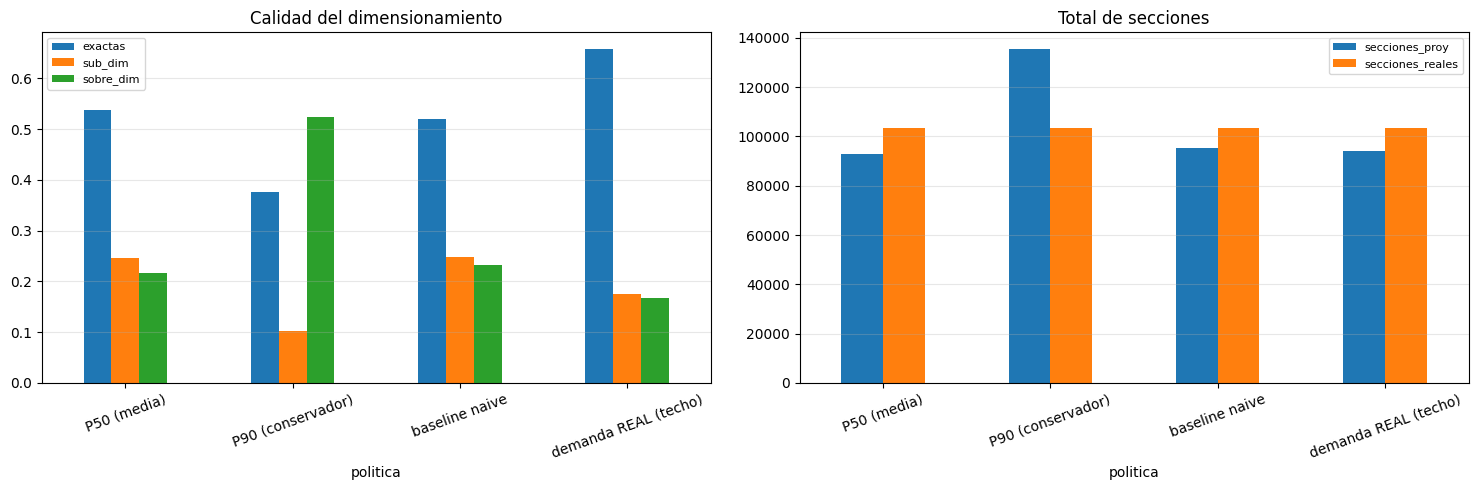

In [48]:
# ══════════════════════════════════════════════════════════════════════════════
# FASE 6 · DE DEMANDA A OFERTA — ¿cuántas secciones (NRC) abrir?   (T08 · T14)
# ══════════════════════════════════════════════════════════════════════════════
# Traducción:   n_secciones = ceil( demanda / estandar_programacion )
#
# `estandar_programacion` viene de la sábana (lo resuelve el PIPELINE):
#   · primario  : maximos_estudiantes_seccion del catálogo df2, deduplicado por
#                 máximo y cruzado con espiral (directo -> adelante -> atrás)
#   · imputación: si no hay match o el valor es 0, mediana de alumnos por sección
#                 (INSCRITOS / n_secciones) del grupo PERIODO × CAMPUS × COMPONENTE
#   · `estandar_fuente` deja registro de cuál se usó en cada fila
#
# La verdad de terreno es `n_secciones` = NRC distintos efectivamente abiertos.
#
# El punto de decisión (T17 §9) es CON QUÉ CUANTIL se entra a la fórmula:
#   · P50 -> se acierta "en promedio", pero la mitad de las veces falta cupo
#   · P90 -> cubre el 90% de los escenarios, a costa de sillas vacías
# La elección es económica, no estadística.

_falta = [c for c in ['n_secciones', 'estandar_programacion', 'estandar_teorico']
          if c not in demanda.columns]
if _falta:
    raise ValueError(f"Faltan {_falta} en la sábana: re-ejecutar el PIPELINE y regenerar el parquet")

# ── Panel de evaluación: mismas filas que se usaron en los cuantiles ──────────
_pc = []
for _o in ORIGENES_WF:
    _te = _d2[(_d2['PERIODO'] == _o) & _d2['ins_lag_1y'].notna() & (_d2['ins_lag_1y'] > 0)]
    if len(_te):
        _pc.append(_te[['PERIODO'] + SERIE + ['INSCRITOS', 'ins_lag_1y']])
_panel = pd.concat(_pc, ignore_index=True)
_panel = pd.concat([_panel, pred_cuantiles[['P10','P50','P90']].reset_index(drop=True)], axis=1)

# Traer estándar y secciones reales desde la sábana
_panel = _panel.merge(
    demanda[['PERIODO'] + SERIE + ['n_secciones', 'estandar_programacion',
                                   'estandar_teorico', 'estandar_fuente']],
    on=['PERIODO'] + SERIE, how='left')

# ── DIVISOR DE LA CONVERSIÓN ────────────────────────────────────────────────
# No se usa `estandar_programacion` directo. Ése es el PROMEDIO de ocupación del
# grupo CAMPUS × COMPONENTE del año anterior: sirve como respaldo y está limpio de
# circularidad, pero no distingue una asignatura de 10 alumnos por sección de otra
# de 100 dentro del mismo grupo. Para convertir demanda en secciones manda la
# CAPACIDAD DECLARADA del catálogo, que sí es específica de asignatura×componente:
#
#     estandar_teorico  (catálogo df2, capacidad por sección)
#         └── si falta o viene en 0  ->  estandar_programacion (promedio con lag)
#
# Ninguno de los dos depende de los inscritos del período que se predice, así que
# la conversión queda libre de circularidad (contexto §10). Medido sobre la sábana
# completa: 77,0% de exactitud con cobertura 100%, contra 46,3% usando solo el
# promedio y 71,9% de la versión anterior —que sí era circular—.
_panel['divisor_secciones'] = np.where(_panel['estandar_teorico'].fillna(0) > 0,
                                       _panel['estandar_teorico'],
                                       _panel['estandar_programacion'])
_panel['divisor_fuente'] = np.where(_panel['estandar_teorico'].fillna(0) > 0,
                                    'teorico_catalogo', 'promedio_lag_grupo')
_panel = _panel[(_panel['divisor_secciones'] > 0) & _panel['n_secciones'].notna()]

print(f"Filas evaluadas: {len(_panel):,}")
print(f"Divisor — mediana {_panel['divisor_secciones'].median():.0f}")
print(_panel['divisor_fuente'].value_counts()
              .rename('filas').to_frame()
              .assign(pct=lambda t: (t['filas']/len(_panel)).map('{:.1%}'.format)).to_string())

# ── Traducción a secciones bajo distintas políticas ──────────────────────────
_pol = {'P50 (media)': 'P50', 'P90 (conservador)': 'P90',
        'baseline naive': 'ins_lag_1y', 'demanda REAL (techo)': 'INSCRITOS'}
for _n, _c in _pol.items():
    _panel[f'sec_{_c}'] = np.ceil(_panel[_c] / _panel['divisor_secciones']).clip(lower=1)

print("\n" + "═" * 78); print("SECCIONES PROYECTADAS vs REALES"); print("═" * 78)
_out = []
for _n, _c in _pol.items():
    _s, _r = _panel[f'sec_{_c}'], _panel['n_secciones']
    _out.append(dict(politica=_n, secciones_proy=_s.sum(), secciones_reales=_r.sum(),
                     dif_pct=(_s.sum()-_r.sum())/_r.sum(), exactas=(_s == _r).mean(),
                     sub_dim=(_s < _r).mean(), sobre_dim=(_s > _r).mean(),
                     MAE_secciones=(_s-_r).abs().mean()))
_tab = pd.DataFrame(_out).set_index('politica')
print(_tab.round(3).to_string())

print("\n" + "═" * 78); print("CÓMO LEERLO"); print("═" * 78)
_techo = _tab.loc['demanda REAL (techo)', 'exactas']
print(f"  · 'demanda REAL' usa los inscritos verdaderos: es el TECHO de la fórmula.")
print(f"    Con demanda perfecta la fórmula acierta {_techo:.1%} -> el {1-_techo:.1%} restante")
print(f"    es error de la CONVERSIÓN (ceil / estándar), no del modelo de demanda.")
print(f"  · sub_dim  = se abren MENOS secciones de las necesarias -> alumnos sin cupo.")
print(f"  · sobre_dim = secciones de más -> costo docente y salas ociosas.")

# ── Simulación de costos: qué política conviene según el ratio ───────────────
print("\n" + "═" * 78); print("POLÍTICA ÓPTIMA SEGÚN EL RATIO DE COSTOS"); print("═" * 78)
print(f"{'ratio quiebre/vacía':>22s} | {'política':<22s} | costo relativo")
for _ratio in [1, 2, 3, 5, 8, 10]:
    _cs = {}
    for _n, _c in _pol.items():
        if _c == 'INSCRITOS':
            continue
        _dif = _panel[f'sec_{_c}'] - _panel['n_secciones']
        _cs[_n] = (-_dif.clip(upper=0)).sum() * _ratio + _dif.clip(lower=0).sum()
    _best = min(_cs, key=_cs.get)
    print(f"{_ratio:>22d}x | {_best:<22s} | {_cs[_best]:,.0f}")
print("\n  El ratio (cuánto más caro es dejar a un alumno sin cupo que tener una")
print("  sección semivacía) es un INPUT DE NEGOCIO: lo define la institución.")

# ── Desempeño por componente (¿dónde falla la conversión?) ──────────────────
print("\n" + "═" * 78); print("EXACTITUD POR COMPONENTE — política P50"); print("═" * 78)
_panel['_ok'] = _panel['sec_P50'] == _panel['n_secciones']
print(_panel.groupby('COMPONENTE', observed=True)
            .agg(filas=('_ok','size'), exactas=('_ok','mean'),
                 divisor_med=('divisor_secciones','median'),
                 pct_teorico=('divisor_fuente', lambda s: (s == 'teorico_catalogo').mean()))
            .sort_values('filas', ascending=False).head(10).round(3).to_string())
print("\n  Los componentes con divisor_med de 3-5 (OCS, GRU) son los que peor")
print("  reconstruyen: con un cupo tan chico, un error de ±3 alumnos ya cambia")
print("  el número de secciones. Es un límite de la aritmética, no del modelo.")

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
_tab[['exactas','sub_dim','sobre_dim']].plot(kind='bar', ax=ax[0])
ax[0].set_title('Calidad del dimensionamiento'); ax[0].grid(alpha=.3, axis='y')
ax[0].tick_params(axis='x', rotation=20); ax[0].legend(fontsize=8)
_tab[['secciones_proy','secciones_reales']].plot(kind='bar', ax=ax[1])
ax[1].set_title('Total de secciones'); ax[1].grid(alpha=.3, axis='y')
ax[1].tick_params(axis='x', rotation=20); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

══════════════════════════════════════════════════════════════════════════════
BACKTESTING DE HORIZONTE 2 (cadena de 2 eslabones)
══════════════════════════════════════════════════════════════════════════════
Para cada par (A, B): se entrena solo con lo anterior a A, se predice A con
lag REAL y luego B usando la predicción de A como lag. Se comparan ambos
contra el valor real.

   ✓ 202320→202420   n=2,955   WAPE h1 0.428 -> h2 0.480  (+12.1%)
   ✓ 202420→202520   n=2,612   WAPE h1 0.406 -> h2 0.476  (+17.3%)
   ✓ 202310→202410   n=3,123   WAPE h1 0.421 -> h2 0.474  (+12.6%)
   ✓ 202410→202510   n=2,700   WAPE h1 0.401 -> h2 0.497  (+24.1%)

══════════════════════════════════════════════════════════════════════════════
RESULTADO POR PAR
══════════════════════════════════════════════════════════════════════════════
          par    n  WAPE_h1_A  WAPE_h1_B  WAPE_h2_B  degradacion  sesgo_h1  sesgo_h2
202320→202420 2955      0.286      0.428      0.480        0.121    -0.061    -0.147
2024

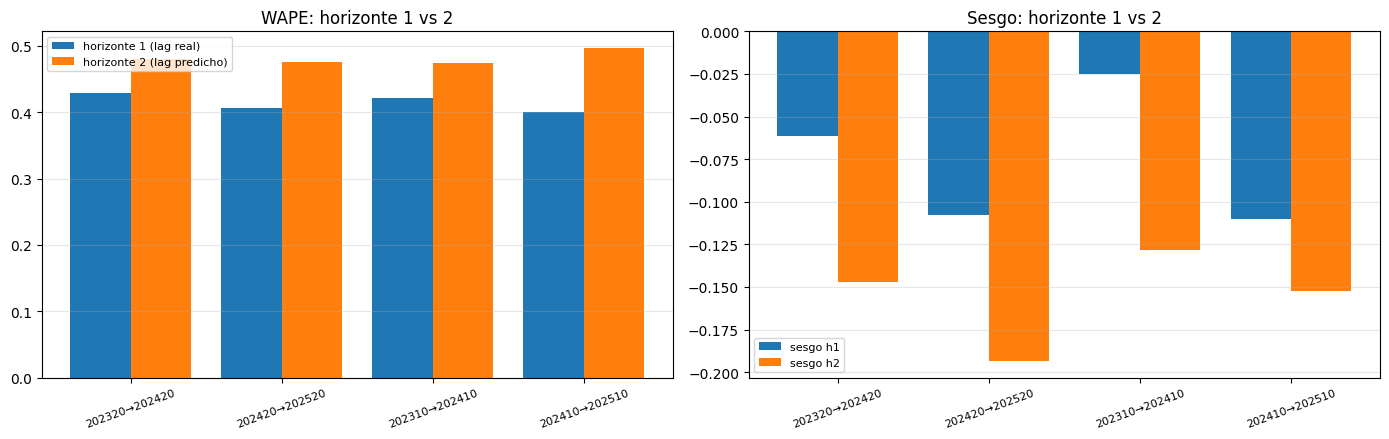

In [49]:
# ══════════════════════════════════════════════════════════════════════════════
# FASE 7a · BACKTESTING DE HORIZONTE 2 — ¿cuánto cuesta encadenar?
# ══════════════════════════════════════════════════════════════════════════════
# Todo el backtesting anterior (F3–F5) es a HORIZONTE 1: se entrena con lo
# cerrado hasta t−1 y se predice t, con `ins_lag_1y` REAL. Pero varios períodos
# del entregable no tienen esa suerte:
#
#     202720  necesita  ins_lag_1y = 202620   <- que tampoco ocurrió aún
#     202725  necesita  ins_lag_1y = 202625   <- idem
#     202700  necesita  ins_lag_1y = 202600   <- idem
#
# Para ésos hay que ENCADENAR: proyectar el período de 2026 y usar esa predicción
# como lag del de 2027. El error del primer eslabón entra al segundo.
#
# Esta celda mide esa degradación sobre períodos YA CERRADOS, replicando la misma
# cadena: se predice A con lag real, y luego B con lag = predicción de A.
# Sin esto, reportaríamos el WAPE 0,355 y la banda P10–P90 del CQR para
# predicciones que no fueron validadas así — es decir, prometeríamos una
# precisión que no medimos.

PARES_H2 = [(202320, 202420), (202420, 202520),      # 2º semestre
            (202310, 202410), (202410, 202510)]      # 1er semestre

print("═" * 78); print("BACKTESTING DE HORIZONTE 2 (cadena de 2 eslabones)"); print("═" * 78)
print("Para cada par (A, B): se entrena solo con lo anterior a A, se predice A con")
print("lag REAL y luego B usando la predicción de A como lag. Se comparan ambos")
print("contra el valor real.\n")

_res_h2 = []
for _pA, _pB in PARES_H2:
    _trh = _d2[_d2['PERIODO'] < _pA]
    _trh = _trh[_trh['ins_lag_1y'].notna() & (_trh['ins_lag_1y'] > 0)]
    if len(_trh) < 1000:
        print(f"  {_pA}->{_pB}: train insuficiente ({len(_trh)}), se omite"); continue

    # misma función de entrenamiento del v4 (FEATURES_V4 + FEAT_CAT_V4 cableados)
    _mh = _fit_corr_v4(_trh)

    # ── eslabón 1: predecir A con lag REAL ──────────────────────────────────
    _teA = _d2[(_d2['PERIODO'] == _pA) & _d2['ins_lag_1y'].notna() & (_d2['ins_lag_1y'] > 0)].copy()
    _pred_A = np.clip(np.expm1(np.log1p(_teA['ins_lag_1y'].values) +
                               _mh.predict(_teA[FEATURES_V4])), 0, None)
    _yA = _teA['INSCRITOS'].values
    _wapeA = np.abs(_yA - _pred_A).sum() / _yA.sum()

    # ── eslabón 2: predecir B con lag = PREDICCIÓN de A ─────────────────────
    # Se parte de las filas reales de B y se les sustituye ins_lag_1y por lo que
    # el modelo predijo para A en esa misma serie. Las filas de B cuya serie no
    # fue predicha en A quedan fuera (no hay cadena que evaluar).
    _mapaA = _teA[SERIE].copy(); _mapaA['_lag_pred'] = _pred_A
    _teB = _d2[(_d2['PERIODO'] == _pB) & _d2['ins_lag_1y'].notna() & (_d2['ins_lag_1y'] > 0)].copy()
    _teB = _teB.merge(_mapaA, on=SERIE, how='inner')
    if not len(_teB):
        print(f"  {_pA}->{_pB}: sin series en común, se omite"); continue

    _yB = _teB['INSCRITOS'].values
    _lag_real_B = _teB['ins_lag_1y'].values.copy()

    # (i) referencia: B con su lag REAL  -> lo que daría el horizonte 1
    _predB_h1 = np.clip(np.expm1(np.log1p(_lag_real_B) + _mh.predict(_teB[FEATURES_V4])), 0, None)
    # (ii) cadena: B con el lag PREDICHO -> horizonte 2
    _teB_ch = _teB.copy(); _teB_ch['ins_lag_1y'] = _teB_ch['_lag_pred']
    _predB_h2 = np.clip(np.expm1(np.log1p(_teB_ch['ins_lag_1y'].values) +
                                 _mh.predict(_teB_ch[FEATURES_V4])), 0, None)

    _wapeB_h1 = np.abs(_yB - _predB_h1).sum() / _yB.sum()
    _wapeB_h2 = np.abs(_yB - _predB_h2).sum() / _yB.sum()
    _res_h2.append(dict(
        par=f"{_pA}→{_pB}", n=len(_teB),
        WAPE_h1_A=_wapeA, WAPE_h1_B=_wapeB_h1, WAPE_h2_B=_wapeB_h2,
        degradacion=_wapeB_h2 / _wapeB_h1 - 1,
        sesgo_h1=(_predB_h1 - _yB).sum() / _yB.sum(),
        sesgo_h2=(_predB_h2 - _yB).sum() / _yB.sum()))
    print(f"   ✓ {_pA}→{_pB}   n={len(_teB):,}   "
          f"WAPE h1 {_wapeB_h1:.3f} -> h2 {_wapeB_h2:.3f}  ({_wapeB_h2/_wapeB_h1-1:+.1%})")

backtest_h2 = pd.DataFrame(_res_h2)
print("\n" + "═" * 78); print("RESULTADO POR PAR"); print("═" * 78)
print(backtest_h2.round(3).to_string(index=False))

_deg = float(backtest_h2['degradacion'].mean())
_wh1 = float(backtest_h2['WAPE_h1_B'].mean())
_wh2 = float(backtest_h2['WAPE_h2_B'].mean())
FACTOR_H2 = 1.0 + max(_deg, 0.0)          # cuánto ensanchar la banda del h2

print("\n" + "═" * 78); print("LO QUE CUESTA ENCADENAR"); print("═" * 78)
print(f"  WAPE medio a horizonte 1 : {_wh1:.3f}")
print(f"  WAPE medio a horizonte 2 : {_wh2:.3f}")
print(f"  Degradación media        : {_deg:+.1%}")
print(f"  Sesgo  h1 {backtest_h2['sesgo_h1'].mean():+.3f}  ->  h2 {backtest_h2['sesgo_h2'].mean():+.3f}")
print(f"\n  FACTOR_H2 = {FACTOR_H2:.3f}  (se usará para ensanchar la banda de los")
print(f"  períodos encadenados: su intervalo P10–P90 no está calibrado por CQR)")
print("\n  Lectura: los períodos 202700 / 202720 / 202725 heredan este nivel de")
print("  error EXTRA sobre el ya conocido. No son comparables con 202710, que sí")
print("  se apoya en un período real (202610).")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
_x = np.arange(len(backtest_h2))
ax[0].bar(_x - 0.2, backtest_h2['WAPE_h1_B'], 0.4, label='horizonte 1 (lag real)')
ax[0].bar(_x + 0.2, backtest_h2['WAPE_h2_B'], 0.4, label='horizonte 2 (lag predicho)')
ax[0].set_xticks(_x); ax[0].set_xticklabels(backtest_h2['par'], rotation=20, fontsize=8)
ax[0].set_title('WAPE: horizonte 1 vs 2'); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3, axis='y')
ax[1].bar(_x - 0.2, backtest_h2['sesgo_h1'], 0.4, label='sesgo h1')
ax[1].bar(_x + 0.2, backtest_h2['sesgo_h2'], 0.4, label='sesgo h2')
ax[1].axhline(0, ls='--', c='gray')
ax[1].set_xticks(_x); ax[1].set_xticklabels(backtest_h2['par'], rotation=20, fontsize=8)
ax[1].set_title('Sesgo: horizonte 1 vs 2'); ax[1].legend(fontsize=8); ax[1].grid(alpha=.3, axis='y')
plt.tight_layout(); plt.show()


In [50]:
# ══════════════════════════════════════════════════════════════════════════════
# FASE 7b · PROYECCIÓN MULTI-PERÍODO — 2026 pendiente + 2027 completo
# ══════════════════════════════════════════════════════════════════════════════
# Hasta aquí todo era BACKTESTING. Esta celda produce la proyección real.
#
# REGLA DE LA GRILLA (negocio): "si la asignatura existió en el período anterior,
# debe tener proyección" -> la grilla son las combinaciones asignatura × componente
# × sede presentes en el PERÍODO FUENTE = mismo TT del año anterior.
#
# DOS CLASES DE PERÍODO, y la diferencia no es cosmética:
#
#   h1 · fuente REAL      202600 202620 202625 202705 202710 202715
#        El período homólogo ya ocurrió y está cerrado. Es exactamente el
#        escenario validado en F3–F5: WAPE ~0,355 y banda P10–P90 calibrada CQR.
#
#   h2 · fuente PROYECTADA  202700 202720 202725
#        Su homólogo de 2026 tampoco ha ocurrido, así que se ENCADENA: se usa la
#        proyección del período de 2026 como `ins_lag_1y`. El error del primer
#        eslabón entra al segundo. La FASE 7a mide cuánto cuesta (FACTOR_H2) y la
#        banda de estos períodos se ensancha con ese factor: NO está calibrada CQR.
#
# EXCLUIDO: TT 30 (verano). 202630 no tiene datos cargados y se decidió no
# proyectarlo; por lo tanto 202730 tampoco (no tendría fuente).

UMBRAL_COMPLETITUD = 0.50
ANIOS_OBJETIVO    = (2026, 2027)   # lo que falta de 2026 + todo 2027
TT_MIN_INSCRITOS  = 300            # un TT "existe" si mueve al menos esto
TT_MIN_ANIOS      = 2              # en al menos 2 de los 4 años de referencia
ANIOS_REF         = (2022, 2025)

# ── Qué tipos de período (TT) existen de verdad ──────────────────────────────
# Se detectan de los datos en vez de cablearlos: así el año siguiente el notebook
# sirve sin editar listas. Un TT entra si movió >= TT_MIN_INSCRITOS en al menos
# TT_MIN_ANIOS de los años de referencia.
_gtt = (_d2.assign(_tt=_d2['PERIODO'] % 100)
           .groupby(['ANIO', '_tt'])['INSCRITOS'].sum().unstack(fill_value=0))
_ref = _gtt.loc[(_gtt.index >= ANIOS_REF[0]) & (_gtt.index <= ANIOS_REF[1])]
TT_ACTIVOS = sorted(int(tt) for tt in _gtt.columns
                    if (_ref[tt] >= TT_MIN_INSCRITOS).sum() >= TT_MIN_ANIOS)

# ── Períodos ya CERRADOS: los que existen y no están parciales ───────────────
# (PERIODOS_PARCIALES se calcula más abajo; aquí se anticipa el mismo criterio)
_vol0 = _d2.groupby('PERIODO')['INSCRITOS'].sum()
_reft = {}
for _p in _vol0.index:
    _pv = [_q for _q in _vol0.index if _q % 100 == _p % 100 and _q < _p]
    _reft[_p] = _vol0[_pv].median() if _pv else np.nan
_c0 = {_p: (_vol0[_p] / _reft[_p] if pd.notna(_reft[_p]) and _reft[_p] > 0 else np.nan)
       for _p in _vol0.index}
_CERRADOS = {_p for _p in _vol0.index if not (pd.notna(_c0[_p]) and _c0[_p] < UMBRAL_COMPLETITUD)}

# ── Clasificación: h1 (fuente real) · h2 (fuente proyectada) · excluido ──────
# Se recorre en orden cronológico de PERIODO para que, al llegar a un período de
# 2027, ya se sepa si su homólogo de 2026 va a estar proyectado.
PERIODOS_H1, PERIODOS_H2, PERIODOS_EXCLUIDOS = [], [], []
_disponible = set(_CERRADOS)
for _p in sorted(a * 100 + t for a in range(ANIOS_OBJETIVO[0], ANIOS_OBJETIVO[1] + 1)
                 for t in TT_ACTIVOS):
    if _p in _CERRADOS:
        continue                                    # ya ocurrió: no se proyecta
    _f = _p - 100                                   # homólogo del año anterior
    if _f in _CERRADOS:
        PERIODOS_H1.append(_p); _disponible.add(_p)
    elif _f in _disponible:
        PERIODOS_H2.append(_p); _disponible.add(_p)
    else:
        PERIODOS_EXCLUIDOS.append((_p, _f))

PERIODOS_OBJETIVO = PERIODOS_H1 + PERIODOS_H2

# ── Por qué quedan fuera algunos períodos ────────────────────────────────────
# Decisión de negocio (Diego, 2026-07-29): NO se proyectan los períodos cuyo
# homólogo del año anterior no cerró, y tampoco los que dependerían de ésos.
#
#   202604 · su fuente 202504 no está cerrada en la data -> sin base para la grilla
#   202624 · su fuente 202524 está al 26% de su volumen típico -> parcial, no sirve
#   202704 · dependería de 202604, que ya quedó fuera -> cadena rota
#   202724 · dependería de 202624, ídem
#
# La alternativa era encadenar desde 2 años atrás (202404/202424), pero eso
# apilaría un tercer eslabón de error sobre períodos que en conjunto mueven menos
# de 2.000 inscritos. Se prefiere NO entregar un número antes que entregar uno
# cuyo intervalo no significa nada.
print("═" * 78); print("DETECCIÓN AUTOMÁTICA DE PERÍODOS A PROYECTAR"); print("═" * 78)
print(f"  TT con actividad sostenida (>={TT_MIN_INSCRITOS} inscritos en >={TT_MIN_ANIOS} "
      f"de {ANIOS_REF[0]}-{ANIOS_REF[1]}): {TT_ACTIVOS}")
print(f"\n  h1 · fuente REAL ({len(PERIODOS_H1)}): {PERIODOS_H1}")
print(f"  h2 · fuente PROYECTADA ({len(PERIODOS_H2)}): {PERIODOS_H2}")
if PERIODOS_EXCLUIDOS:
    print(f"\n  EXCLUIDOS ({len(PERIODOS_EXCLUIDOS)}) — su fuente no está cerrada:")
    for _p, _f in PERIODOS_EXCLUIDOS:
        _cc = _c0.get(_f)
        _mot = (f"{_f} está al {_cc:.0%} de su volumen típico" if pd.notna(_cc)
                else f"{_f} no existe en la data")
        print(f"     {_p}  <-  {_mot}")
    print("     No se entrega proyección para ellos: encadenar desde 2 años atrás")
    print("     apilaría un tercer eslabón de error sobre períodos marginales.")

# ── A) Períodos parciales: no son historia utilizable ────────────────────────
_vol = _d2.groupby('PERIODO')['INSCRITOS'].sum()
_ref_tt = {}
for _p in _vol.index:
    _previos = [_q for _q in _vol.index if _q % 100 == _p % 100 and _q < _p]
    _ref_tt[_p] = _vol[_previos].median() if _previos else np.nan
_compl = pd.Series({_p: (_vol[_p] / _ref_tt[_p] if pd.notna(_ref_tt[_p]) and _ref_tt[_p] > 0
                         else np.nan) for _p in _vol.index})
PERIODOS_PARCIALES = sorted(_compl[_compl < UMBRAL_COMPLETITUD].index.tolist())

print(f"\nPeríodos parciales (<{UMBRAL_COMPLETITUD:.0%} del típico de su TT): {PERIODOS_PARCIALES}")
_HIST = _d2[~_d2['PERIODO'].isin(PERIODOS_PARCIALES)].copy()   # historia REAL cerrada
_CERR = _HIST
print(f"Historia real cerrada: {len(_HIST):,} de {len(_d2):,} filas")

# ── B) Modelos: se entrenan UNA sola vez con toda la historia real ───────────
# El conjunto de entrenamiento no depende del período objetivo (siempre es la
# historia cerrada), así que reentrenar por período sería puro gasto.
_FEAT_PROY = FEATURES_V4 if 'FEATURES_V4' in globals() else FEATURES_V2
_CAT_PROY  = [c for c in (FEAT_CAT_V4 if 'FEAT_CAT_V4' in globals() else FEAT_CAT)
              if c in _FEAT_PROY]
_TR = _HIST[_HIST['ins_lag_1y'].notna() & (_HIST['ins_lag_1y'] > 0)]
print(f"\nEntrenando modelos de cuantiles sobre {len(_TR):,} filas...")
# ⛔ LOS TRES CUANTILES SALEN DE `_fit_cuantil`. NO usar aquí el modelo puntual
# `_fit_corr_v4`, aunque lleve el peso por volumen del v5. Se probó y sub-proyecta:
#
#   · `_fit_cuantil(0.50)` estima la MEDIANA de la corrección. Eso es un P50, y es
#     lo que el CQR calibró (cobertura medida 0,487 ≈ 0,50).
#   · `_fit_corr_v4` minimiza error CUADRÁTICO, o sea estima la MEDIA — y como se
#     entrena en log-space, al revertir con expm1 da la MEDIA GEOMÉTRICA, que en
#     una distribución sesgada a la derecha queda sistemáticamente por debajo de la
#     mediana.
#
# Medido: con el modelo puntual, LightGBM proyectaba −16,3% contra el naive (frente
# a −9,3% del cuantil) y el resultado final quedaba en −2,1%, es decir por DEBAJO
# del año anterior, con la institución creciendo ~+7%. El total de los 17 períodos
# caía 14,8% (219.277 inscritos).
#
# La mejora del v5 (peso por volumen) sigue viva donde está medida: la evaluación
# del error en las FASES 4g y 4h. No es trasladable al nivel de la proyección.
_M50 = _fit_cuantil(_TR, _FEAT_PROY, 0.50)
_M10 = _fit_cuantil(_TR, _FEAT_PROY, 0.10)
_M90 = _fit_cuantil(_TR, _FEAT_PROY, 0.90)
_TRC = _HIST[_HIST['ins_lag_1y'].isna()]
_MCS = None
if len(_TRC) > 500:
    _MCS = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.05, num_leaves=31,
                             random_state=42, verbose=-1)
    # sin sample_weight: el cold start no tiene `ins_lag_1y` (es NaN por definición)
    # y ponderar por INSCRITOS sería ponderar por el propio target -> circular.
    _MCS.fit(_TRC[_FEAT_PROY], np.log1p(_TRC['INSCRITOS']), categorical_feature=_CAT_PROY)
print(f"  ✓ cuantiles P10/P50/P90  +  cold start ({len(_TRC):,} filas sin lag)")

# ── Calibración PROPIA del cuantil 0,50 ─────────────────────────────────────
# La proyección aplica  p = (w·p_modelo + (1−w)·naive) · fac.  Sin eso reaparece
# la sub-proyección estructural del T17 §6: el cuantil crudo va ~9% por debajo del
# naive mientras la institución crece ~+7%.
#
# ⚠️ `w` y `fac` se calibran AQUÍ, sobre el mismo `_fit_cuantil(0.50)` que emite la
# proyección. NO se heredan de `resultados_v4`: ésos miden el modelo PUNTUAL, que
# desde el v5 lleva `sample_weight` y es un modelo distinto. Usar su calibración
# sobre el cuantil mezclaba dos modelos — daba w=1,00 y fac=1,170 en vez de los
# valores propios del cuantil, y movía el total de la proyección varios puntos.
_con_cal = lambda d: d[d['ins_lag_1y'].notna() & (d['ins_lag_1y'] > 0)]

# ── Blend con el naive: solo para la DISTRIBUCIÓN entre series ───────────────
# `w` amortigua la varianza fila a fila. El NIVEL agregado ya no depende de él:
# lo fija la reconciliación de más abajo.
_ORI_CAL = max(ORIGENES_WF)
_trc = _con_cal(_HIST[_HIST['PERIODO'] < _ORI_CAL])
_tec = _con_cal(_HIST[_HIST['PERIODO'] == _ORI_CAL])
W_PROY = 0.9
if len(_trc) > 500 and len(_tec) > 50:
    _m_cal = _fit_cuantil(_trc, _FEAT_PROY, 0.50)
    _p_cal = np.clip(np.expm1(np.log1p(_tec['ins_lag_1y'].values) +
                              _pred_corr(_m_cal, _tec[_FEAT_PROY])), 0, None)
    _b_cal, _y_cal = _tec['ins_lag_1y'].values, _tec['INSCRITOS'].values
    W_PROY = float(GRID_W[np.argmin([np.abs(_y_cal - (w*_p_cal + (1-w)*_b_cal)).sum()
                                     / _y_cal.sum() for w in GRID_W])])
print(f"\nBlend con el naive (solo distribución): w = {W_PROY:.2f}")


# ══════════════════════════════════════════════════════════════════════════════
# ⭐ NIVEL AGREGADO: TASA PERSISTENTE HISTÓRICA  (medido, no supuesto)
# ══════════════════════════════════════════════════════════════════════════════
# Se probaron tres formas de fijar el nivel del total y se midieron sobre 5 años
# cerrados (2022-2026), comparando contra el real:
#
#     estrategia                    |sesgo| medio   desviación   peor caso   WAPE
#     tasa persistente histórica         7,0%          7,9%        15,8%    0,389  ⭐
#     sin factor alguno                  7,7%          9,3%        13,3%      —
#     `fac` recalibrado por período     11,2%         11,7%        17,1%    0,397
#
# RECALIBRAR ES PEOR QUE NO HACER NADA. La razón: la tasa del agregado no tiene
# memoria — su correlación consigo misma un año después es −0,067, o sea ruido.
# El `fac` calibrado contra el período anterior persigue ese ruido y lo amplifica;
# la media histórica no.
#
# También se probó anclar a `crec_nivel` (la tasa institucional de R-09) y FALLÓ:
# |sesgo| 16,7% y WAPE 0,433. El motivo es conceptual: `crec_nivel` mide el
# crecimiento del TOTAL, que incluye series que nacen y mueren, mientras que aquí
# se proyectan solo las PERSISTENTES. Y ésas se comportan distinto:
#
#     tasa persistente media  0,971   <- las asignaturas existentes DECRECEN ~3%
#     tasa institucional      1,080   <- el crecimiento viene de series NUEVAS
#
# Aplicarle a las persistentes la tasa del total las inflaba sistemáticamente.
CLIP_RECON = (0.60, 1.80)      # salvaguarda: fuera de esto hay un problema de datos


def _tasa_persistente(hist, anio_hasta=None):
    """Media histórica de  Σ INSCRITOS / Σ ins_lag_1y  por año cerrado.

    Solo mira años ESTRICTAMENTE anteriores a `anio_hasta`, así que sirve igual
    para el backtesting año a año que para proyectar al futuro.
    """
    _t = []
    for _a in sorted(hist['ANIO'].unique()):
        if anio_hasta is not None and _a >= anio_hasta:
            continue
        _x = _con_cal(hist[hist['ANIO'] == _a])
        if len(_x) > 500 and _x['ins_lag_1y'].sum() > 0:
            _t.append(_x['INSCRITOS'].sum() / _x['ins_lag_1y'].sum())
    return float(np.mean(_t)) if _t else 1.0, len(_t)


def _reconciliar(df, tasa, cols=('P50', 'P10', 'P90'), etq=''):
    """Escala el conjunto para que el total cuadre con  Σ(naive) × tasa.

    El reparto RELATIVO que hace el modelo se conserva intacto: solo se mueve el
    nivel. Las filas sin `ins_lag_1y` (cold start) quedan fuera, porque no tienen
    base naive sobre la cual aplicar una tasa.
    """
    _m = df['ins_lag_1y'].notna() & (df['ins_lag_1y'] > 0)
    if not _m.any() or df.loc[_m, 'P50'].sum() <= 0:
        return df, 1.0
    _obj = df.loc[_m, 'ins_lag_1y'].sum() * tasa
    _f = float(np.clip(_obj / df.loc[_m, 'P50'].sum(), *CLIP_RECON))
    for _c in cols:
        if _c in df.columns:
            df.loc[_m, _c] = df.loc[_m, _c] * _f
    return df, _f


TASA_NIVEL, _n_anios = _tasa_persistente(_HIST)
print(f"\nTasa persistente histórica: {TASA_NIVEL:.4f}  (media de {_n_anios} años cerrados)")
print(f"  Las series que ya existen {'crecen' if TASA_NIVEL >= 1 else 'decrecen'} "
      f"{abs(TASA_NIVEL-1):.1%} en promedio. El crecimiento institucional viene de")
print("  series NUEVAS, que esta proyección no inventa: la grilla es la del período fuente.")

_FACTOR_H2 = float(globals().get('FACTOR_H2', 1.0))
if 'FACTOR_H2' not in globals():
    print("\n  ⚠️ FACTOR_H2 no existe: ejecutar antes la FASE 7a. Se usa 1.0 (sin ensanche).")


def _proyectar(periodo_obj, hist_aum, encadenado):
    """Construye la grilla del período y devuelve (proyeccion, bloque_historia_sintetica).

    hist_aum : historia real + proyecciones ya emitidas (para `_src` y tendencia).
    encadenado : True si el período fuente es una proyección (horizonte 2).
    """
    _anio, _tt = periodo_obj // 100, periodo_obj % 100
    _fuente = (_anio - 1) * 100 + _tt
    _src = hist_aum[hist_aum['PERIODO'] == _fuente]
    if not len(_src):
        raise ValueError(f"{periodo_obj}: el período fuente {_fuente} no tiene filas.")

    grilla = _src[SERIE].drop_duplicates().copy()
    fut = grilla.copy()
    fut['PERIODO'] = periodo_obj
    fut['ANIO'], fut['TT'] = _anio, _tt

    # lags estacionales, desplazando la fuente
    _desde_fuente = {'ins_lag_1y': 'INSCRITOS', 'ins_lag_2y': 'ins_lag_1y',
                     'ins_lag_3y': 'ins_lag_2y', 'reprob_idx_lag_1y': 'indice_reprobacion',
                     'reprob_n_lag_1y': 'n_reprobados'}
    _cols_src = [c for c in dict.fromkeys(_desde_fuente.values()) if c in _src.columns]
    _ren = {c: f'_src_{c}' for c in _cols_src}
    fut = fut.merge(_src[SERIE + _cols_src].drop_duplicates(subset=SERIE).rename(columns=_ren),
                    on=SERIE, how='left')
    for _dst, _ori in _desde_fuente.items():
        if f'_src_{_ori}' in fut.columns:
            fut[_dst] = fut[f'_src_{_ori}']
    fut = fut.drop(columns=[c for c in fut.columns if c.startswith('_src_')])
    fut['ins_roll_mean_3y'] = fut[['ins_lag_1y', 'ins_lag_2y', 'ins_lag_3y']].mean(axis=1)
    fut['ins_roll_std_3y']  = fut[['ins_lag_1y', 'ins_lag_2y', 'ins_lag_3y']].std(axis=1)

    # atributos y lag cronológico: SIEMPRE desde historia REAL (no de proyecciones)
    _ult = (_CERR.sort_values('PERIODO').groupby(SERIE, as_index=False, observed=True).last())
    # ⚠️ TODA feature del modelo tiene que llegar a la grilla. Si falta, queda en
    # NaN y el modelo entrena CON ella y predice SIN ella (handoff §8). REGLA y
    # N_CODIGOS_ORIGEN son atributos ESTABLES de la serie —no cambian de período a
    # período— así que heredarlas del último período real es correcto.
    _att = [c for c in ['carga_semanal', 'cod_modo_programacion', 'hr_teo', 'hr_lab', 'hr_otro',
                        'departamento/form_general', 'vigente', 'cluster', 'atributos_imputados',
                        'maximos_estudiantes_seccion', 'cod_nivel_asig',
                        'REGLA', 'N_CODIGOS_ORIGEN'] if c in _ult.columns]
    fut = fut.merge(_ult[SERIE + ['INSCRITOS', 'n_reprobados', 'indice_reprobacion'] + _att]
                        .rename(columns={'INSCRITOS': 'ins_lag_prev',
                                         'n_reprobados': 'reprob_n_prev',
                                         'indice_reprobacion': 'reprob_idx_prev'}),
                    on=SERIE, how='left')

    _mad = (hist_aum.groupby(SERIE, as_index=False, observed=True)
                    .agg(n_periodos_historia=('PERIODO', 'nunique'), _anio_min=('ANIO', 'min')))
    fut = fut.merge(_mad, on=SERIE, how='left')
    fut['antiguedad_serie']        = _anio - fut['_anio_min']
    fut['es_serie_nueva']          = (fut['n_periodos_historia'].fillna(0) == 0).astype(int)
    fut['sin_historia_estacional'] = fut['ins_lag_1y'].isna().astype(int)
    fut = fut.drop(columns='_anio_min')

    def _tot(periodo, keys=None):
        _s = hist_aum[hist_aum['PERIODO'] == periodo]
        return (_s['INSCRITOS'].sum() if keys is None
                else _s.groupby(keys, observed=True)['INSCRITOS'].sum())
    _p1, _p2 = _fuente, (_anio - 2) * 100 + _tt
    fut['tot_inst_l1_sum'], fut['tot_inst_l2_sum'] = _tot(_p1), _tot(_p2)
    for _k, _pref in [('CAMPUS', 'tot_sede'), ('MATERIA', 'tot_mat')]:
        fut[f'{_pref}_l1_sum'] = fut[_k].map(_tot(_p1, _k))
        fut[f'{_pref}_l2_sum'] = fut[_k].map(_tot(_p2, _k))
    fut['crec_inst'] = fut['tot_inst_l1_sum'] / fut['tot_inst_l2_sum']
    fut['crec_sede'] = fut['tot_sede_l1_sum'] / fut['tot_sede_l2_sum']
    fut['crec_mat']  = fut['tot_mat_l1_sum']  / fut['tot_mat_l2_sum']

    for _keys, _pref in [(['MATERIA', 'CURSO'], 'herm_asig_l1'), (['MATERIA'], 'mat_l1'),
                         (['CAMPUS', 'COMPONENTE'], 'sedecomp_l1')]:
        _a = (_src.groupby(_keys, observed=True)['INSCRITOS']
                  .agg(**{f'{_pref}_sum': 'sum', f'{_pref}_mean': 'mean',
                          f'{_pref}_n': 'size'}).reset_index())
        fut = fut.merge(_a, on=_keys, how='left')
    fut['share_en_asignatura'] = fut['ins_lag_1y'] / fut['herm_asig_l1_sum']

    # ── features de NIVEL: tasa sobre TT homólogos CERRADOS (ver FASE 4g) ────
    # Siempre con datos REALES: el año A−1 puede estar a medio cerrar, y la razón
    # cruda daría una caída inexistente. Se comparan los mismos TT en ambos años.
    if 'cod_nivel_asig' not in fut.columns:
        raise ValueError(f"{periodo_obj}: `cod_nivel_asig` no llegó a la grilla.")
    _tt_cerr = sorted(_CERR.loc[_CERR['ANIO'] == _anio - 1, 'TT'].unique())
    if not _tt_cerr:                      # sin año previo cerrado -> se corre la ventana
        _tt_cerr = sorted(_CERR.loc[_CERR['ANIO'] == _anio - 2, 'TT'].unique())

    def _vol_nivel(keys, anio, tts=None):
        _s = _CERR[_CERR['ANIO'] == anio]
        if tts is not None:
            _s = _s[_s['TT'].isin(tts)]
        return _s.groupby(keys, observed=True)['INSCRITOS'].sum()

    for _keys, _pref in [(['cod_nivel_asig'], 'nivel'),
                         (['cod_nivel_asig', 'CAMPUS'], 'nivel_sede'),
                         (['cod_nivel_asig', 'MATERIA'], 'nivel_mat')]:
        _num  = _vol_nivel(_keys, _anio - 1, _tt_cerr)
        _den  = _vol_nivel(_keys, _anio - 2, _tt_cerr)
        _crec = (_num / _den).replace([np.inf, -np.inf], np.nan)
        # FALLBACK: los niveles ANUALES (MAGISTER / POSTÍTULO / DESARROLLO PROF.)
        # tributan al TT 00, que en el año A−1 todavía no cierra y por eso queda
        # fuera de `_tt_cerr`. Sin esto su tasa sería NaN y el v4 proyectaría el
        # postgrado sin sus features de nivel. Se usa la razón de los dos últimos
        # años COMPLETOS, que para esos niveles sí tiene señal.
        _crec_fb = (_vol_nivel(_keys, _anio - 2) /
                    _vol_nivel(_keys, _anio - 3)).replace([np.inf, -np.inf], np.nan)
        _crec = _crec.combine_first(_crec_fb)
        _l2   = _vol_nivel(_keys, _anio - 2)
        _l1   = _l2 * _crec
        _agg  = pd.DataFrame({f'crec_{_pref}': _crec, f'tot_{_pref}_l1': _l1,
                              f'tot_{_pref}_l2': _l2}).reset_index()
        fut = (fut.drop(columns=[c for c in _agg.columns if c not in _keys], errors='ignore')
                  .merge(_agg, on=_keys, how='left'))
    fut['peso_serie_en_nivel'] = fut['ins_lag_1y'] / fut['tot_nivel_l1']
    if len(fut) != len(grilla):
        raise ValueError(f"{periodo_obj}: el merge alteró la grilla "
                         f"({len(grilla):,} -> {len(fut):,}).")

    # ── tipos y control de features ─────────────────────────────────────────
    # ⚠️ Las categorías deben ser LAS MISMAS con que se entrenó, no las que
    # aparezcan en la grilla: LightGBM compara el conjunto y aborta con
    # "train and valid dataset categorical_feature do not match".
    for _c in (FEAT_CAT_V4 if 'FEAT_CAT_V4' in globals() else FEAT_CAT):
        if _c not in fut.columns:
            continue
        _ref = _d2[_c] if _c in _d2.columns else None
        if _ref is not None and isinstance(_ref.dtype, pd.CategoricalDtype):
            fut[_c] = pd.Categorical(fut[_c], categories=_ref.cat.categories)
        else:
            fut[_c] = fut[_c].astype('category')
    for _c in FEAT_BOOL:
        if _c in fut.columns: fut[_c] = fut[_c].fillna(0).astype(int)
    if 'cluster' in fut.columns: fut['cluster'] = fut['cluster'].fillna(-99).astype(int)
    _faltan = [c for c in _FEAT_PROY if c not in fut.columns]
    for _c in _faltan:
        fut[_c] = np.nan
    _nan_full = [c for c in _FEAT_PROY if fut[c].isna().all()]
    if _faltan or _nan_full:
        print(f"     ⚠️ {periodo_obj}: features sin construir {_faltan} | 100% NaN {_nan_full}")
    # Una numérica en NaN la maneja LightGBM; una CATEGÓRICA vacía rompe el match
    # de categorías y hace fallar el predict cinco líneas más abajo. Abortar aquí,
    # donde el mensaje apunta a la causa.
    _cat_v4 = FEAT_CAT_V4 if 'FEAT_CAT_V4' in globals() else FEAT_CAT
    _nan_cat = [c for c in _cat_v4 if c in fut.columns and fut[c].isna().all()]
    if _nan_cat:
        raise ValueError(
            f"{periodo_obj}: categóricas 100% NaN en la grilla: {_nan_cat}. "
            f"El modelo se entrenó con ellas y aquí no existen — agregarlas a `_att` "
            f"para que se hereden del período fuente.")

    # ── predicción ──────────────────────────────────────────────────────────
    _fh = fut[fut['ins_lag_1y'].notna() & (fut['ins_lag_1y'] > 0)].copy()
    _q_ancho = _Q * (_FACTOR_H2 if encadenado else 1.0)
    if len(_fh):
        _b   = np.log1p(_fh['ins_lag_1y'].values)
        _lag = _fh['ins_lag_1y'].values

        def _calibrar(_corr_log, _shift=0.0):
            """corrección -> nivel, con el blend. El NIVEL lo fija la reconciliación."""
            _p = np.clip(np.expm1(_b + _corr_log + _shift), 0, None)
            return np.clip(W_PROY * _p + (1 - W_PROY) * _lag, 0, None)

        _fh['P50'] = _calibrar(_pred_corr(_M50, _fh[_FEAT_PROY]))
        _fh['P10'] = _calibrar(_pred_corr(_M10, _fh[_FEAT_PROY]), -_q_ancho)
        _fh['P90'] = _calibrar(_pred_corr(_M90, _fh[_FEAT_PROY]), +_q_ancho)

        # QUANTILE CROSSING: P10/P50/P90 son tres LightGBM independientes y nada
        # garantiza que no se cruzen. Medido en la corrida anterior: 54 filas con
        # P10 > P50 o P50 > P90. Se reordena cada fila —remedio estándar— y se
        # reporta cuántas se tocaron, porque es un indicador de inestabilidad.
        _qm = _fh[['P10', 'P50', 'P90']].to_numpy(dtype=float)
        _cruces = int((np.diff(_qm, axis=1) < 0).any(axis=1).sum())
        _qm.sort(axis=1)
        _fh[['P10', 'P50', 'P90']] = _qm
        if _cruces:
            print(f"     cuantiles cruzados reordenados: {_cruces:,} de {len(_fh):,} "
                  f"({_cruces/len(_fh):.2%})")
        _fh['metodo'] = 'híbrido (naive × corrección) + calib v4'

    _fc = fut[fut['ins_lag_1y'].isna() | (fut['ins_lag_1y'] <= 0)].copy()
    if len(_fc) and _MCS is not None:
        _fc['P50'] = np.clip(np.expm1(_MCS.predict(_fc[_FEAT_PROY])), 0, None)
        _fc['P10'] = _fc['P50'] * 0.5
        _fc['P90'] = _fc['P50'] * 2.0
        _fc['metodo'] = 'cold start'
    elif len(_fc):
        _fc['P50'] = _fc['P10'] = _fc['P90'] = 0.0
        _fc['metodo'] = 'sin modelo'

    _pr = pd.concat([d for d in (_fh, _fc) if len(d)], ignore_index=True)

    # ── P(la serie se dicte) — FASE 4j ──────────────────────────────────────
    # Entre el 13% y el 30% de las series desaparecen de un período al siguiente,
    # y hoy se les proyecta demanda completa. Se agrega la probabilidad de que la
    # combinación siga dictándose y con ella el valor ESPERADO.
    #
    # ⚠️ Se entregan las DOS cifras y no una sola, porque responden preguntas
    # distintas:
    #   · P50            = demanda SI la asignatura se dicta  -> dimensionar sus secciones
    #   · P50_ESPERADO   = P50 × P(se dicte)                   -> sumar totales
    # Multiplicar por 0,7 la demanda de UNA asignatura da un número que no ocurre
    # (o se dicta, o no); en el AGREGADO, en cambio, el valor esperado es lo correcto.
    # ⚠️ EL CLASIFICADOR SE EVALÚA SOBRE EL PERÍODO FUENTE, NO SOBRE LA GRILLA.
    # Se entrena con datos del período P para predecir si la serie llega a P+1, y sus
    # features más importantes —`INSCRITOS`, `n_secciones`— son del período P. En la
    # grilla del período OBJETIVO esas columnas no existen (INSCRITOS es justo lo que
    # se está prediciendo), así que evaluarlo ahí lo deja adivinando con NaN: la
    # probabilidad media caía a 0,22 contra un 0,76 histórico. Se evalúa sobre `_src`
    # y la probabilidad se mapea a la grilla por SERIE.
    # ── h2: la fuente es SINTÉTICA y no trae las features del clasificador ──
    # Para un período encadenado, `_src` es la proyección del período anterior: no
    # tiene `n_secciones`, `estandar_observado` ni las demás columnas con que se
    # entrenó el clasificador, así que evaluarlo ahí lo deja adivinando (P bajaba a
    # 0,37). En su lugar hereda la probabilidad del eslabón previo.
    #
    # No hace falta elevarla al cuadrado: el P50 del h2 ya parte del P50_ESPERADO del
    # h1 —que incorpora P₁—, así que aplicar P₂ = P₁ produce el P₁² que corresponde
    # a sobrevivir los dos saltos.
    if encadenado and 'MODELO_SV' in globals() and 'PROB_SE_DICTA' in _src.columns:
        _psv = (_src[SERIE + ['PROB_SE_DICTA']].drop_duplicates(subset=SERIE))
        _pr = _pr.merge(_psv, on=SERIE, how='left')
        _pr['PROB_SE_DICTA'] = _pr['PROB_SE_DICTA'].fillna(_pr['PROB_SE_DICTA'].median())
        _pmed = np.average(_pr['PROB_SE_DICTA'], weights=_pr['P50'].clip(lower=1))
        print(f"     P(se dicte) heredada del eslabón anterior: {_pmed:.3f}")
    elif 'MODELO_SV' in globals():
        _xs = _src.copy()
        for _c in FEAT_SV_CAT:
            if _c in _xs.columns:
                _xs[_c] = _xs[_c].astype('category')
        if 'vigente' in _xs.columns:
            _xs['vigente'] = pd.to_numeric(_xs['vigente'], errors='coerce')
        _falt_sv = [c for c in FEATURES_SV if c not in _xs.columns]
        for _c in _falt_sv:
            _xs[_c] = np.nan
        if _falt_sv:
            print(f"     ⚠️ el período fuente no trae {_falt_sv} para el clasificador")
        _psv = _src[SERIE].drop_duplicates().copy()
        _psv['PROB_SE_DICTA'] = MODELO_SV.predict_proba(
            _xs.drop_duplicates(subset=SERIE)[FEATURES_SV])[:, 1]
        _pr = _pr.merge(_psv, on=SERIE, how='left')
        # una serie de la grilla sin match hereda la tasa global observada
        _pr['PROB_SE_DICTA'] = _pr['PROB_SE_DICTA'].fillna(_pr['PROB_SE_DICTA'].median())

        # control de cordura: la media ponderada por volumen debe parecerse a la tasa
        # histórica de supervivencia (~0,76). Muy por debajo delata que el clasificador
        # está recibiendo features vacías o que se entrenó con etiquetas corruptas.
        _pmed = np.average(_pr['PROB_SE_DICTA'], weights=_pr['P50'].clip(lower=1))
        print(f"     P(se dicte) media ponderada: {_pmed:.3f}")
        if _pmed < 0.45:
            raise ValueError(
                f"{periodo_obj}: P(se dicte) media = {_pmed:.3f}, implausible frente al "
                f"~0,76 histórico. Verificar que `_src` traiga INSCRITOS/n_secciones y "
                f"que la FASE 4j haya excluido los períodos con sucesor sin cerrar.")
    else:
        _pr['PROB_SE_DICTA'] = np.nan
        print("     ⚠️ `MODELO_SV` no está en memoria: ejecutar la FASE 4j")

    # ⭐ anclaje del nivel a la tasa institucional
    _antes = _pr['P50'].sum()
    _pr, _f_niv = _reconciliar(_pr, TASA_NIVEL, etq=f' {periodo_obj}')
    print(f"     nivel anclado a la tasa histórica: ×{_f_niv:.3f}   "
          f"(P50 {_antes:,.0f} -> {_pr['P50'].sum():,.0f})")
    _pr[['P10', 'P50', 'P90']] = _pr[['P10', 'P50', 'P90']].clip(lower=0)
    _pr['P50_ESPERADO'] = (_pr['P50'] * _pr['PROB_SE_DICTA']).round(0)
    _pr['RIESGO_BAJA'] = pd.cut(_pr['PROB_SE_DICTA'], [-0.01, 0.5, 0.75, 1.01],
                                labels=['alto', 'medio', 'bajo'])
    _pr['horizonte']       = 2 if encadenado else 1
    _pr['banda_calibrada'] = (not encadenado)
    _pr['periodo_fuente']  = _fuente

    # bloque sintético: permite que este período sirva de fuente al siguiente
    _cols_syn = SERIE + ['PERIODO', 'ANIO', 'TT', 'cod_nivel_asig',
                         'ins_lag_1y', 'ins_lag_2y']
    if 'PROB_SE_DICTA' in _pr.columns:
        _cols_syn = _cols_syn + ['PROB_SE_DICTA']    # el siguiente eslabón la hereda
    _syn = _pr[_cols_syn].copy()
    # el encadenamiento usa el valor ESPERADO: si una serie probablemente no se
    # dicte, no debe arrastrar demanda al período siguiente
    _syn['INSCRITOS'] = (_pr['P50_ESPERADO'].fillna(_pr['P50'])).values
    _syn['indice_reprobacion'] = np.nan     # la reprobación del futuro no se conoce
    _syn['n_reprobados'] = np.nan
    return _pr, _syn


# ── C) Loop cronológico: h1 primero, luego los encadenados ───────────────────
_hist_aum = _HIST.copy()
_todas = []
for _p in PERIODOS_OBJETIVO:
    _enc = _p in PERIODOS_H2
    print(f"\n── {_p} {'(encadenado, h2)' if _enc else '(fuente real, h1)'} " + "─" * 40)
    _pr, _syn = _proyectar(_p, _hist_aum, _enc)
    _todas.append(_pr)
    _hist_aum = pd.concat([_hist_aum, _syn], ignore_index=True)
    print(f"   series {len(_pr):,} | P50 total {_pr['P50'].sum():,.0f} | "
          f"P10–P90 {_pr['P10'].sum():,.0f}–{_pr['P90'].sum():,.0f}")

proyeccion = pd.concat(_todas, ignore_index=True)
_cols_out = (['PERIODO', 'periodo_fuente'] + SERIE +
             ['ins_lag_1y', 'P10', 'P50', 'P90', 'PROB_SE_DICTA', 'P50_ESPERADO',
              'RIESGO_BAJA', 'metodo', 'horizonte', 'banda_calibrada',
              'wape_ref', 'wape_fuente', 'confiabilidad'])
proyeccion = proyeccion[[c for c in _cols_out if c in proyeccion.columns]]
proyeccion[['P10', 'P50', 'P90']] = proyeccion[['P10', 'P50', 'P90']].round(0).astype(int)
proyeccion = proyeccion.sort_values(['PERIODO', 'P50'], ascending=[True, False], ignore_index=True)

# ── C2) WAPE POR LÍNEA DE REGISTRO ──────────────────────────────────────────
# Cada fila lleva el error esperado de SU segmento, medido en el backtesting
# (FASE 4h). Es lo que permite leer la proyección con criterio: un P50 de 120 con
# WAPE 0,18 es una cifra sobre la que se puede planificar; el mismo 120 con WAPE
# 0,75 es un orden de magnitud. Cascada de granularidad:
#     WAPE de la propia serie  ->  de su CAMPUS × COMPONENTE  ->  global
# Los períodos encadenados (h2) llevan además el FACTOR_H2 medido en la FASE 7a.
if 'WAPE_SERIE' in globals():
    _ws = WAPE_SERIE.rename('_w_serie').reset_index()
    proyeccion = proyeccion.merge(_ws, on=SERIE, how='left')
    _wc = WAPE_CAMCOMP.rename('_w_camcomp').reset_index()
    proyeccion = proyeccion.merge(_wc, on=['CAMPUS', 'COMPONENTE'], how='left')

    proyeccion['wape_fuente'] = np.select(
        [proyeccion['_w_serie'].notna(), proyeccion['_w_camcomp'].notna()],
        ['serie', 'campus_componente'], default='global')
    _base_w = proyeccion['_w_serie'].fillna(proyeccion['_w_camcomp']).fillna(WAPE_GLOBAL)
    # el horizonte 2 hereda la degradación medida en la FASE 7a
    proyeccion['wape_ref'] = _base_w * np.where(proyeccion['horizonte'] == 2, _FACTOR_H2, 1.0)
    proyeccion['confiabilidad'] = pd.cut(proyeccion['wape_ref'], [0, 0.25, 0.50, np.inf],
                                         labels=['alta', 'media', 'baja'])
    proyeccion = proyeccion.drop(columns=['_w_serie', '_w_camcomp'])

    print("\n" + "═" * 78); print("WAPE POR LÍNEA — de dónde sale y qué dice"); print("═" * 78)
    print(proyeccion.groupby('wape_fuente', observed=True)
                    .agg(filas=('P50', 'size'), P50=('P50', 'sum'),
                         wape_medio=('wape_ref', 'mean')).round(3).to_string())
    print("\nDistribución de la confiabilidad (por volumen proyectado):")
    _cf = (proyeccion.groupby('confiabilidad', observed=True)
                     .agg(filas=('P50', 'size'), P50=('P50', 'sum'), wape=('wape_ref', 'mean')))
    _cf['%_P50'] = (_cf['P50'] / _cf['P50'].sum()).map('{:.1%}'.format)
    print(_cf.round(3).to_string())
    print("\n  alta  WAPE < 0,25   · media 0,25-0,50 · baja > 0,50")
    print("  El WAPE de un período h2 ya viene multiplicado por FACTOR_H2 = "
          f"{_FACTOR_H2:.3f}.")
else:
    print("\n  ⚠️ `WAPE_SERIE` no está en memoria: ejecutar antes la FASE 4h para que")
    print("     la proyección salga con el WAPE por línea.")

# ── D) Resumen ───────────────────────────────────────────────────────────────
# ── Banda del AGREGADO ───────────────────────────────────────────────────────
# Sumar los P10/P90 fila a fila supone que las miles de series se equivocan TODAS
# a la vez y en la misma dirección (correlación perfecta): es la cota ANCHA, y es
# lo que se reportaba antes. En el otro extremo, si los errores fueran
# independientes se compensan y la desviación del total crece con la RAÍZ de la
# suma de varianzas: cota ESTRECHA. La verdad está entre ambas —las series
# comparten factores comunes (matrícula, calendario)—, así que se muestran las dos
# y el P50 se mantiene como la cifra puntual.
_Z90 = 1.2816                      # cuantil normal del 90%

def _banda_agregada(sub):
    _p50 = sub['P50'].sum()
    _sig = (sub['P90'] - sub['P10']) / (2 * _Z90)          # sigma implícito por fila
    _s   = float(np.sqrt((_sig ** 2).sum()))               # agregación independiente
    return pd.Series({'P50': _p50,
                      'P10_ancha': sub['P10'].sum(), 'P90_ancha': sub['P90'].sum(),
                      'P10_indep': max(_p50 - _Z90 * _s, 0), 'P90_indep': _p50 + _Z90 * _s})

if 'PROB_SE_DICTA' in proyeccion.columns and proyeccion['PROB_SE_DICTA'].notna().any():
    proyeccion['PROB_SE_DICTA'] = proyeccion['PROB_SE_DICTA'].round(3)
    print("\n" + "═" * 78); print("RIESGO DE BAJA — series que podrían no dictarse"); print("═" * 78)
    _rb = (proyeccion.groupby('RIESGO_BAJA', observed=True)
           .agg(series=('P50', 'size'), P50=('P50', 'sum'),
                P50_esperado=('P50_ESPERADO', 'sum'), prob_media=('PROB_SE_DICTA', 'mean')))
    _rb['%_del_P50'] = (_rb['P50'] / _rb['P50'].sum()).map('{:.1%}'.format)
    print(_rb.round(3).to_string())
    _tp, _te2 = proyeccion['P50'].sum(), proyeccion['P50_ESPERADO'].sum()
    print(f"\n  P50 si todas se dictan : {_tp:,.0f}")
    print(f"  P50 ESPERADO           : {_te2:,.0f}   ({_te2/_tp-1:+.1%})")
    print("\n  La diferencia es la demanda que hoy se proyectaba a series que")
    print("  probablemente no se dicten. Para TOTALES usar el esperado; para")
    print("  dimensionar UNA asignatura, el P50 con su probabilidad al lado.")

print("\n" + "═" * 78); print("RESUMEN POR PERÍODO"); print("═" * 78)
_rs = (proyeccion.groupby(['PERIODO', 'horizonte'], observed=True)
                 .agg(series=('P50', 'size'), P10=('P10', 'sum'),
                      P50=('P50', 'sum'), P90=('P90', 'sum')).reset_index())
# Base de comparación: para h1 es el período fuente REAL; para h2 ese período
# tampoco ocurrió, así que la única comparación con sentido es contra la
# PROYECCIÓN de su fuente. Compararlo contra el dato parcial de 2026 daba
# variaciones absurdas (+13.435% en 202720 contra los 1.979 inscritos ya cargados).
_p50_periodo = proyeccion.groupby('PERIODO', observed=True)['P50'].sum()
# ⚠️ Para un h2 la base correcta es el P50_ESPERADO del período fuente, NO su P50:
# el encadenamiento consume el esperado (ya ponderado por P(se dicte)). Comparar
# contra el P50 mostraba caídas de −35% que no existen — solo reflejaban la
# diferencia entre las dos cifras del eslabón anterior.
_esp_periodo = (proyeccion.groupby('PERIODO', observed=True)['P50_ESPERADO'].sum()
                if 'P50_ESPERADO' in proyeccion.columns else _p50_periodo)

def _base_comp(p):
    _f = (p // 100 - 1) * 100 + p % 100
    _real = _HIST.loc[_HIST['PERIODO'] == _f, 'INSCRITOS'].sum()
    if _real > 0:
        return _real, 'real'
    if _f in _esp_periodo.index:
        return float(_esp_periodo[_f]), 'proyectada (esperado)'
    return np.nan, 'sin base'

_bases = _rs['PERIODO'].map(_base_comp)
_rs['base']      = [b[0] for b in _bases]
_rs['tipo_base'] = [b[1] for b in _bases]
_rs['var_vs_base'] = np.where(_rs['base'] > 0, _rs['P50'] / _rs['base'] - 1, np.nan)
print(_rs.to_string(index=False, formatters={
    'var_vs_base': lambda v: f"{v:+.1%}" if pd.notna(v) else "n/a",
    'base': lambda v: f"{v:,.0f}" if pd.notna(v) else "—"}))
print("\n  tipo_base = 'real'       -> se compara contra el período homólogo ya cerrado")
print("  tipo_base = 'proyectada (esperado)' -> su homólogo tampoco ocurrió: se compara")
print("                              contra el P50_ESPERADO de ese período, que es lo que")
print("                              el encadenamiento consume (h2, error acumulado)")

print("\n" + "═" * 78); print("INTERVALO DEL TOTAL POR PERÍODO"); print("═" * 78)
_bandas = (proyeccion.groupby('PERIODO', observed=True)[['P10', 'P50', 'P90']]
                     .apply(_banda_agregada).reset_index())
print(_bandas.round(0).to_string(index=False))
print("\n  P10/P90_ancha  = suma de cuantiles -> supone que todo falla junto (cota máxima)")
print("  P10/P90_indep  = agregación por raíz -> supone errores independientes (cota mínima)")
print("  El intervalo real del total está ENTRE ambos. A nivel de FILA los cuantiles")
print("  sí son directamente utilizables: es la suma la que no se puede leer así.")

print("\n" + "═" * 78); print("TOTALES POR AÑO"); print("═" * 78)
proyeccion['_anio'] = proyeccion['PERIODO'] // 100
print(proyeccion.groupby(['_anio', 'horizonte'], observed=True)
                .agg(periodos=('PERIODO', 'nunique'), series=('P50', 'size'),
                     P50=('P50', 'sum')).to_string())
proyeccion = proyeccion.drop(columns='_anio')

print("\n" + "═" * 78); print("POR SEDE (todos los períodos)"); print("═" * 78)
print(proyeccion.groupby('CAMPUS', observed=True)
                .agg(series=('P50', 'size'), P50=('P50', 'sum'))
                .sort_values('P50', ascending=False).to_string())

print("\n" + "═" * 78); print("MÉTODO Y CALIDAD DE LA BANDA"); print("═" * 78)
print(proyeccion.groupby(['metodo', 'banda_calibrada'], observed=True)
                .agg(series=('P50', 'size'), P50=('P50', 'sum')).to_string())
print(f"\n  Los períodos {PERIODOS_H2} llevan banda ENSANCHADA ×{_FACTOR_H2:.3f}")
print("  y `banda_calibrada = False`: su intervalo no pasó por CQR.")

# ── E) Export ────────────────────────────────────────────────────────────────
proyeccion = proyeccion[[c for c in _cols_out if c in proyeccion.columns]]
if 'wape_ref' in proyeccion.columns:
    proyeccion['wape_ref'] = proyeccion['wape_ref'].round(4)

_salida = f'{CARPETA}/PROYECCION_INSCRITOS_2026_2027.csv'
proyeccion.to_csv(_salida, sep=';', encoding='utf-8-sig', index=False, decimal=',')
print(f"\nExportado (archivo único): {_salida}")
# Un archivo único con los 9 períodos: la columna PERIODO los discrimina y
# `horizonte` / `banda_calibrada` advierten cuáles son encadenados.
print("  Filas por período:")
for _p, _n in proyeccion['PERIODO'].value_counts().sort_index().items():
    _h = int(proyeccion.loc[proyeccion['PERIODO'] == _p, 'horizonte'].iloc[0])
    _s50 = proyeccion.loc[proyeccion['PERIODO'] == _p, 'P50'].sum()
    print(f"    {_p}   {_n:>6,} filas   P50 {_s50:>9,}   h{_h}")
print(f"  TOTAL: {len(proyeccion):,} filas · {proyeccion['PERIODO'].nunique()} períodos · "
      f"P50 {proyeccion['P50'].sum():,} inscritos")


══════════════════════════════════════════════════════════════════════════════
DETECCIÓN AUTOMÁTICA DE PERÍODOS A PROYECTAR
══════════════════════════════════════════════════════════════════════════════
  TT con actividad sostenida (>=300 inscritos en >=2 de 2022-2025): [5, 10, 15, 20, 25]

  h1 · fuente REAL (5): [202620, 202625, 202705, 202710, 202715]
  h2 · fuente PROYECTADA (2): [202720, 202725]

Períodos parciales (<50% del típico de su TT): [202620]
Historia real cerrada: 144,571 de 144,662 filas

Entrenando modelos de cuantiles sobre 105,687 filas...
  ✓ cuantiles P10/P50/P90  +  cold start (38,884 filas sin lag)

Blend con el naive (solo distribución): w = 0.60

Tasa persistente histórica: 0.9878  (media de 11 años cerrados)
  Las series que ya existen decrecen 1.2% en promedio. El crecimiento institucional viene de
  series NUEVAS, que esta proyección no inventa: la grilla es la del período fuente.

── 202620 (fuente real, h1) ────────────────────────────────────────
     cua

In [51]:
# ══════════════════════════════════════════════════════════════════════════════
# FASE 7c · SERIE COMPLETA — el modelo proyecta TAMBIÉN los períodos ya cerrados
# ══════════════════════════════════════════════════════════════════════════════
# POR QUÉ: la FASE 7b solo proyecta el futuro, así que no hay forma de mostrarle a
# nadie qué tan cerca queda el modelo de la realidad. Esta celda hace que el modelo
# proyecte período a período TODA la ventana —incluidos los que ya tienen dato
# real— y deja ambas cifras lado a lado.
#
# ANTI-LEAKAGE. Cada año objetivo se predice con un modelo entrenado SOLO con datos
# anteriores a ese año: para 2024 se entrena con ≤2023. Nunca se usa información del
# año que se está prediciendo, así que la comparación es honesta y no un ajuste
# en muestra. Se agrupa por AÑO (y no por período) porque un modelo por período
# serían ~40 entrenamientos sin ganancia: dentro del año el corte no cambia.
#
# ⚠️ SUPUESTO EN LOS PERÍODOS CERRADOS: la grilla es la que REALMENTE existió, no la
# heredada del homólogo. Es decir, se evalúa el acierto en el VOLUMEN de cada
# combinación, dando por conocido qué se dictó. Es el criterio estándar de
# backtesting, y es también lo que permite comparar fila a fila contra el real.
#
# ESQUEMA DE SALIDA (el mismo de `Modelo_Proyeccion_Simple` de Demanda Estudiantes):
#     INSCRITOS_REAL · PROY_BAJO · PROY_ESTANDAR · PROY_ALTO · TIPO
# con TIPO ∈ {REAL, PROYECTADO} según si el período ya cerró.

ANIO_DESDE_SERIE = 2022        # desde dónde se reconstruye el histórico proyectado
_ANIO_MAX = max(p // 100 for p in PERIODOS_OBJETIVO)

print("═" * 78); print("SERIE COMPLETA — reconstruyendo el histórico proyectado"); print("═" * 78)
print(f"Años a reconstruir: {ANIO_DESDE_SERIE}–{_ANIO_MAX}")
print("Cada año se predice con un modelo entrenado solo con años anteriores.\n")

_hist_series = []
for _anio in range(ANIO_DESDE_SERIE, _ANIO_MAX + 1):
    # períodos CERRADOS de ese año (los que no cerraron los cubre la FASE 7b)
    _peri = sorted(p for p in _CERRADOS if p // 100 == _anio)
    _peri = [p for p in _peri if p % 100 in TT_ACTIVOS]
    if not _peri:
        continue

    _tr_a = _con_cal(_HIST[_HIST['PERIODO'] < _anio * 100])       # ← solo el pasado
    _te_a = _con_cal(_HIST[_HIST['PERIODO'].isin(_peri)])
    if len(_tr_a) < 1000 or not len(_te_a):
        print(f"   {_anio}: sin datos suficientes, se omite"); continue

    # calibración del año: solo para `w` (el blend). El NIVEL lo fija la tasa.
    _wA = 1.0
    _ori_a = sorted(set(_tr_a['PERIODO']))[-1]
    _trcA = _con_cal(_tr_a[_tr_a['PERIODO'] < _ori_a])
    _tecA = _con_cal(_tr_a[_tr_a['PERIODO'] == _ori_a])
    if len(_trcA) > 500 and len(_tecA) > 50:
        _mc = _fit_cuantil(_trcA, _FEAT_PROY, 0.50)
        _pc = np.clip(np.expm1(np.log1p(_tecA['ins_lag_1y'].values) +
                               _pred_corr(_mc, _tecA[_FEAT_PROY])), 0, None)
        _bc, _yc = _tecA['ins_lag_1y'].values, _tecA['INSCRITOS'].values
        _wA = float(GRID_W[np.argmin([np.abs(_yc - (w*_pc + (1-w)*_bc)).sum()/_yc.sum()
                                      for w in GRID_W])])


    _m50a = _fit_cuantil(_tr_a, _FEAT_PROY, 0.50)
    _m10a = _fit_cuantil(_tr_a, _FEAT_PROY, 0.10)
    _m90a = _fit_cuantil(_tr_a, _FEAT_PROY, 0.90)

    _ba = np.log1p(_te_a['ins_lag_1y'].values)
    _lg = _te_a['ins_lag_1y'].values

    def _cal_a(_corr, _shift=0.0):
        # solo el blend: el nivel lo fija después la tasa persistente histórica
        _p = np.clip(np.expm1(_ba + _corr + _shift), 0, None)
        return np.clip(_wA * _p + (1 - _wA) * _lg, 0, None)

    _o = _te_a[DIMS + ['INSCRITOS', 'ins_lag_1y', 'cod_nivel_asig',
                       'crec_nivel']].copy()
    _o['PROY_ESTANDAR'] = _cal_a(_pred_corr(_m50a, _te_a[_FEAT_PROY]))
    _o['PROY_BAJO']     = _cal_a(_pred_corr(_m10a, _te_a[_FEAT_PROY]), -_Q)
    _o['PROY_ALTO']     = _cal_a(_pred_corr(_m90a, _te_a[_FEAT_PROY]), +_Q)
    # mismo anclaje que la proyección al futuro, para que el comparativo mida el
    # método que efectivamente se entrega y no una variante
    _o = _o.rename(columns={'PROY_ESTANDAR': 'P50', 'PROY_BAJO': 'P10',
                            'PROY_ALTO': 'P90'})
    # la tasa se calcula SOLO con años anteriores al que se está prediciendo
    _tasa_a, _ = _tasa_persistente(_HIST, anio_hasta=_anio)
    _o, _fn = _reconciliar(_o, _tasa_a, etq=f' {_anio}')
    _o = _o.rename(columns={'P50': 'PROY_ESTANDAR', 'P10': 'PROY_BAJO',
                            'P90': 'PROY_ALTO'})
    _o = _o.drop(columns=['ins_lag_1y', 'cod_nivel_asig', 'crec_nivel'])
    _o['TIPO'] = 'REAL'
    _o['horizonte'] = 0
    _hist_series.append(_o)

    _w_ = np.abs(_o['INSCRITOS'] - _o['PROY_ESTANDAR']).sum() / _o['INSCRITOS'].sum()
    print(f"   ✓ {_anio}  {len(_peri):2d} períodos · {len(_o):,} filas · "
          f"train {len(_tr_a):,} · w={_wA:.1f} · tasa={_tasa_a:.3f} (×{_fn:.3f}) · "
          f"WAPE {_w_:.3f}")

serie_hist = pd.concat(_hist_series, ignore_index=True) if _hist_series else pd.DataFrame()

# ── unir con la proyección al futuro (FASE 7b) ───────────────────────────────
_fut = proyeccion.rename(columns={'P10': 'PROY_BAJO', 'P50': 'PROY_ESTANDAR',
                                  'P90': 'PROY_ALTO'}).copy()
_fut['INSCRITOS'] = np.nan
_fut['TIPO'] = 'PROYECTADO'

_COLS = (DIMS + ['INSCRITOS', 'PROY_BAJO', 'PROY_ESTANDAR', 'PROY_ALTO', 'TIPO',
                 'horizonte'])
_extra = [c for c in ['wape_ref', 'wape_fuente', 'confiabilidad'] if c in _fut.columns]
for _c in _extra:
    if _c not in serie_hist.columns:
        serie_hist[_c] = np.nan

serie_completa = pd.concat([serie_hist[_COLS + _extra], _fut[_COLS + _extra]],
                           ignore_index=True)
serie_completa = serie_completa.rename(columns={'INSCRITOS': 'INSCRITOS_REAL'})

# ── métricas de contraste, solo donde hay real ───────────────────────────────
_hay = serie_completa['INSCRITOS_REAL'].notna()
serie_completa['ERROR_ABS'] = np.where(_hay,
                                       (serie_completa['PROY_ESTANDAR'] -
                                        serie_completa['INSCRITOS_REAL']).abs(), np.nan)
serie_completa['ERROR_PCT'] = np.where(_hay & (serie_completa['INSCRITOS_REAL'] > 0),
                                       serie_completa['PROY_ESTANDAR'] /
                                       serie_completa['INSCRITOS_REAL'] - 1, np.nan)
serie_completa['DENTRO_BANDA'] = np.where(
    _hay, (serie_completa['INSCRITOS_REAL'] >= serie_completa['PROY_BAJO']) &
          (serie_completa['INSCRITOS_REAL'] <= serie_completa['PROY_ALTO']), np.nan)

for _c in ['PROY_BAJO', 'PROY_ESTANDAR', 'PROY_ALTO']:
    serie_completa[_c] = serie_completa[_c].round(0)
serie_completa['ANIO'] = serie_completa['PERIODO'] // 100
serie_completa = serie_completa.sort_values(['PERIODO'] + SERIE, ignore_index=True)

# ── resumen ──────────────────────────────────────────────────────────────────
print("\n" + "═" * 78); print("SERIE COMPLETA"); print("═" * 78)
print(f"Filas: {len(serie_completa):,} · períodos: {serie_completa['PERIODO'].nunique()}")
print(serie_completa['TIPO'].value_counts().to_string())

print("\n" + "═" * 78); print("MODELO vs REALIDAD, período a período"); print("═" * 78)
_r = serie_completa[serie_completa['TIPO'] == 'REAL']
_t = (_r.groupby('PERIODO', observed=True)
        .apply(lambda g: pd.Series({
            'series': len(g),
            'REAL': g['INSCRITOS_REAL'].sum(),
            'PROYECTADO': g['PROY_ESTANDAR'].sum(),
            'dif_%': g['PROY_ESTANDAR'].sum() / g['INSCRITOS_REAL'].sum() - 1,
            'WAPE': g['ERROR_ABS'].sum() / g['INSCRITOS_REAL'].sum(),
            'en_banda': g['DENTRO_BANDA'].mean()}), include_groups=False)
        .reset_index())
print(_t.to_string(index=False, formatters={
    'REAL': '{:,.0f}'.format, 'PROYECTADO': '{:,.0f}'.format,
    'dif_%': '{:+.1%}'.format, 'WAPE': '{:.3f}'.format, 'en_banda': '{:.1%}'.format}))

print(f"\n  WAPE medio sobre períodos cerrados : "
      f"{_r['ERROR_ABS'].sum()/_r['INSCRITOS_REAL'].sum():.3f}")
print(f"  Cobertura de la banda P10–P90      : {_r['DENTRO_BANDA'].mean():.1%}")
print("\n  Estas cifras NO son las del backtesting de la FASE 4g: aquí el modelo se")
print("  reentrena una vez por año, no por período, así que el corte es más grueso.")

print("\n" + "═" * 78); print("TOTALES POR AÑO"); print("═" * 78)
_ta = (serie_completa.groupby(['ANIO', 'TIPO'], observed=True)
       .agg(series=('PROY_ESTANDAR', 'size'), REAL=('INSCRITOS_REAL', 'sum'),
            BAJO=('PROY_BAJO', 'sum'), ESTANDAR=('PROY_ESTANDAR', 'sum'),
            ALTO=('PROY_ALTO', 'sum')).reset_index())
print(_ta.to_string(index=False, formatters={c: '{:,.0f}'.format
                                             for c in ['REAL', 'BAJO', 'ESTANDAR', 'ALTO']}))

# ── export ───────────────────────────────────────────────────────────────────
_sal = f'{CARPETA}/SERIE_COMPLETA_REAL_VS_PROYECTADO.csv'
serie_completa.to_csv(_sal, sep=';', encoding='utf-8-sig', index=False, decimal=',')
print(f"\nExportado: {_sal}")
print(f"  {len(serie_completa):,} filas × {serie_completa.shape[1]} columnas")
print("\n  Esquema:")
print("    INSCRITOS_REAL  · valor observado (vacío si el período aún no ocurre)")
print("    PROY_BAJO       · escenario bajo    (P10)")
print("    PROY_ESTANDAR   · escenario estándar (P50)  <- la cifra de referencia")
print("    PROY_ALTO       · escenario alto    (P90)")
print("    TIPO            · REAL = período cerrado · PROYECTADO = aún no ocurre")
print("    ERROR_ABS · ERROR_PCT · DENTRO_BANDA  <- solo donde hay real")
serie_completa.head(8)


══════════════════════════════════════════════════════════════════════════════
SERIE COMPLETA — reconstruyendo el histórico proyectado
══════════════════════════════════════════════════════════════════════════════
Años a reconstruir: 2022–2027
Cada año se predice con un modelo entrenado solo con años anteriores.

   ✓ 2022   5 períodos · 11,551 filas · train 49,704 · w=1.0 · tasa=1.012 (×1.005) · WAPE 0.342
   ✓ 2023   5 períodos · 12,982 filas · train 61,255 · w=1.0 · tasa=0.998 (×1.104) · WAPE 0.338
   ✓ 2024   5 períodos · 13,102 filas · train 74,237 · w=1.0 · tasa=0.999 (×1.078) · WAPE 0.407
   ✓ 2025   5 períodos · 12,041 filas · train 87,339 · w=1.0 · tasa=0.986 (×1.077) · WAPE 0.358
   ✓ 2026   3 períodos · 6,307 filas · train 99,380 · w=1.0 · tasa=0.989 (×1.030) · WAPE 0.324

══════════════════════════════════════════════════════════════════════════════
SERIE COMPLETA
══════════════════════════════════════════════════════════════════════════════
Filas: 78,125 · períodos: 30
TIP

<ruta-local>  serie_completa = pd.concat([serie_hist[_COLS + _extra], _fut[_COLS + _extra]],



Exportado: data/raw/SERIE_COMPLETA_REAL_VS_PROYECTADO.csv
  78,125 filas × 18 columnas

  Esquema:
    INSCRITOS_REAL  · valor observado (vacío si el período aún no ocurre)
    PROY_BAJO       · escenario bajo    (P10)
    PROY_ESTANDAR   · escenario estándar (P50)  <- la cifra de referencia
    PROY_ALTO       · escenario alto    (P90)
    TIPO            · REAL = período cerrado · PROYECTADO = aún no ocurre
    ERROR_ABS · ERROR_PCT · DENTRO_BANDA  <- solo donde hay real


,PERIODO,MATERIA,CURSO,COMPONENTE,CAMPUS,INSCRITOS_REAL,PROY_BAJO,PROY_ESTANDAR,PROY_ALTO,TIPO,horizonte,wape_ref,wape_fuente,confiabilidad,ERROR_ABS,ERROR_PCT,DENTRO_BANDA,ANIO
0,202205,ADPA,0001,TEO,BES,19.0,5.0,15.0,35.0,REAL,0,NaN,NaN,NaN,4.405417,-0.231864,1.0,2022
1,202205,ADPA,0001,TEO,PAP,30.0,5.0,13.0,28.0,REAL,0,NaN,NaN,NaN,17.106849,-0.570228,0.0,2022
2,202205,ADPA,0002,TEO,BES,19.0,5.0,14.0,35.0,REAL,0,NaN,NaN,NaN,4.784961,-0.251840,1.0,2022
3,202205,ADPA,0003,LAB,BES,19.0,6.0,15.0,35.0,REAL,0,NaN,NaN,NaN,3.939016,-0.207317,1.0,2022
4,202205,ADPA,0003,LAB,PAP,30.0,4.0,14.0,32.0,REAL,0,NaN,NaN,NaN,15.822604,-0.527420,1.0,2022
5,202205,ADPA,0003,TEO,BES,19.0,6.0,15.0,35.0,REAL,0,NaN,NaN,NaN,4.006187,-0.210852,1.0,2022
6,202205,ADPA,0003,TEO,PAP,30.0,4.0,14.0,32.0,REAL,0,NaN,NaN,NaN,15.822604,-0.527420,1.0,2022
7,202205,ADPA,0004,ELG,BES,19.0,8.0,18.0,39.0,REAL,0,NaN,NaN,NaN,1.196636,-0.062981,1.0,2022


In [52]:
## ══════════════════════════════════════════════════════════════════════════════
## FASE 7d · CÓDIGO PROGRAMABLE — devolverle a la familia su código real
## ══════════════════════════════════════════════════════════════════════════════
## POR QUÉ ESTA CELDA:
##   La homologación (D-24) colapsó los códigos históricos a la REGLA de malla, y
##   `MATERIA`+`CURSO` del entregable ES esa regla: coincide con `REGLA` en el 97,8%
##   de las filas. Eso es correcto PARA MODELAR —une series que estaban fragmentadas
##   y sube la cobertura de lags de 68,0% a 73,1%— pero rompe el entregable para
##   QUIEN PROGRAMA: 450 de 2.717 códigos (16,6%) NUNCA se dictaron bajo ese código
##   y arrastran el 17,3% del volumen esperado. Nadie los encuentra en Banner.
##
##   Se parten en dos casos, y el segundo es el que duele:
##     · 186 códigos FUSIONADOS (N>1): al menos ganaron historia al unir series
##     · 264 RENOMBRADOS sin fusionar (N=1): no agruparon nada Y perdieron el
##       código programable. Puro costo.
##
## QUÉ HACE : agrega el código real SIN tocar el de agrupación. Las dos vistas
##            conviven porque sirven a dos usuarios distintos:
##              · `MATERIA`+`CURSO`      -> la FAMILIA, lo que el modelo entrena
##              · `CODIGO_PROGRAMABLE`   -> el código VIVO, lo que se abre en Banner
##
## CRITERIO : de todos los códigos que se fundieron en la familia, gana el que se
##            dictó MÁS RECIENTEMENTE (desempate por volumen). Si la propia regla
##            se dictó, gana ella — misma auto-referencia que usa la cascada de D-24.
##
## ENTRADA  : `proyeccion` · `serie_completa` · DEMANDA_PROCESADA.parquet
##            · ASIGNATURAS_UNICAS_POR_PERIODO.csv (códigos ORIGINALES con período)
## SALIDA   : re-exporta los dos CSV con 5 columnas nuevas
## ⏱️  ~20 s. NO reentrena nada.
## ──────────────────────────────────────────────────────────────────────────────
_SEP_ORIG = '|'
_TT_REG   = [5, 10, 15, 20, 25]

print("═" * 78)
print("CÓDIGO PROGRAMABLE — el código vivo de cada familia")
print("═" * 78)

# ── A) Histórico de códigos ORIGINALES (pre-homologación) ────────────────────
# El parquet ya viene homologado, así que el único lugar donde sobreviven los
# códigos tal como Banner los registró es este exportable del pipeline.
_f_ori = f'{CARPETA}/ASIGNATURAS_UNICAS_POR_PERIODO.csv'
_ori = pd.read_csv(_f_ori, sep=';', encoding='utf-8-sig', low_memory=False)
_ori = _ori[(_ori['PERIODO'] % 100).isin(_TT_REG)]
_ori['_anio'] = _ori['PERIODO'] // 100
# Recencia a nivel de AÑO, no de período: dos códigos que se dictan el mismo año en
# TT distintos están ambos vivos, y ahí el TT más tardío no es "el vigente" — puede
# ser el trimestre minoritario. Dentro del último año manda el VOLUMEN.
_vida = _ori.groupby('ASIGNATURA').agg(ult_anio=('_anio', 'max'),
                                       ult_periodo=('PERIODO', 'max'))
_vol_ult = (_ori.merge(_vida['ult_anio'], left_on='ASIGNATURA', right_index=True)
                .query('_anio == ult_anio')
                .groupby('ASIGNATURA')['INSCRITOS'].sum().rename('vol_ult'))
_vida = _vida.join(_vol_ult)
print(f"  códigos originales con inscripción real : {len(_vida):,}")
print(f"  período más reciente observado          : {_ori['PERIODO'].max()}")

# ── B) Familias y sus códigos de origen ──────────────────────────────────────
_par = pd.read_parquet(_pq, columns=['MATERIA', 'CURSO', 'CODIGOS_ORIGEN',
                                     'N_CODIGOS_ORIGEN', 'REGLA'])
_par['_fam'] = _par['MATERIA'].astype(str) + _par['CURSO'].astype(str)
_fam = _par.drop_duplicates('_fam').set_index('_fam')
print(f"  familias en la sábana                   : {len(_fam):,}")

# ── C) Elegir el código vivo de cada familia ─────────────────────────────────
# Criterio: gana el del ÚLTIMO AÑO dictado; dentro de ese año, el de más volumen.
# La propia regla juega como un candidato más — si está viva y es la más activa,
# su auto-referencia la deja ganar sola (no hace falta un caso especial).
_filas = []
for _f, _r in _fam.iterrows():
    _cands = ([] if pd.isna(_r['CODIGOS_ORIGEN'])
              else [c for c in str(_r['CODIGOS_ORIGEN']).split(_SEP_ORIG) if c])
    if _f not in _cands:
        _cands.append(_f)                      # la familia siempre es candidata
    _vivos = [c for c in _cands if c in _vida.index]
    if _vivos:
        _best = max(_vivos, key=lambda c: (_vida.at[c, 'ult_anio'],
                                           _vida.at[c, 'vol_ult']))
        _ult  = int(_vida.at[_best, 'ult_periodo'])
    else:
        _best, _ult = _f, np.nan               # familia sin ningún código vivo
    _filas.append({'_fam': _f, 'CODIGO_PROGRAMABLE': _best,
                   'ULTIMO_PERIODO_DICTADO': _ult,
                   'REGLA_SE_DICTA': _f in _vida.index,
                   'CODIGOS_ORIGEN': _r['CODIGOS_ORIGEN'],
                   'N_CODIGOS_ORIGEN': _r['N_CODIGOS_ORIGEN']})
_map = pd.DataFrame(_filas).set_index('_fam')

# Lo que importa no es el universo del parquet —7.732 familias de TODO el histórico
# y TODOS los TT, muchas extintas hace años— sino las que el entregable proyecta.
_fam_ent = set((proyeccion['MATERIA'].astype(str) + proyeccion['CURSO'].astype(str)).unique())
_me = _map.loc[list(_fam_ent & set(_map.index))]
print(f"\n  Sobre las {len(_fam_ent):,} familias DEL ENTREGABLE:")
print(f"    su REGLA nunca se dictó       : {(~_me['REGLA_SE_DICTA']).sum():,} "
      f"({(~_me['REGLA_SE_DICTA']).mean():.1%})  -> se les rescata otro código")
_sin = int(_me['ULTIMO_PERIODO_DICTADO'].isna().sum())
print(f"    sin NINGÚN código vivo        : {_sin:,}"
      + ("  ⚠️ conservan la regla y quedan sin código programable"
         if _sin else "  ✅ todas recuperadas"))
_sin_par = int(_map['ULTIMO_PERIODO_DICTADO'].isna().sum())
print(f"  (en el parquet completo hay {_sin_par:,} familias sin código vivo, pero son "
      f"series\n   extintas o de TT no regular que el entregable no proyecta)")


# ── D) Enriquecer los dos entregables ────────────────────────────────────────
_NUEVAS = ['ASIGNATURA_REGLA', 'CODIGO_PROGRAMABLE', 'REGLA_SE_DICTA',
           'CODIGOS_ORIGEN', 'N_CODIGOS_ORIGEN', 'ULTIMO_PERIODO_DICTADO']

_CIFRAS = ['P10', 'P50', 'P90', 'P50_ESPERADO', 'ins_lag_1y',
           'PROY_BAJO', 'PROY_ESTANDAR', 'PROY_ALTO', 'INSCRITOS_REAL']

def _enriquecer(df, nombre):
    """Agrega las columnas de código sin tocar MATERIA/CURSO (que son la familia)."""
    _cif = [c for c in _CIFRAS if c in df.columns]
    _n0 = len(df)
    _s0 = df[_cif].sum()
    df = df.drop(columns=[c for c in _NUEVAS if c in df.columns])   # idempotente
    _k = df['MATERIA'].astype(str) + df['CURSO'].astype(str)
    _k = pd.Series(np.asarray(_k, dtype=object), index=df.index)   # fuera dtype Arrow
    df.insert(df.columns.get_loc('CURSO') + 1, 'ASIGNATURA_REGLA', _k)
    for _c in ['CODIGO_PROGRAMABLE', 'REGLA_SE_DICTA', 'CODIGOS_ORIGEN',
               'N_CODIGOS_ORIGEN', 'ULTIMO_PERIODO_DICTADO']:
        df[_c] = _k.map(_map[_c])
    # una familia sin ningún código vivo conserva la suya: nunca queda hueco
    df['CODIGO_PROGRAMABLE'] = df['CODIGO_PROGRAMABLE'].astype(object).fillna(_k)
    df['REGLA_SE_DICTA'] = df['REGLA_SE_DICTA'].fillna(False).astype(bool)
    # guards: no se pierden filas, no se mueve ninguna cifra, no queda hueco
    if len(df) != _n0:
        raise ValueError(f"{nombre}: cambió el nº de filas {_n0} -> {len(df)}")
    if not np.allclose(_s0.values, df[_cif].sum().values, rtol=1e-9, equal_nan=True):
        raise ValueError(f"{nombre}: se movieron las cifras de {_cif}")
    _falta = df['CODIGO_PROGRAMABLE'].isna().sum()
    if _falta:
        raise ValueError(f"{nombre}: {_falta:,} filas sin CODIGO_PROGRAMABLE")
    return df

proyeccion     = _enriquecer(proyeccion, 'proyeccion')
serie_completa = _enriquecer(serie_completa, 'serie_completa')

# ── E) Cuánto se recuperó ────────────────────────────────────────────────────
print("\n" + "─" * 78)
print("EFECTO SOBRE EL ENTREGABLE")
print("─" * 78)
_u = (proyeccion.groupby('ASIGNATURA_REGLA', observed=True)
      .agg(esp=('P50_ESPERADO', 'sum'),
           prog=('CODIGO_PROGRAMABLE', 'first'),
           n=('N_CODIGOS_ORIGEN', 'first'),
           orig=('CODIGOS_ORIGEN', 'first')))
_u['cambia'] = _u['prog'] != _u.index          # el índice ES la familia
_T = _u['esp'].sum()
_c = _u[_u['cambia']]
print(f"  códigos que CAMBIAN al programable : {len(_c):,} de {len(_u):,} "
      f"({len(_c)/len(_u):.1%})")
print(f"  volumen esperado que rescatan      : {_c['esp'].sum():,.0f} "
      f"({_c['esp'].sum()/_T:.1%} del total)")
print(f"     · fusionados  (N>1) : {(_c['n'] > 1).sum():>4,} códigos  "
      f"{_c.loc[_c['n'] > 1, 'esp'].sum():>9,.0f} esperado")
print(f"     · renombrados (N=1) : {(_c['n'] == 1).sum():>4,} códigos  "
      f"{_c.loc[_c['n'] == 1, 'esp'].sum():>9,.0f} esperado")

print("\n  Ejemplos (los de mayor volumen rescatado):")
for _f, _r in _c.nlargest(8, 'esp').iterrows():
    _o = str(_r['orig'])
    _o = _o[:44] + ('…' if len(_o) > 44 else '')
    print(f"    {_f}  ->  {_r['prog']}   {_r['esp']:>8,.0f} esp   "
          f"[{int(_r['n'])}] {_o}")

# ── F) Re-export ─────────────────────────────────────────────────────────────
_s1 = f'{CARPETA}/PROYECCION_INSCRITOS_2026_2027.csv'
_s2 = f'{CARPETA}/SERIE_COMPLETA_REAL_VS_PROYECTADO.csv'
proyeccion.to_csv(_s1, sep=';', encoding='utf-8-sig', index=False, decimal=',')
serie_completa.to_csv(_s2, sep=';', encoding='utf-8-sig', index=False, decimal=',')

print("\n" + "─" * 78)
print("RE-EXPORTADO con las columnas de código")
print("─" * 78)
for _s, _d in [(_s1, proyeccion), (_s2, serie_completa)]:
    print(f"  {_s.split('/')[-1]:<42} {len(_d):>7,} filas × {_d.shape[1]} columnas")
print("""
  MATERIA + CURSO        -> la FAMILIA (regla de malla). Es lo que el modelo
                            entrena y lo que agrupa la demanda. NO cambió.
  ASIGNATURA_REGLA       -> esa misma familia, ya concatenada.
  CODIGO_PROGRAMABLE     -> el código VIVO: lo que se abre en Banner. ⭐
  CODIGOS_ORIGEN         -> todos los códigos que se fundieron en la familia.
  REGLA_SE_DICTA         -> False = la familia se llama como algo que nunca
                            se dictó; ahí CODIGO_PROGRAMABLE es indispensable.
  ULTIMO_PERIODO_DICTADO -> cuándo se vio por última vez el código programable.

  ⚠️ Para PROGRAMAR usar `CODIGO_PROGRAMABLE`. Para AGRUPAR o comparar contra
     el histórico del modelo, `MATERIA`+`CURSO`. No son intercambiables.""")


══════════════════════════════════════════════════════════════════════════════
CÓDIGO PROGRAMABLE — el código vivo de cada familia
══════════════════════════════════════════════════════════════════════════════
  códigos originales con inscripción real : 6,040
  período más reciente observado          : 202620
  familias en la sábana                   : 7,732

  Sobre las 2,717 familias DEL ENTREGABLE:
    su REGLA nunca se dictó       : 450 (16.6%)  -> se les rescata otro código
    sin NINGÚN código vivo        : 0  ✅ todas recuperadas
  (en el parquet completo hay 3,152 familias sin código vivo, pero son series
   extintas o de TT no regular que el entregable no proyecta)

──────────────────────────────────────────────────────────────────────────────
EFECTO SOBRE EL ENTREGABLE
──────────────────────────────────────────────────────────────────────────────
  códigos que CAMBIAN al programable : 505 de 2,717 (18.6%)
  volumen esperado que rescatan      : 194,744 (19.0% del total)
     ·

In [ ]:
## ══════════════════════════════════════════════════════════════════════════════
## FASE 7e · SECCIONES — cuántas abrir, por tres criterios
## ══════════════════════════════════════════════════════════════════════════════
## POR QUÉ ESTA CELDA:
##   El entregable proyecta INSCRITOS, pero quien programa decide SECCIONES. La
##   conversión no es única: hay un estándar NORMATIVO (lo que debería caber) y uno
##   OBSERVADO (lo que de hecho se abre), y difieren mucho. Se entregan los dos, más
##   las secciones reales, para que la decisión sea informada.
##
## ⚠️ EL ESTÁNDAR NORMATIVO NO SE CUMPLE. La ocupación real es ~la mitad del
##    estándar, salvo en ELG:
##      GRU  est  6 -> ocupa  3,7   (−41%)      TEO  est 80 -> ocupa  43,3  (−15%)
##      LAB  est 30 -> ocupa 16,1   (−37%)      ELG  est 60 -> ocupa 107,6  (+87%)
##    No es un error de la fórmula: el estándar describe CAPACIDAD, no práctica.
##
## 🔑 SE DIMENSIONA CON EL P50, NO CON `P50_ESPERADO`.
##    `P50_ESPERADO` ya viene multiplicado por `PROB_SE_DICTA`: usarlo aquí aplicaría
##    el descuento dos veces. Una asignatura con P50=50 y prob 0,3 daría 1 sección
##    cuando, SI se dicta, necesita 2. Consecuencia deliberada: estas columnas NO
##    cuadran con `P50_ESPERADO` a nivel agregado — dimensionan el caso, no el total.
##
## ⭐ TRES ESTIMACIONES QUE NEUTRALIZAN COSAS DISTINTAS:
##   columna                            numerador   denominador     para qué
##   N_SECCIONES_TEORICAS_PROYECTADAS   P50         est. teórico    ⭐ PROGRAMAR
##   N_SECCIONES_TEORICAS               real        est. teórico    error del ESTÁNDAR
##   N_SECCIONES_PROMEDIO               P50         est. REAL       error del MODELO
##
##   Medido sobre 55.983 filas cerradas (exactitud ±0 contra las reales):
##     total 66,5%  ·  con demanda ideal 71,9%  ·  con estándar ideal 34,2%
##   📌 Los errores NO son aditivos: el estándar teórico es grueso (80 alumnos) y
##      ABSORBE el error del modelo — con el estándar real (mediana 17) cada error
##      de demanda sí mueve el número de secciones. Por eso 'con estándar ideal'
##      sale peor que el total: no es que el modelo empeore, es que deja de estar
##      enmascarado.
##
## SE APLICA A LOS DOS ENTREGABLES:
##   · `proyeccion`     -> dimensiona sobre `P50`
##   · `serie_completa` -> dimensiona sobre `PROY_ESTANDAR` (que es el mismo P50) y,
##     como el histórico SÍ tiene secciones observadas, permite AUDITAR período a
##     período cuánto acierta cada criterio. Ese bloque va al final.
##
## ENTRADA  : `proyeccion` · `serie_completa` · DEMANDA_PROCESADA.parquet
## SALIDA   : 7 columnas nuevas en cada uno + re-export de ambos
## ⏱️  ~30 s. NO reentrena nada. Idempotente.
## ──────────────────────────────────────────────────────────────────────────────

# ── PARÁMETROS DE NEGOCIO ────────────────────────────────────────────────────
# Estándar teórico entregado por la Dirección (2026-08-28). Reemplaza al
# `estandar_teorico` del parquet, que tenía 11,2% de nulos.
ESTANDAR_TEORICO_HARD = {
    'AYU': 60, 'ELG': 60, 'GRU':  6, 'LAB': 30,
    'OCS':  3, 'SIM': 12, 'SSA': 12, 'TAL': 40,
}
# TEO es el único que depende del régimen del período:
#   UG (pregrado regular) = TT 10, 20   ·   AV (advance) = TT 05, 15, 25
ESTANDAR_TEO_TT = {'UG': 80, 'AV': 60}
TT_UG = (10, 20)

# ⭐ REGLA DURA: una sección admite un 10% sobre su estándar antes de exigir otra.
#    Va en el DENOMINADOR, así que reduce el número de secciones.
#    Decisión de la Dirección (2026-08-30): aplica a TODOS los estándares, también
#    al observado. Es una regla de capacidad de la sección, no del método de cálculo.
FLEX_SECCION = 1.10

# variantes por percentil de ocupación (denominador = tamaño típico de sección
# en ese PERIODO × COMPONENTE × CAMPUS, según el cuartil que se elija)
PCTILES = [25, 50, 75, 90]
_COLS_PCT = [f'N_SECCIONES_P{p}' for p in PCTILES]

_COLS_SEC = ['ESTANDAR_TEORICO', 'ESTANDAR_PROMEDIO', 'ESTANDAR_PROM_FUENTE',
             'N_SECCIONES_TEORICAS', 'N_SECCIONES_TEORICAS_PROYECTADAS',
             'N_SECCIONES_REALES',
             'N_SECCIONES_PROMEDIO'] + _COLS_PCT + [
             # LEGACY — se dropean si aparecen en un CSV viejo, para que
             # reejecutar no las arrastre:
             #   _FULL  : la métrica sin restringir a >=5 secciones (revertido)
             #   _FUENTE: el origen de las reales, cuando caían al homólogo
             'N_SECCIONES_PROMEDIO_FULL', 'SECCIONES_REALES_FUENTE']
_G4 = ['MATERIA', 'CURSO', 'COMPONENTE', 'CAMPUS']

print("═" * 78)
print("SECCIONES — teóricas (real y proyectada) · promedio · reales")
print("═" * 78)


def _est_teorico(comp, tt):
    """Estándar normativo de la fila. TEO se desdobla por régimen."""
    if comp == 'TEO':
        return float(ESTANDAR_TEO_TT['UG' if tt in TT_UG else 'AV'])
    return float(ESTANDAR_TEORICO_HARD.get(comp, np.nan))


# ── A) El histórico de ocupación, una sola vez ───────────────────────────────
_H = pd.read_parquet(_pq, columns=['PERIODO'] + _G4 + ['INSCRITOS', 'n_secciones'])
_H = _H[(_H['PERIODO'] % 100).isin(TT_MODELO) & (_H['n_secciones'] > 0)]
_SEC_OBS = (_H.groupby(['PERIODO'] + _G4, observed=True)['n_secciones']
              .sum().rename('_sec').reset_index())
print(f"  histórico de ocupación: {len(_H):,} filas · "
      f"{_H['PERIODO'].min()}–{_H['PERIODO'].max()}")


def _ratio(df, by):
    """Cociente de SUMAS, no promedio de cocientes: pondera por volumen y no se
    deja arrastrar por una sección atípica de 3 alumnos."""
    g = df.groupby(by, observed=True)[['INSCRITOS', 'n_secciones']].sum()
    return (g['INSCRITOS'] / g['n_secciones']).replace([np.inf, -np.inf], np.nan)


# ⭐ ESTÁNDAR OBSERVADO DEL PROPIO PERÍODO — grano PERIODO × MATERIA × CURSO ×
#    COMPONENTE × CAMPUS. Es la ocupación que de verdad hubo en esa fila.
#
# ⚠️ NO se usa para proyectar y NO puede usarse: depende de los inscritos que el
#    modelo predice (§10 anti-leakage) y no existe para períodos que no ocurrieron.
#    Alimenta `N_SECCIONES_PROMEDIO`, que es una columna COMPARATIVA:
#        ceil(P50 / estándar_real)  ->  el numerador es la PROYECCIÓN, así que NO
#        se cancela. Lo que queda al comparar contra las secciones reales es el
#        error del MODELO con el estándar neutralizado.
#    Con INSCRITOS_REAL arriba sí se cancelaría (99,8% por construcción): por eso
#    el numerador tiene que ser el P50.
_EST_REAL = _ratio(_H, ['PERIODO'] + _G4).rename('_est_real')
print(f"  estándar observado por período: {len(_EST_REAL):,} combinaciones")

# ── A1) PERÍODOS PARCIALES — se excluyen de todo lo que sirva de referencia ──
# ⚠️ `202620` está en el parquet con el 1,0% de su volumen típico: son las primeras
#    inscripciones de un semestre que aún no ocurre. Un período **presente pero
#    incompleto** es peor que uno ausente, porque no se nota. Envenena dos cosas:
#      · los percentiles  -> secciones de 1-2 alumnos, p50 = 1,0 en vez de 14
#      · `N_SECCIONES_REALES` -> mezcla 900 secciones parciales con las del homólogo
#    Es el mismo bug que la FASE 4j tuvo con PERIODOS_PARCIALES (bitácora exp. 2).
_vol = (pd.read_parquet(_pq, columns=['PERIODO', 'INSCRITOS'])
          .groupby('PERIODO', observed=True)['INSCRITOS'].sum())
_cerr = _vol[_vol.index // 100 < _vol.index.max() // 100]     # años cerrados
_tt_med = _cerr.groupby(_cerr.index % 100).median()           # típico de cada TT
_ratio_vol = _vol / pd.Series(_vol.index % 100, index=_vol.index).map(_tt_med)
_PARCIALES = set(_ratio_vol[_ratio_vol < 0.5].index)
print("  períodos PARCIALES excluidos como referencia: {} "
      "(<50% del volumen de su TT)".format(len(_PARCIALES)))
print("     los más recientes: {}".format(sorted(_PARCIALES)[-6:]))

# ── A2) Percentiles de ocupación, calculados en el PIPELINE (celda 24c) ──────
# Vienen ya en el parquet: aquí sólo se leen. Si faltan, las variantes por
# percentil quedan vacías y la celda avisa — no se recalculan desde el detalle.
try:
    _PCT_SRC = pd.read_parquet(
        _pq, columns=['PERIODO', 'COMPONENTE', 'CAMPUS'] +
                     [f'estandar_p{p}' for p in PCTILES]
    ).drop_duplicates(['PERIODO', 'COMPONENTE', 'CAMPUS']
    ).set_index(['PERIODO', 'COMPONENTE', 'CAMPUS'])
    _antes = len(_PCT_SRC)
    _PCT_SRC = _PCT_SRC[~_PCT_SRC.index.get_level_values('PERIODO').isin(_PARCIALES)]
    print(f"  percentiles de ocupación (del pipeline): {len(_PCT_SRC):,} grupos "
          f"PERIODO × COMPONENTE × CAMPUS")
    if _antes > len(_PCT_SRC):
        print(f"     ({_antes - len(_PCT_SRC):,} grupos descartados por período parcial)")
except Exception as _e:
    _PCT_SRC = pd.DataFrame()
    print(f"  ⚠️ sin percentiles en el parquet ({str(_e)[:60]}): correr la celda 24c "
          f"del PIPELINE")

def _agregar_secciones(df, col_dem, nombre):
    """Añade las columnas de secciones. `col_dem` es la cifra a dimensionar."""
    df = df.drop(columns=[c for c in _COLS_SEC if c in df.columns])   # idempotente
    _n0 = len(df)

    # 1) estándar teórico
    _tt = df['PERIODO'] % 100
    df['ESTANDAR_TEORICO'] = [_est_teorico(c, t)
                              for c, t in zip(df['COMPONENTE'], _tt)]

    # 2) estándar observado DEL PROPIO PERÍODO (grano de 5).
    #    Queda vacío donde no hubo clases: todo el futuro, por definición.
    # ⚠️ Se guarda en `_ep_full` SIN redondear: dividir por un estándar truncado
    #    empuja el cociente por encima del entero y `ceil` suma una sección de más.
    #    Ej.: 100 ins / 3 sec = 33,3333 -> redondeado 33,33 -> 100/33,33 = 3,0003
    #    -> ceil = 4 cuando la respuesta es 3. El redondeo es sólo para MOSTRAR.
    _ep_full = pd.Series(
        pd.MultiIndex.from_frame(df[['PERIODO'] + _G4]).map(_EST_REAL), index=df.index)
    df['ESTANDAR_PROM_FUENTE'] = np.where(
        _ep_full.notna(), 'periodo_serie', 'sin_observacion')
    df['ESTANDAR_PROMEDIO'] = _ep_full.round(2)

    # 3) secciones REALES: SÓLO las del propio período. Si no ocurrió, va NULA.
    #
    # ⭐ NO se cae al homólogo (se hacía hasta el 2026-08-31 y se quitó). Una columna
    #    que se llama "reales" y en un período futuro trae las del año anterior
    #    induce a leer como dato del período algo que no lo es — y arrastra a las
    #    métricas "% vs real", que compararían contra el año pasado sin avisar.
    #    Consecuencia aceptada: en los 7 períodos proyectados esta columna y todo
    #    lo que se compare contra ella quedan vacíos. Es la lectura correcta: ahí
    #    todavía no hay realidad contra la cual medir.
    #
    # ⚠️ Los períodos PARCIALES tampoco cuentan como "ocurrido": `202620` tiene el
    #    1,0% de su volumen, así que sus 900 secciones no son el dato del período.
    _sec_ok = _SEC_OBS[~_SEC_OBS['PERIODO'].isin(_PARCIALES)]
    df['N_SECCIONES_REALES'] = df[['PERIODO'] + _G4].merge(
        _sec_ok, on=['PERIODO'] + _G4, how='left')['_sec'].values
    _cob_r = df['N_SECCIONES_REALES'].notna().mean()
    print("     secciones reales: {:.1%} de cobertura "
          "(sólo períodos cerrados, sin caída al homólogo)".format(_cob_r))

    # 3b) componentes sin estándar normativo -> cae al observado.
    #     Hoy es solo `NPR` (2 filas de 78.125 en `serie_completa`): un componente
    #     residual de 2022-2023 que ya no aparece en la grilla. Sin este fallback la
    #     celda aborta por dos filas históricas irrelevantes.
    _sin_et = df['ESTANDAR_TEORICO'].isna()
    if _sin_et.any():
        _comps = sorted(df.loc[_sin_et, 'COMPONENTE'].dropna().unique())
        print(f"     ⚠️ {_sin_et.sum():,} filas sin estándar normativo {_comps}: "
              f"usan el observado")
        df.loc[_sin_et, 'ESTANDAR_TEORICO'] = df.loc[_sin_et, 'ESTANDAR_PROMEDIO']

    # 4) las estimaciones. ceil con mínimo 1: si se dicta, necesita una sección.
    # tolerancia relativa: sin ella, 6/2 puede dar 3,0000000001 y ceil -> 4
    _c1 = lambda x: np.ceil(
        np.round(pd.Series(x).replace([np.inf, -np.inf], np.nan), 9)).clip(lower=1)
    df['N_SECCIONES_TEORICAS_PROYECTADAS'] = _c1(
        df[col_dem] / (df['ESTANDAR_TEORICO'] * FLEX_SECCION)).values
    # ⭐ Esta usa REDONDEO, no `ceil`, y es la única. Motivo medido:
    #    con `ceil` el 61% de las filas tiene UNA sección, y ahí el estándar real
    #    ES el nº de inscritos -> si el P50 se pasa por 1 alumno, ceil salta a 2 y
    #    DUPLICA. Errar por abajo no costaba nada; por arriba duplicaba. Esas filas
    #    aportaban el 72% del exceso e inflaban el total +156,8%, cuando el sesgo
    #    de demanda es sólo +4,2%. La columna medía la asimetría del redondeo, no
    #    el error del modelo.
    #    `ceil` es correcto para PROGRAMAR (nunca dejar alumnos sin cupo); aquí el
    #    redondeo simétrico es lo que corresponde: son "secciones equivalentes".
    #    El ×1,1 SÍ se aplica (decisión 2026-08-30): la flexibilidad es una
    #    propiedad de la sección, no del estándar con que se la calcule.
    #    Se usa floor(x+0,5) y no np.round para evitar el redondeo bancario
    #    (np.round(0,5)=0 y np.round(1,5)=2, que sesgaría hacia los pares).
    _r1 = lambda x: np.floor(
        np.round(pd.Series(x).replace([np.inf, -np.inf], np.nan), 9) + 0.5).clip(lower=1)
    df['N_SECCIONES_PROMEDIO'] = _r1(
        df[col_dem] / (_ep_full * FLEX_SECCION)).values

    # 4c) ⭐ VARIANTES POR PERCENTIL — el mismo cálculo con otro denominador.
    #     Responden "¿cuántas secciones si las lleno como el 25% menos ocupado,
    #     o como el 90% más lleno?". El denominador viene del PIPELINE
    #     (celda 24c): percentiles de inscritos por NRC al grano
    #     PERIODO × COMPONENTE × CAMPUS.
    # ⚠️ El grano es COMPONENTE, NO la combinación de la fila: al grano fino el
    #    79% de las combinaciones tiene <=2 secciones y los 4 percentiles colapsan
    #    al mismo valor (abanico 1,2x). Por componente el abanico es real: 1,1x en
    #    SIM (estándar que se cumple) hasta 7,7x en ELG (que no).
    _falta_pct = [f'estandar_p{p}' for p in PCTILES if f'estandar_p{p}' not in _PCT_SRC]
    if _falta_pct:
        print(f"     ⚠️ el parquet no trae {_falta_pct}: correr la celda 24c del "
              f"PIPELINE. Las variantes por percentil quedan vacías.")
        for _p in PCTILES:
            df[f'N_SECCIONES_P{_p}'] = np.nan
    else:
        # ⚠️ Los percentiles son POR PERÍODO y el parquet sólo tiene los cerrados:
        #    para los 7 períodos futuros no existe el grupo. Se cae al HOMÓLOGO del
        #    año anterior (mismo TT), igual que `N_SECCIONES_REALES`; si tampoco,
        #    al último período disponible de ese TT. Sin esto el 87% del entregable
        #    quedaría vacío.
        _kp0 = df[['PERIODO', 'COMPONENTE', 'CAMPUS']].copy()
        _fuente = pd.Series('propio', index=df.index)
        _den = {}
        for _p in PCTILES:
            _den[_p] = pd.Series(
                pd.MultiIndex.from_frame(_kp0).map(_PCT_SRC[f'estandar_p{_p}']),
                index=df.index)
        _falta = _den[PCTILES[0]].isna()
        for _intento, _lag in enumerate([100, 200], start=1):     # homólogo, y el previo
            if not _falta.any():
                break
            _k = _kp0.loc[_falta].copy()
            _k['PERIODO'] = _k['PERIODO'] - _lag
            for _p in PCTILES:
                _v = pd.Series(pd.MultiIndex.from_frame(_k).map(_PCT_SRC[f'estandar_p{_p}']),
                               index=_k.index)
                _den[_p].loc[_falta] = _den[_p].loc[_falta].fillna(_v)
            _nuevo = _falta & _den[PCTILES[0]].notna()
            _fuente.loc[_nuevo] = f'homologo-{_lag//100}a'
            _falta = _den[PCTILES[0]].isna()
        # último recurso: el percentil global del componente en todo el histórico
        if _falta.any():
            _glob = {p: _PCT_SRC[f'estandar_p{p}'].groupby(level='COMPONENTE').median()
                     for p in PCTILES}
            for _p in PCTILES:
                _den[_p] = _den[_p].fillna(df['COMPONENTE'].map(_glob[_p]))
            _fuente.loc[_falta] = 'componente-global'
        for _p in PCTILES:
            df[f'N_SECCIONES_P{_p}'] = _r1(
                df[col_dem] / (_den[_p].clip(lower=1) * FLEX_SECCION)).values
        _vc = _fuente.value_counts()
        print("     percentiles: " + " · ".join(
            f"{k} {v/len(df):.1%}" for k, v in _vc.items()))

    # 4b) ⭐ La MISMA fórmula normativa, pero con los inscritos REALES.
    #     Separa dos errores que de otro modo se confunden en uno solo:
    #       TEORICAS  vs REALES              -> error de la CONVERSIÓN (el estándar)
    #       TEORICAS_PROYECTADAS vs TEORICAS -> error del MODELO de demanda
    #     Solo existe donde hay inscritos observados: en `serie_completa` sobre las
    #     filas REAL. En el entregable queda vacía — esos períodos no han ocurrido.
    if 'INSCRITOS_REAL' in df.columns:
        _ir = df['INSCRITOS_REAL']
    elif 'INSCRITOS' in df.columns:
        _ir = df['INSCRITOS']
    else:
        _ir = pd.Series(np.nan, index=df.index)
    df['N_SECCIONES_TEORICAS'] = np.where(
        _ir.notna(),
        _c1(_ir / (df['ESTANDAR_TEORICO'] * FLEX_SECCION)).values,
        np.nan)

    # guards
    if len(df) != _n0:
        raise ValueError(f"{nombre}: el merge duplicó filas {_n0:,} -> {len(df):,}")
    if df['N_SECCIONES_TEORICAS_PROYECTADAS'].isna().any():
        raise ValueError(f"{nombre}: hay filas sin N_SECCIONES_TEORICAS_PROYECTADAS "
                         f"— es la única que debe existir SIEMPRE")
    # Las otras dos SÍ admiten nulos, y es por diseño: ambas necesitan
    # observaciones del propio período, que a futuro no existen.
    # sólo las que la celda genera: `_COLS_SEC` incluye además una legacy que
    # se dropea al entrar y por tanto ya no existe aquí
    for _c in [c for c in _COLS_SEC if c.startswith('N_SEC') and c in df.columns]:
        if (df[_c].dropna() < 1).any():
            raise ValueError(f"{nombre}.{_c}: hay valores < 1")
    if df['ESTANDAR_PROMEDIO'].dropna().le(0).any():
        raise ValueError(f"{nombre}: ESTANDAR_PROMEDIO <= 0")

    print(f"\n  ── {nombre}  ({len(df):,} filas, dimensiona sobre `{col_dem}`)")
    print(f"     estándar teórico   : {df['ESTANDAR_TEORICO'].notna().mean():.1%} de cobertura")
    print(f"     secciones reales   : {df['N_SECCIONES_REALES'].notna().mean():.1%}")
    _fu = df['ESTANDAR_PROM_FUENTE'].value_counts()
    print(f"     estándar observado : " + " · ".join(
        f"{k} {v/len(df):.1%}" for k, v in _fu.items()))
    return df


proyeccion     = _agregar_secciones(proyeccion, 'P50', 'PROYECCION_INSCRITOS')
serie_completa = _agregar_secciones(serie_completa, 'PROY_ESTANDAR', 'SERIE_COMPLETA')

# ── B) AUDITORÍA — ¿cuánto acierta cada criterio? ────────────────────────────
# Solo posible en `serie_completa`: es el único que tiene, para el mismo período,
# la proyección Y las secciones que de verdad se abrieron.
print("\n" + "─" * 78)
print("AUDITORÍA DE LA CONVERSIÓN — sobre períodos ya cerrados")
print("─" * 78)
_A = serie_completa[(serie_completa['TIPO'] == 'REAL') &
                    serie_completa['N_SECCIONES_REALES'].notna()]
if len(_A):
    print(f"  {len(_A):,} filas con secciones observadas y proyección\n")
    print(f"  {'criterio':<12} {'Σ secciones':>12} {'vs real':>9} {'exacta':>8} {'±1':>7}")
    print(f"  {'REAL':<12} {_A['N_SECCIONES_REALES'].sum():>12,.0f} "
          f"{'—':>9} {'—':>8} {'—':>7}")
    for _c, _e in [('N_SECCIONES_TEORICAS', 'teór·real'),
                   ('N_SECCIONES_TEORICAS_PROYECTADAS', 'teór·proy'),
                   ('N_SECCIONES_PROMEDIO', 'promedio')]:
        _s = _A[_c].sum()
        print(f"  {_e:<12} {_s:>12,.0f} {_s/_A['N_SECCIONES_REALES'].sum()-1:>+8.1%} "
              f"{(_A[_c] == _A['N_SECCIONES_REALES']).mean():>7.1%} "
              f"{(abs(_A[_c] - _A['N_SECCIONES_REALES']) <= 1).mean():>6.1%}")
    print("\n  Por año (exactitud ±0 de cada criterio):")
    print(f"    {'año':>6} {'filas':>7} {'teór·real':>10} {'teór·proy':>10} "
          f"{'promedio':>9}   {'Σreal':>8}")
    for _a, _g in _A.groupby('ANIO', observed=True):
        print(f"    {_a:>6} {len(_g):>7,} "
              f"{(_g['N_SECCIONES_TEORICAS']==_g['N_SECCIONES_REALES']).mean():>9.1%} "
              f"{(_g['N_SECCIONES_TEORICAS_PROYECTADAS']==_g['N_SECCIONES_REALES']).mean():>9.1%} "
              f"{(_g['N_SECCIONES_PROMEDIO']==_g['N_SECCIONES_REALES']).mean():>8.1%}   "
              f"{_g['N_SECCIONES_REALES'].sum():>8,.0f}")
    print("\n  📌 Cada criterio falla en una dirección distinta: el normativo abre DE")
    print("     MENOS (supone salas más llenas de lo que se llenan) y el observado DE")
    print("     MÁS. El real queda en medio — por eso van las dos columnas.")

# ── C) Re-export ─────────────────────────────────────────────────────────────
_s1 = f'{CARPETA}/PROYECCION_INSCRITOS_2026_2027.csv'
_s2 = f'{CARPETA}/SERIE_COMPLETA_REAL_VS_PROYECTADO.csv'
proyeccion.to_csv(_s1, sep=';', encoding='utf-8-sig', index=False, decimal=',')
serie_completa.to_csv(_s2, sep=';', encoding='utf-8-sig', index=False, decimal=',')
print("\n" + "─" * 78)
print("RE-EXPORTADOS")
print("─" * 78)
for _s, _d in [(_s1, proyeccion), (_s2, serie_completa)]:
    print(f"  {_s.split('/')[-1]:<42} {len(_d):>7,} filas × {_d.shape[1]} columnas")
print("""
  ESTANDAR_TEORICO       -> capacidad normativa (dato duro de la Dirección)
  ESTANDAR_PROMEDIO      -> ocupación REAL del propio período (grano de 5). Vacía a
                            futuro: no hubo clases de las que observarla.
  ESTANDAR_PROM_FUENTE   -> periodo_serie / sin_observacion
  N_SECCIONES_TEORICAS   -> ceil(INSCRITOS_REAL / [estándar × 1,1])  ⭐ el TECHO de
                            la fórmula: cuántas se abrirían sabiendo la demanda.
                            Vacía a futuro — esos períodos no han ocurrido.
  N_SECCIONES_TEORICAS_PROYECTADAS -> ceil(P50 / [estándar × 1,1])  ← la norma
  N_SECCIONES_PROMEDIO   -> ROUND(P50 / [estándar REAL × 1,1])  Única que usa
                            REDONDEO y no `ceil`.
                            ⚠️ Con el ×1,1 ya NO reproduce las secciones reales
                               aunque la demanda sea perfecta (89,7%, −5,4% en el
                               total): parte del desvío es la flexibilidad y no
                               error del modelo. Lo que gana en sesgo agregado
                               (+31,5% -> +20,0%) lo paga en interpretabilidad.
                            ⚠️ En series de 1 sección el estándar real ES el nº de
                               inscritos y la métrica se dispara igual (+103%).
                               En las de >10 pasa a sub-estimar (−6,9%).
  N_SECCIONES_REALES     -> las que se abrieron EN ESE PERÍODO. Nula si el período
                            no ocurrió o está parcial — no cae al homólogo.
  N_SECCIONES_P25/50/75/90 -> ⭐ ESCENARIOS: el mismo P50 dividido por el tamaño
                            típico de sección de ese COMPONENTE × CAMPUS según el
                            cuartil. P25 = secciones chicas -> MUCHAS secciones;
                            P90 = secciones llenas -> el mínimo. Existen también a
                            futuro: el denominador no depende de los inscritos
                            del período que se proyecta.

  ⚠️ Si el CSV está abierto en Excel, el export falla con PermissionError.""")
